# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "./dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

**Pergunta 1 — Operação**

**Pergunta:** Existem diferenças no tempo de entrega entre as três cidades?

**Colunas utilizadas:** `cidade` e `tempo_entrega_min`.

**Granularidade:** Cidade.

**Objetivo:** Comparar o tempo médio de entrega entre São Paulo, Rio de Janeiro e Belo Horizonte para identificar possíveis diferenças no desempenho das entregas.

**Pergunta 2 — Clientes**

**Pergunta:** Qual é a diferença no valor médio dos pedidos entre clientes novos e clientes recorrentes?

**Colunas utilizadas:** `cliente_novo` e `valor_pedido`.

**Granularidade:** Pedido (agrupado por tipo de cliente).

**Objetivo:** Comparar o ticket médio para verificar se o valor dos pedidos de primeira compra difere do valor dos pedidos de clientes recorrentes.

**Pergunta 3 — Alavancas**

**Pergunta:** Existe diferença no valor médio dos pedidos que utilizaram cupons de desconto em comparação aos pedidos sem cupons?

**Colunas utilizadas:** `cupom` e `valor_pedido`.

**Granularidade:** Pedido (agrupado pela utilização ou não de cupom).

**Objetivo:** Comparar o ticket médio dos pedidos com e sem cupons para identificar possíveis diferenças no valor das compras.

**Pergunta 4 — Operação (chuva)**

**Pergunta:** O tempo médio de entrega é maior nos dias de chuva em comparação aos dias sem chuva?

**Colunas utilizadas:** `chuva` e `tempo_entrega_min`.

**Granularidade:** Pedido (agrupado pela condição de chuva).

**Objetivo:** Comparar o tempo médio das entregas realizadas em condições de chuva e sem chuva para identificar possíveis diferenças no desempenho operacional.

**Pergunta 5 — Clientes (satisfação)**

**Pergunta:** Entregas mais demoradas estão associadas a avaliações mais baixas por parte dos clientes?

**Colunas utilizadas:** `tempo_entrega_min` e `avaliacao`.

**Granularidade:** Pedido.

**Objetivo:** Investigar se existe uma relação entre o tempo de entrega e a avaliação dos clientes, verificando se entregas mais demoradas tendem a receber notas menores.

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

### H1 — Chuva e tempo de entrega

**H0:** O tempo médio de entrega com chuva é menor ou igual ao tempo médio sem chuva.

**H1:** O tempo médio de entrega com chuva é maior do que sem chuva.

**Colunas:** `chuva` e `tempo_entrega_min`.

**Teste planejado:** t de Welch unilateral.

**Justificativa:** Queremos comparar o tempo médio de entrega de dois grupos, com chuva e sem chuva. O teste t de Welch permite comparar essas médias sem exigir variâncias iguais.

### H2 — Cupom e valor do pedido

**H0:** O valor médio dos pedidos com cupom é igual ao valor médio dos pedidos sem cupom.

**H1:** O valor médio dos pedidos com cupom é diferente do valor médio dos pedidos sem cupom.

**Colunas utilizadas:** `cupom` e `valor_pedido`.

**Teste planejado:** t de Welch bilateral.

**Justificativa:** Queremos comparar as médias de uma variável numérica (`valor_pedido`) entre dois grupos definidos por uma variável categórica (`cupom`). O teste t de Welch permite comparar médias sem exigir variâncias iguais.

### H3 — Tempo de entrega e avaliação

**H0:** Não existe correlação monotônica entre o tempo de entrega e a avaliação dos clientes.

**H1:** Existe correlação monotônica negativa entre o tempo de entrega e a avaliação dos clientes.

**Colunas utilizadas:** `tempo_entrega_min` e `avaliacao`.

**Teste planejado:** Correlação de Spearman, com teste unilateral para associação negativa.

**Justificativa:** Queremos verificar se existe uma associação entre o tempo de entrega, que é uma variável numérica, e a avaliação dos clientes, que é uma variável ordinal. A correlação de Spearman é apropriada para investigar relações monotônicas utilizando a ordenação dos valores.

### H4 — Tipo de cozinha × Valor do pedido

**H0:** A distribuição dos valores dos pedidos é igual entre os diferentes tipos de cozinha.

**H1:** Pelo menos um tipo de cozinha apresenta uma distribuição dos valores dos pedidos diferente dos demais.

**Colunas utilizadas:** `tipo_cozinha` e `valor_pedido`.

**Teste planejado:** Kruskal-Wallis, com ANOVA complementar.

**Justificativa:** Queremos comparar o valor dos pedidos entre mais de dois tipos de cozinha. O Kruskal-Wallis permite realizar essa comparação sem exigir normalidade, utilizando a ordenação dos valores. A ANOVA será utilizada para complementar a investigação, comparando as médias dos grupos, conforme solicitado no enunciado.

### H5 — Cidade e forma de pagamento

**H0 — Hipótese nula:** Não existe associação entre a cidade e a forma de pagamento utilizada nos pedidos. As duas variáveis são independentes.

**H1 — Hipótese alternativa:** Existe associação entre a cidade e a forma de pagamento utilizada nos pedidos. As duas variáveis não são independentes.

**Colunas utilizadas:** `cidade` e `forma_pagamento`.

**Teste planejado:** Qui-quadrado de independência.

**Medida de tamanho de efeito:** V de Cramér.

**Justificativa:** Como estamos analisando duas variáveis categóricas, utilizaremos o teste qui-quadrado de independência para verificar se existe associação entre a cidade e a forma de pagamento. Também calcularemos o V de Cramér para avaliar a intensidade dessa associação.

### H6 — Plataforma e valor do pedido

**H0 — Hipótese nula:** O valor médio dos pedidos é igual entre as plataformas.

**H1 — Hipótese alternativa:** Pelo menos uma plataforma apresenta valor médio dos pedidos diferente das demais.

**Colunas utilizadas:** `plataforma` e `valor_pedido`.

**Teste planejado:** ANOVA, caso suas condições de aplicação sejam atendidas.

**Justificativa:** Queremos comparar o valor médio dos pedidos entre diferentes plataformas. Como `plataforma` é uma variável categórica e `valor_pedido` é uma variável numérica, a ANOVA pode ser utilizada para comparar as médias de três ou mais grupos independentes.


---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [2]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [3]:
# Mostrar as 5 primeiras linhas
display(bruto.head())

# Mostrar as informações da base (linhas, colunas, tipos e memória)
bruto.info()


,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   object 
 2   cidade             8058 non-null   object 
 3   bairro             8058 non-null   object 
 4   restaurante_id     8058 non-null   object 
 5   tipo_cozinha       8058 non-null   object 
 6   plataforma         7905 non-null   object 
 7   forma_pagamento    8058 non-null   object 
 8   cupom              8058 non-null   object 
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   object 
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais               8058 

**Resumo da base de dados:**
* **Linhas:** 8.058 pedidos
* **Colunas:** 18 variáveis
* **Memória ocupada:** ~1 MB (1023+ KB)

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [4]:
# Mostrar os tipos de dados das colunas
print("Tipos de dados:")
print(bruto.dtypes)

# Verificar a coluna valor_pedido
print("\nColuna valor_pedido:")
print("Tipo:", bruto["valor_pedido"].dtype)

# Tentar converter os valores para números
teste = pd.to_numeric(bruto["valor_pedido"], errors="coerce")

# Contar quantos valores não foram convertidos
erros = teste.isna().sum()

print("Valores que não foram convertidos:", erros)

# Mostrar alguns valores que deram problema
print("\nExemplos de valores com problema:")
print(bruto.loc[teste.isna(), "valor_pedido"].head())

# Verificar a coluna data_hora
print("\nColuna data_hora:")
print("Tipo:", bruto["data_hora"].dtype)

# Verificar a coluna cupom
print("\nColuna cupom:")
print("Tipo:", bruto["cupom"].dtype)
print("Valores:", bruto["cupom"].unique())


Tipos de dados:
pedido_id              int64
data_hora             object
cidade                object
bairro                object
restaurante_id        object
tipo_cozinha          object
plataforma            object
forma_pagamento       object
cupom                 object
cliente_novo            bool
chuva                   bool
distancia_km         float64
tempo_entrega_min      int64
valor_pedido          object
taxa_entrega         float64
avaliacao            float64
pais                  object
moeda                 object
dtype: object

Coluna valor_pedido:
Tipo: object
Valores que não foram convertidos: 720

Exemplos de valores com problema:
0      R$ 44,02
18     R$ 36,08
28     R$ 35,49
33     R$ 60,70
39    R$ 105,27
Name: valor_pedido, dtype: object

Coluna data_hora:
Tipo: object

Coluna cupom:
Tipo: object
Valores: ['Não' 'Sim']


Verifiquei os tipos de dados e encontrei três colunas que precisam ser corrigidas:

- `valor_pedido`: está como texto e precisa ser convertido para número. Encontrei 720 valores que não foram convertidos diretamente.
- `data_hora`: está como texto e precisa ser convertido para data e hora.
- `cupom`: contém "Sim" e "Não" e pode ser convertido para verdadeiro ou falso.

Vou fazer essas correções na Etapa 3 para conseguir trabalhar melhor com os dados.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [5]:
# Calcular a quantidade de valores distintos para todas as colunas
print("--- Valores Distintos por Coluna ---")
display(bruto.nunique())

# Listar os valores únicos para 'cidade'
print("\n--- Valores Únicos em 'cidade' ---")
display(bruto["cidade"].unique())

# Listar os valores únicos para 'forma_pagamento'
print("\n--- Valores Únicos em 'forma_pagamento' ---")
display(bruto["forma_pagamento"].unique())

--- Valores Distintos por Coluna ---


pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64


--- Valores Únicos em 'cidade' ---


array(['São Paulo', 'Rio', 'Rio de Janeiro', 'Belo Horizonte', 'BH',
       'SÃO PAULO', 'sao paulo', 'rio de janeiro', 'SP', 'São Paulo ',
       'B. Horizonte', 'belo horizonte', 'RJ'], dtype=object)


--- Valores Únicos em 'forma_pagamento' ---


array(['Pix', 'cartao credito', 'Cartão de crédito', 'Vale-refeição',
       'Dinheiro', 'dinheiro', 'PIX', 'VR'], dtype=object)

Foi identificada uma falta de padronização nos nomes das cidades e nas formas de pagamento, pois existem diferentes maneiras de escrever a mesma informação.

Na coluna `cidade`, foram encontrados 13 valores distintos que representam apenas 3 cidades. Na coluna `forma_pagamento`, foram encontrados 8 valores distintos que parecem representar 4 formas de pagamento.

Essa falta de padronização pode prejudicar as análises, porque o Pandas considera textos diferentes como categorias separadas, podendo gerar resultados que levem a interpretações incorretas.

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [6]:
# Contar os valores nulos por coluna
nulos = bruto.isna().sum()

# Filtrar apenas as colunas que têm algum dado faltante
nulos = nulos[nulos > 0]

# Criar a tabela com Quantidade e Percentual e ordenar do maior para o menor
tabela_nulos = pd.DataFrame({
    'Quantidade': nulos,
    'Percentual (%)': (nulos / len(bruto)) * 100
}).sort_values(by='Quantidade', ascending=False)

# Formatar o percentual para ficar mais legível
tabela_nulos['Percentual (%)'] = tabela_nulos['Percentual (%)'].round(2)

display(tabela_nulos)

,Quantidade,Percentual (%)
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


**Análise de Dados Faltantes**

- **`avaliacao`:** Apresenta a maior quantidade de valores ausentes, com 1.342 registros (16,65%). Uma possível explicação é que alguns clientes não realizaram a avaliação, mas não temos informações suficientes para confirmar essa hipótese.

- **`distancia_km`:** Apresenta 315 valores ausentes (3,91%). Essa ausência pode prejudicar análises relacionadas à distância e ao tempo de entrega.

- **`plataforma`:** Apresenta 153 valores ausentes (1,90%). A falta dessa informação pode dificultar comparações entre as plataformas de pedidos.

Esses dados precisam ser considerados na etapa de limpeza para evitar conclusões inadequadas nas análises.

### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [7]:
# 1. Exibir o resumo estatístico para identificar anomalias nos mínimos e máximos
display(bruto.describe())

# 2. Contar valores impossíveis (com base na análise dos extremos e no dicionário)
tempo_999 = (bruto['tempo_entrega_min'] == 999).sum()
tempo_neg = (bruto['tempo_entrega_min'] < 0).sum()
distancia_neg = (bruto['distancia_km'] < 0).sum()

print("--- CONTAGEM DE VALORES IMPOSSÍVEIS ---")
print(f"Tempo de entrega igual a 999 (erro de sistema): {tempo_999} pedidos")
print(f"Tempo de entrega negativo (impossível cronologicamente): {tempo_neg} pedidos")
print(f"Distância negativa (impossível fisicamente): {distancia_neg} pedidos")


,pedido_id,distancia_km,tempo_entrega_min,taxa_entrega,avaliacao
count,8058.000000,7743.000000,8058.000000,8058.000000,6716.000000
mean,504028.500000,3.797731,38.848349,7.268727,4.348868
std,2326.288568,9.409026,54.728561,3.285336,0.685299
min,500000.000000,0.080000,-33.000000,0.000000,1.000000
25%,502014.250000,1.770000,28.000000,6.160000,4.000000
50%,504028.500000,3.030000,35.000000,7.420000,4.000000
75%,506042.750000,4.770000,43.000000,9.077500,5.000000
max,508057.000000,399.650000,999.000000,26.940000,5.000000


--- CONTAGEM DE VALORES IMPOSSÍVEIS ---
Tempo de entrega igual a 999 (erro de sistema): 25 pedidos
Tempo de entrega negativo (impossível cronologicamente): 8 pedidos
Distância negativa (impossível fisicamente): 0 pedidos


**Análise de valores impossíveis e suspeitos**

Ao analisar as colunas numéricas utilizando `describe()`, identifiquei 8 pedidos com tempo de entrega negativo, o que é impossível, pois uma duração não pode ser negativa.

Também encontrei 25 pedidos com tempo de entrega igual a 999 minutos. De acordo com o dicionário de dados, 999 é um código utilizado para indicar ausência ou erro de registro, e não representa um tempo real de entrega. Por isso, esses valores devem ser tratados como inválidos, preservando uma flag para registrar quais pedidos receberam esse tratamento.

Na coluna `distancia_km`, não foram encontradas distâncias negativas. A maior distância registrada foi de 399,65 km, um valor elevado, mas não necessariamente impossível.

As colunas `avaliacao` e `taxa_entrega` não apresentaram valores impossíveis nos limites mínimo e máximo observados.

Portanto, foram identificados 8 registros com tempo negativo e 25 registros com o código 999. Esses dois grupos possuem tempos inválidos e precisam ser tratados antes das análises. As distâncias muito elevadas ainda precisam de investigação adicional antes de qualquer alteração.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [8]:
# 1. Verificar linhas onde todas as colunas são 100% iguais
duplicadas_totais = bruto.duplicated().sum()

# 2. Verificar se a chave primária (pedido_id) aparece mais de uma vez
ids_repetidos = bruto['pedido_id'].duplicated().sum()

print(f"Linhas totalmente duplicadas: {duplicadas_totais}")
print(f"IDs de pedido repetidos: {ids_repetidos}")

Linhas totalmente duplicadas: 0
IDs de pedido repetidos: 0


Não foram encontradas linhas totalmente duplicadas nem identificadores de pedidos (`pedido_id`) repetidos na base de dados.

Portanto, os 8.058 registros analisados possuem identificadores únicos.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

### Tarefa 2.7 — Plano de limpeza dos dados

| Problema | Coluna | Linhas afetadas | Decisão planejada |
|---|---|---:|---|
| Valores ausentes | `avaliacao` | 1.342 | Manter como `NaN` e utilizar apenas avaliações disponíveis nas análises que dependam dessa coluna. |
| Valores ausentes | `distancia_km` | 315 | Manter como `NaN`, sem inventar distâncias. |
| Valores ausentes | `plataforma` | 153 | Preservar os pedidos e identificar os valores ausentes como "Não informado" nas análises categóricas. |
| Nomes de cidades sem padronização | `cidade` | 997 | Padronizar as diferentes grafias para São Paulo, Rio de Janeiro e Belo Horizonte. |
| Formas de pagamento sem padronização | `forma_pagamento` | 666 | Unificar as diferentes escritas e abreviações de cada forma de pagamento. |
| Data e hora armazenadas como texto | `data_hora` | 8.058 | Converter para o tipo `datetime`, verificando possíveis erros de conversão. |
| Valores monetários armazenados como texto | `valor_pedido` | 8.058 | Padronizar a representação monetária e converter para formato numérico. |
| Valores monetários que falham na conversão numérica direta | `valor_pedido` | 720 | Tratar símbolos monetários e separadores decimais antes da conversão. |
| Tempo de entrega negativo | `tempo_entrega_min` | 8 | Tratar como valores inválidos, sem atribuir tempos fictícios. |
| Tempo de entrega extremamente elevado | `tempo_entrega_min` | 25 | Investigar os registros com 999 minutos antes de decidir sobre sua correção. |

**Conclusão:** A análise inicial identificou problemas de valores ausentes, falta de padronização, tipos de dados inadequados e tempos de entrega inválidos ou suspeitos. O plano de limpeza prioriza preservar os registros, corrigir formatos e evitar substituir informações desconhecidas por valores inventados.

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [9]:
# 1. Criar a cópia de trabalho exigida (o bruto fica intacto)
df = bruto.copy()

# 2. Detectar colunas constantes por código (aquelas com apenas 1 valor distinto)
colunas_constantes = df.columns[df.nunique() == 1]

# 3. Remover as colunas constantes de df
df = df.drop(columns=colunas_constantes)

# 4. Validar o resultado
print(f"Colunas constantes removidas programaticamente: {list(colunas_constantes)}")
print(f"Dimensão atualizada de df: {df.shape}")

Colunas constantes removidas programaticamente: ['pais', 'moeda']
Dimensão atualizada de df: (8058, 16)


### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [10]:
# 1. Converter a coluna data_hora para o tipo datetime
df['data_hora'] = pd.to_datetime(df['data_hora'])

# 2. Criar as colunas derivadas solicitadas
df['data'] = df['data_hora'].dt.date
df['mes'] = df['data_hora'].dt.month
df['hora'] = df['data_hora'].dt.hour

# Mapeamento para os dias da semana em português e ordenados como categoria
dias_map = {0: 'Seg', 1: 'Ter', 2: 'Qua', 3: 'Qui', 4: 'Sex', 5: 'Sáb', 6: 'Dom'}
dias_ordem = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

df['dia_semana'] = pd.Categorical(
    df['data_hora'].dt.dayofweek.map(dias_map),
    categories=dias_ordem,
    ordered=True
)

# 3. Verificar o período coberto pelos dados
inicio = df['data_hora'].min()
fim = df['data_hora'].max()
print(f"Período coberto: de {inicio} até {fim}")


Período coberto: de 2024-01-01 11:11:00 até 2024-12-31 23:38:00


In [11]:
# Verificar os tipos das novas colunas
print(df[["data_hora", "data", "mes", "hora", "dia_semana"]].dtypes)

# Visualizar os cinco primeiros registros
display(df[["data_hora", "data", "mes", "hora", "dia_semana"]].head())

data_hora     datetime64[ns]
data                  object
mes                    int32
hora                   int32
dia_semana          category
dtype: object


,data_hora,data,mes,hora,dia_semana
0,2024-01-01 11:21:00,2024-01-01,1,11,Seg
1,2024-01-01 20:09:00,2024-01-01,1,20,Seg
2,2024-01-01 11:20:00,2024-01-01,1,11,Seg
3,2024-01-01 22:14:00,2024-01-01,1,22,Seg
4,2024-01-01 12:50:00,2024-01-01,1,12,Seg


A coluna `data_hora` foi convertida para o tipo datetime. Foram criadas as colunas `data`, `mes`, `hora` e `dia_semana`, sendo esta última organizada em categorias ordenadas de segunda-feira a domingo.

A base analisada abrange o período de 01/01/2024 às 11h11 até 31/12/2024 às 23h38.

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [12]:
# 1. Remover espaços extras do início e do final dos nomes das cidades
df["cidade"] = df["cidade"].str.strip()

# 2. Dicionário completo de mapeamento para unificar todas as variações (maiúsculas, minúsculas, abreviações)
mapeamento_cidades = {
    'SÃO PAULO': 'São Paulo', 'sao paulo': 'São Paulo', 'SP': 'São Paulo',
    'Rio': 'Rio de Janeiro', 'rio de janeiro': 'Rio de Janeiro', 'RJ': 'Rio de Janeiro',
    'BH': 'Belo Horizonte', 'B. Horizonte': 'Belo Horizonte', 'belo horizonte': 'Belo Horizonte'
}

# 3. Aplicar a substituição definitiva na coluna
df['cidade'] = df['cidade'].replace(mapeamento_cidades)

# 4. Validação final exigida: mostrar os únicos e garantir que não restou nenhum nulo
print("Valores únicos finais em 'cidade':", df["cidade"].unique().tolist())
print("Total de valores nulos (NaN) gerados:", df["cidade"].isna().sum())

Valores únicos finais em 'cidade': ['São Paulo', 'Rio de Janeiro', 'Belo Horizonte']
Total de valores nulos (NaN) gerados: 0


**Padronização da coluna `cidade`:**

Primeiro, removi os espaços extras dos nomes das cidades usando `.str.strip()`.

Depois, utilizei `.replace()` para substituir as diferentes maneiras de escrever os nomes por apenas três: São Paulo, Rio de Janeiro e Belo Horizonte.

Por último, verifiquei os resultados e confirmei que ficaram somente três cidades e nenhum valor ausente.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [13]:
# 1. Remover eventuais espaços extras nas pontas
df["forma_pagamento"] = df["forma_pagamento"].str.strip()

# 2. Dicionário de mapeamento para unificar abreviações e variações de maiúsculas/minúsculas
mapeamento_pagamento = {
    "PIX": "Pix",
    "cartao credito": "Cartão de crédito",
    "VR": "Vale-refeição",
    "dinheiro": "Dinheiro"
}
# 3. Aplicar a substituição definitiva
df['forma_pagamento'] = df['forma_pagamento'].replace(mapeamento_pagamento)

# 4. Validação rigorosa exigida
print("Valores únicos finais em 'forma_pagamento':", df["forma_pagamento"].unique().tolist())
print("Total de valores nulos (NaN) gerados:", df["forma_pagamento"].isna().sum())

Valores únicos finais em 'forma_pagamento': ['Pix', 'Cartão de crédito', 'Vale-refeição', 'Dinheiro']
Total de valores nulos (NaN) gerados: 0


Padronizei os nomes das formas de pagamento utilizando `.str.strip()` para remover espaços extras e `.replace()` para corrigir as diferentes escritas.

Depois, conferi os resultados e encontrei somente quatro formas de pagamento: Pix, Cartão de crédito, Vale-refeição e Dinheiro.

Também confirmei que não existem valores ausentes nessa coluna.

### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [14]:
# Contar os valores ausentes antes da conversão
nulos_antes = df["valor_pedido"].isna().sum()

print("Valores ausentes antes:", nulos_antes)

Valores ausentes antes: 0


In [15]:
# 1. Limpar caracteres textuais ("R$"), espaços e converter vírgulas decimais para pontos
df['valor_pedido'] = (
    df['valor_pedido']
    .astype(str)
    .str.replace('R$', '', regex=False)
    .str.replace(' ', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

# 2. Validação rigorosa exigida pelo enunciado
print(f"Tipo de dado atualizado: {df['valor_pedido'].dtype}")
print(f"Quantidade de valores NaN gerados na conversão: {df['valor_pedido'].isna().sum()}")

Tipo de dado atualizado: float64
Quantidade de valores NaN gerados na conversão: 0


A coluna `valor_pedido` estava armazenada como texto. Removi o símbolo `R$`, os espaços e substituí as vírgulas por pontos.

Depois, converti os valores para números decimais (`float64`).

Verifiquei que não existiam valores ausentes antes da conversão e que nenhum valor virou `NaN` depois dela. Portanto, a conversão foi realizada sem perda de valores.

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [16]:
# Mostrar as respostas existentes na coluna cupom
print(df["cupom"].unique())


['Não' 'Sim']


In [17]:
# 1. Converter os textos descritivos "Sim"/"Não" para valores booleanos True/False
df['cupom'] = df['cupom'].map({'Sim': True, 'Não': False})

# 2. Validação rigorosa exigida pelo enunciado
print(f"Tipo de dado atualizado: {df['cupom'].dtype}")
print(f"Valores únicos na coluna: {df['cupom'].unique().tolist()}")
print(f"Quantidade de valores NaN gerados: {df['cupom'].isna().sum()}")

Tipo de dado atualizado: bool
Valores únicos na coluna: [False, True]
Quantidade de valores NaN gerados: 0


A coluna `cupom` apresentava os textos "Sim" e "Não". Utilizei `.map()` para transformar "Sim" em `True` e "Não" em `False`.

Depois, conferi que a coluna passou a ser do tipo `bool` e que nenhum valor ficou ausente.

### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [18]:
# ------------------------------------------------------------
# 1. INVESTIGAR AVALIAÇÕES FALTANTES
# ------------------------------------------------------------

print("--- INVESTIGAÇÃO DE AVALIAÇÕES FALTANTES ---")

# Diagnóstico 1: percentual de avaliações ausentes por cidade.
print("\nPercentual de avaliações ausentes por cidade:")

faltante_por_cidade = (
    df.assign(avaliacao_faltante=df["avaliacao"].isna())
      .groupby("cidade")["avaliacao_faltante"]
      .mean()
      .mul(100)
)

display(faltante_por_cidade.round(2))


# Diagnóstico 2: percentual de avaliações ausentes por cozinha.
print("\nPercentual de avaliações ausentes por cozinha:")

faltante_por_cozinha = (
    df.assign(avaliacao_faltante=df["avaliacao"].isna())
      .groupby("tipo_cozinha")["avaliacao_faltante"]
      .mean()
      .mul(100)
)

display(faltante_por_cozinha.round(2))


# ------------------------------------------------------------
# 2. COMPARAR TEMPOS DE ENTREGA COM E SEM AVALIAÇÃO
# ------------------------------------------------------------

# Os tempos inválidos ainda não foram tratados na Etapa 4.
# Por isso, vamos ignorá-los temporariamente nesta análise.
#
# Regras:
# - Tempo negativo: inválido.
# - Tempo igual a 999: código de erro.
#
# Esta verificação NÃO modifica o DataFrame original.

tempo_invalido_local = (
    (df["tempo_entrega_min"] < 0) |
    (df["tempo_entrega_min"] == 999)
)

# Criar um DataFrame temporário apenas com tempos válidos.
df_validos = df.loc[~tempo_invalido_local]

print("\n--- TEMPO DE ENTREGA COM E SEM AVALIAÇÃO ---")
print("Considerando apenas tempos de entrega válidos:")

# Agrupar os pedidos pela presença ou ausência de avaliação.
#
# False = pedido com avaliação.
# True  = pedido sem avaliação.
#
# Calcular:
# - count: quantidade de tempos válidos.
# - mean: tempo médio.
# - median: tempo mediano.

comparacao_tempo = (
    df_validos
    .groupby(df_validos["avaliacao"].isna())["tempo_entrega_min"]
    .agg(
        quantidade="count",
        media="mean",
        mediana="median"
    )
)

# Substituir True e False por descrições mais claras.
comparacao_tempo.index = comparacao_tempo.index.map({
    False: "Com avaliação",
    True: "Sem avaliação"
})

# Exibir a tabela com duas casas decimais.
display(comparacao_tempo.round(2))


# ------------------------------------------------------------
# 3. TRATAR OS VALORES FALTANTES
# ------------------------------------------------------------

# Na coluna plataforma, os valores ausentes serão preenchidos
# com "Não informado", preservando todos os pedidos.

df["plataforma"] = df["plataforma"].fillna("Não informado")

# As colunas avaliacao e distancia_km permanecerão com NaN.
# Não vamos inventar notas nem distâncias desconhecidas.


# ------------------------------------------------------------
# 4. VALIDAR O TRATAMENTO
# ------------------------------------------------------------

print("\n--- VALIDAÇÃO DOS VALORES FALTANTES ---")

# Verificar quantos valores ausentes restaram nas três colunas.
display(
    df[["plataforma", "avaliacao", "distancia_km"]]
    .isna()
    .sum()
)


--- INVESTIGAÇÃO DE AVALIAÇÕES FALTANTES ---

Percentual de avaliações ausentes por cidade:


cidade
Belo Horizonte    16.97
Rio de Janeiro    16.91
São Paulo         16.37
Name: avaliacao_faltante, dtype: float64


Percentual de avaliações ausentes por cozinha:


tipo_cozinha
Brasileira    15.89
Doces         17.81
Hambúrguer    17.02
Japonesa      16.40
Pizza         16.07
Saudável      17.67
Name: avaliacao_faltante, dtype: float64


--- TEMPO DE ENTREGA COM E SEM AVALIAÇÃO ---
Considerando apenas tempos de entrega válidos:


,quantidade,media,mediana
avaliacao,,,
Com avaliação,6685,35.94,35.0
Sem avaliação,1340,35.79,35.0



--- VALIDAÇÃO DOS VALORES FALTANTES ---


plataforma         0
avaliacao       1342
distancia_km     315
dtype: int64

Investiguei os valores ausentes na coluna `avaliacao`, considerando três aspectos: cidade, tipo de cozinha e tempo de entrega.

**1. Avaliações ausentes por cidade e cozinha**

Os percentuais de avaliações ausentes foram semelhantes entre as cidades, variando de 16,37% a 16,97%, e entre os tipos de cozinha, variando de 15,89% a 17,81%. Não identifiquei diferenças expressivas entre esses grupos.

**2. Avaliações ausentes e tempo de entrega**

Para comparar os tempos de entrega dos pedidos com e sem avaliação, desconsiderei temporariamente os tempos negativos e os valores iguais a 999, pois representam registros inválidos. O tratamento definitivo desses valores será realizado na Etapa 4.

Após essa verificação, os pedidos com avaliação apresentaram tempo médio de **35,94 minutos**, enquanto os pedidos sem avaliação apresentaram média de **35,79 minutos**.

A diferença foi de aproximadamente **0,15 minuto**, indicando que os tempos médios dos dois grupos são muito próximos nesta amostra.

**3. Decisões de tratamento**

- **`plataforma`:** preenchi os 153 valores ausentes com "Não informado", preservando os pedidos nas análises.
- **`avaliacao`:** mantive os 1.342 valores ausentes como `NaN`, pois não sabemos quais notas os clientes dariam.
- **`distancia_km`:** mantive os 315 valores ausentes como `NaN`, evitando criar distâncias sem informações suficientes.

**Conclusão final**

As comparações realizadas não mostraram diferenças descritivas expressivas no padrão de avaliações ausentes entre os grupos analisados.

Entretanto, esses resultados não são suficientes para afirmar que os valores estão faltando de forma completamente aleatória, pois outros fatores podem influenciar a ausência das avaliações.

Por isso, decidi preservar os valores `NaN` nas colunas `avaliacao` e `distancia_km`, utilizando apenas os registros disponíveis nas análises que dependem dessas informações, sem excluir pedidos desnecessariamente.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [19]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

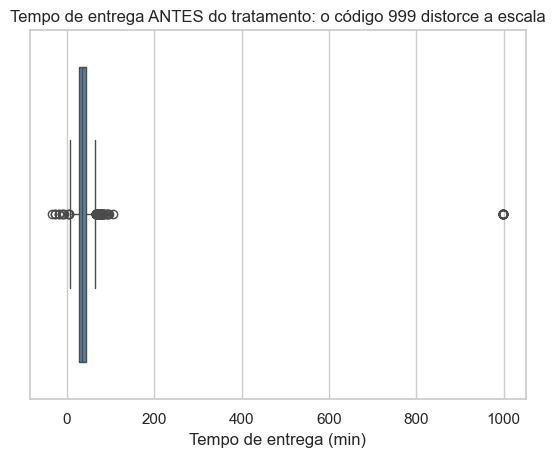

In [20]:
# Visualizar os tempos de entrega originais (antes do tratamento)
ax = sns.boxplot(x=df["tempo_entrega_min"], color="steelblue")

# Título e rótulo com unidade
ax.set_title("Tempo de entrega ANTES do tratamento: o código 999 distorce a escala")
ax.set_xlabel("Tempo de entrega (min)")

plt.show()

In [21]:
# Criar a flag para identificar tempos inválidos
df["tempo_invalido"] = (
    (df["tempo_entrega_min"] < 0) |
    (df["tempo_entrega_min"] == 999)
)

# Contar quantos registros são válidos e inválidos
print("Contagem dos registros:")
print(df["tempo_invalido"].value_counts())

# Substituir os tempos inválidos por NaN
df.loc[df["tempo_invalido"], "tempo_entrega_min"] = float("nan")

# Conferir quantos valores ausentes existem após o tratamento
print("\nValores ausentes após o tratamento:")
print(df["tempo_entrega_min"].isna().sum())

Contagem dos registros:
tempo_invalido
False    8025
True       33
Name: count, dtype: int64

Valores ausentes após o tratamento:
33


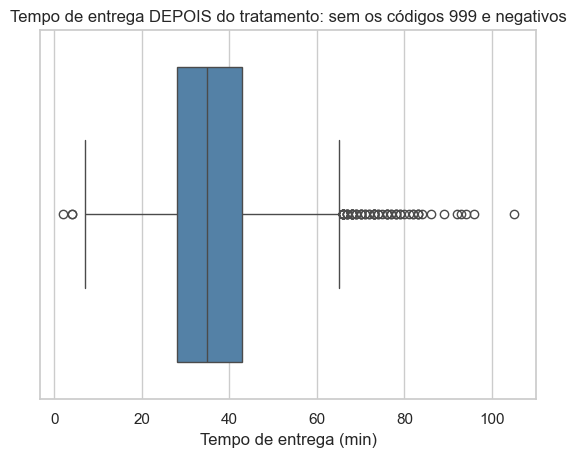

In [22]:
# Visualizar os tempos de entrega após substituir os inválidos por NaN
ax = sns.boxplot(x=df["tempo_entrega_min"], color="steelblue")

# Título e rótulo com unidade
ax.set_title("Tempo de entrega DEPOIS do tratamento: sem os códigos 999 e negativos")
ax.set_xlabel("Tempo de entrega (min)")

plt.show()


Ao analisar o primeiro boxplot, percebi que existiam valores extremos, incluindo tempos negativos e registros iguais a 999 minutos.

Identifiquei 33 registros problemáticos: 8 tempos negativos e 25 registros com valor 999.

Criei a coluna `tempo_invalido` para identificar esses pedidos e substituí os tempos problemáticos por `NaN`, sem excluir os pedidos da base.

Depois do tratamento, gerei um novo boxplot e observei que a distribuição ficou mais fácil de visualizar.

Mantive os demais tempos elevados, porque um valor extremo, como 90 minutos, não significa necessariamente que exista um erro.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [23]:
# Mostrar as informações estatísticas das distâncias

distancias = df["distancia_km"].describe()

print("=== ESTATÍSTICAS DAS DISTÂNCIAS ===")

print(f"Quantidade de distâncias válidas: {distancias['count']:.0f}")
print(f"Distância média: {distancias['mean']:.2f} km")
print(f"Desvio padrão: {distancias['std']:.2f} km")
print(f"Menor distância: {distancias['min']:.2f} km")
print(f"25% dos pedidos até: {distancias['25%']:.2f} km")
print(f"Mediana (50% dos pedidos até): {distancias['50%']:.2f} km")
print(f"75% dos pedidos até: {distancias['75%']:.2f} km")
print(f"Maior distância: {distancias['max']:.2f} km")


=== ESTATÍSTICAS DAS DISTÂNCIAS ===
Quantidade de distâncias válidas: 7743
Distância média: 3.80 km
Desvio padrão: 9.41 km
Menor distância: 0.08 km
25% dos pedidos até: 1.77 km
Mediana (50% dos pedidos até): 3.03 km
75% dos pedidos até: 4.77 km
Maior distância: 399.65 km


In [24]:
# Calcular os quartis
q1 = df["distancia_km"].quantile(0.25)
q3 = df["distancia_km"].quantile(0.75)

# Calcular o IQR
iqr = q3 - q1

# Calcular o limite superior
limite_superior = q3 + (1.5 * iqr)

# Identificar distâncias acima do limite
distancias_extremas = df["distancia_km"] > limite_superior

# Mostrar os resultados
print("=== RESULTADO DO IQR ===")
print(f"Primeiro quartil (25%): {q1:.2f} km")
print(f"Terceiro quartil (75%): {q3:.2f} km")
print(f"IQR (diferença entre os quartis): {iqr:.2f} km")
print(f"Limite superior: {limite_superior:.2f} km")
print(f"Pedidos acima do limite: {distancias_extremas.sum()}")


=== RESULTADO DO IQR ===
Primeiro quartil (25%): 1.77 km
Terceiro quartil (75%): 4.77 km
IQR (diferença entre os quartis): 3.00 km
Limite superior: 9.27 km
Pedidos acima do limite: 194


In [25]:
# Calcular a média e o desvio padrão
media = df["distancia_km"].mean()
desvio = df["distancia_km"].std()

# Calcular o z-score
z_score = (df["distancia_km"] - media) / desvio

# Identificar valores com z-score maior que 3
pedidos_zscore = z_score > 3

# Mostrar os resultados
print("=== RESULTADO DO Z-SCORE ===")
print(f"Distância média: {media:.2f} km")
print(f"Desvio padrão: {desvio:.2f} km")
print(f"Pedidos com z-score maior que 3: {pedidos_zscore.sum()}")


=== RESULTADO DO Z-SCORE ===
Distância média: 3.80 km
Desvio padrão: 9.41 km
Pedidos com z-score maior que 3: 7


In [26]:
# Mostrar os pedidos com distâncias muito altas
print("=== PEDIDOS COM DISTÂNCIAS MUITO ALTAS ===")

# Mostrar o número do pedido, cidade, distância e tempo
display(
    df.loc[
        pedidos_zscore,
        ["pedido_id", "cidade", "distancia_km", "tempo_entrega_min"]
    ]
)


=== PEDIDOS COM DISTÂNCIAS MUITO ALTAS ===


,pedido_id,cidade,distancia_km,tempo_entrega_min
706,500706,São Paulo,391.89,23.0
1539,501539,Belo Horizonte,300.21,43.0
3242,503242,São Paulo,399.65,25.0
3926,503926,São Paulo,369.22,56.0
5749,505749,Rio de Janeiro,163.23,29.0
5826,505826,São Paulo,252.99,54.0
7133,507133,São Paulo,160.26,20.0


In [27]:
# Marcar as distâncias consideradas inválidas
df["distancia_invalida"] = pedidos_zscore

# Mostrar quantos pedidos foram marcados
print("=== VERIFICAÇÃO DAS DISTÂNCIAS ===")
print(f"Pedidos com distâncias inválidas: {df['distancia_invalida'].sum()}")

# Substituir as distâncias inválidas por NaN
df.loc[df["distancia_invalida"], "distancia_km"] = float("nan")

# Contar os valores ausentes depois do tratamento
total_ausentes = df["distancia_km"].isna().sum()

print(f"Total de distâncias ausentes após o tratamento: {total_ausentes}")
print(f"Total de pedidos mantidos na base: {len(df)}")


=== VERIFICAÇÃO DAS DISTÂNCIAS ===
Pedidos com distâncias inválidas: 7
Total de distâncias ausentes após o tratamento: 322
Total de pedidos mantidos na base: 8058


Usei dois métodos para encontrar distâncias muito altas: IQR e z-score.

O IQR encontrou 194 pedidos com distâncias acima de 9,27 km. Já o z-score maior que 3 encontrou apenas 7 pedidos.

Ao verificar esses 7 pedidos, encontrei distâncias entre 160,26 km e 399,65 km, com tempos de entrega entre 20 e 56 minutos. Essas distâncias não parecem possíveis para entregas comuns de comida.

Para confirmar, usei a fórmula da taxa de entrega que encontrei mais adiante, na Tarefa 8.3 (R\$ 4,99 fixos mais R\$ 0,90 por quilômetro). Em 6 desses 7 pedidos, a taxa cobrada corresponde a distâncias entre 1,1 km e 6,9 km, e não a 160 km ou mais. O sétimo pedido teve frete grátis, então a taxa não ajuda, mas um tempo de entrega de 23 minutos também é incompatível com 391,89 km. Isso reforça que esses valores são erros de registro, e não entregas reais muito longas.

O z-score usa a média e o desvio padrão, que também podem ser influenciados por valores muito altos. Por isso, também comparei as distâncias com os tempos de entrega.

Decidi marcar esses 7 pedidos como inválidos na coluna `distancia_invalida` e substituir suas distâncias por `NaN`, sem excluir os pedidos.

Mantive as outras distâncias porque podem representar entregas reais.

Depois do tratamento, a coluna `distancia_km` ficou com 322 valores ausentes, contando os 315 que já existiam.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [28]:
# IQR GLOBAL

q1 = df["valor_pedido"].quantile(0.25)
q3 = df["valor_pedido"].quantile(0.75)

limite_global = q3 + 1.5 * (q3 - q1)

outlier_global = df["valor_pedido"] > limite_global

print(f"Limite global: R$ {limite_global:.2f}")
print(f"Total sinalizado: {outlier_global.sum()}")

print("\nOutliers por cozinha:")
print(df.assign(outlier=outlier_global)
        .groupby("tipo_cozinha")["outlier"].sum())

Limite global: R$ 144.97
Total sinalizado: 352

Outliers por cozinha:
tipo_cozinha
Brasileira      6
Doces           3
Hambúrguer     19
Japonesa      246
Pizza          70
Saudável        8
Name: outlier, dtype: int64


In [29]:
# IQR POR COZINHA

grupo = df.groupby("tipo_cozinha")["valor_pedido"]

q1 = grupo.quantile(0.25)
q3 = grupo.quantile(0.75)

limites = q3 + 1.5 * (q3 - q1)

outlier_cozinha = (
    df["valor_pedido"] > df["tipo_cozinha"].map(limites)
)

print("Outliers por cozinha:")
print(df.assign(outlier=outlier_cozinha)
        .groupby("tipo_cozinha")["outlier"].sum())

print(f"\nTotal sinalizado: {outlier_cozinha.sum()}")

Outliers por cozinha:
tipo_cozinha
Brasileira    38
Doces         18
Hambúrguer    43
Japonesa      24
Pizza         60
Saudável      31
Name: outlier, dtype: int64

Total sinalizado: 214


In [30]:
# Z-SCORE E COMPARAÇÃO FINAL

media = df["valor_pedido"].mean()
desvio = df["valor_pedido"].std()

z_score = (df["valor_pedido"] - media) / desvio

print(f"IQR global:      {outlier_global.sum():>4} - Pedidos sinalizados na base inteira.")
print(f"IQR por cozinha: {outlier_cozinha.sum():>4} - Pedidos sinalizados dentro de cada cozinha.")
print(f"Z-score > 3:     {(z_score > 3).sum():>4} - Pedidos muito distantes da média.")

IQR global:       352 - Pedidos sinalizados na base inteira.
IQR por cozinha:  214 - Pedidos sinalizados dentro de cada cozinha.
Z-score > 3:       31 - Pedidos muito distantes da média.



Ao aplicar o IQR na base inteira, encontrei 352 pedidos com valores extremos.

Quando apliquei o IQR separadamente para cada tipo de cozinha, encontrei 214 pedidos. Essa diferença aconteceu porque cada cozinha possui uma faixa de preços diferente.

Na cozinha Japonesa, por exemplo, os pedidos sinalizados diminuíram de 246 para 24, pois os valores normalmente são mais altos nessa categoria.

Já o z-score maior que 3 identificou apenas 31 pedidos, mostrando que os métodos utilizam critérios diferentes.

Concluí que um pedido com valor elevado não significa necessariamente um erro. É importante considerar o tipo de cozinha antes de classificar um pedido como extremo.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [31]:
# ============================================================
# TAREFA 4.4 - PASSO 1: MEDIANA POR TIPO DE COZINHA
# ============================================================

# Agrupar os pedidos por tipo de cozinha e calcular a mediana
mediana_cozinha = (
    df.groupby("tipo_cozinha")["valor_pedido"]
    .median()
)

# Mostrar o resultado com uma explicação na mesma linha
print("MEDIANA DOS PEDIDOS POR TIPO DE COZINHA")
print("-" * 90)

for cozinha, mediana in mediana_cozinha.items():
    print(
        f"{cozinha:<15} R$ {mediana:>8.2f}"
        f"  - Valor central dos pedidos da cozinha {cozinha}."
    )

MEDIANA DOS PEDIDOS POR TIPO DE COZINHA
------------------------------------------------------------------------------------------
Brasileira      R$    47.82  - Valor central dos pedidos da cozinha Brasileira.
Doces           R$    38.42  - Valor central dos pedidos da cozinha Doces.
Hambúrguer      R$    61.67  - Valor central dos pedidos da cozinha Hambúrguer.
Japonesa        R$   107.97  - Valor central dos pedidos da cozinha Japonesa.
Pizza           R$    74.31  - Valor central dos pedidos da cozinha Pizza.
Saudável        R$    53.73  - Valor central dos pedidos da cozinha Saudável.


In [32]:
# ============================================================
# TAREFA 4.4 - PASSO 2: RAZÃO ENTRE VALOR E MEDIANA
# ============================================================

# Calcular a mediana correspondente à cozinha de cada pedido
mediana_por_pedido = (
    df.groupby("tipo_cozinha")["valor_pedido"]
    .transform("median")
)

# Dividir o valor de cada pedido pela mediana da sua cozinha
df["razao_mediana"] = df["valor_pedido"] / mediana_por_pedido

# Mostrar os cinco pedidos com as maiores razões
maiores_razoes = df.nlargest(5, "razao_mediana")

# Exibir os resultados com explicação na mesma linha
print("MAIORES RAZÕES ENTRE VALOR E MEDIANA")
print("-" * 95)

for _, pedido in maiores_razoes.iterrows():
    print(
        f"Pedido {pedido['pedido_id']}  "
        f"Razão: {pedido['razao_mediana']:.2f}x"
        f"  - Custa {pedido['razao_mediana']:.2f} vezes "
        f"a mediana da cozinha {pedido['tipo_cozinha']}."
    )

MAIORES RAZÕES ENTRE VALOR E MEDIANA
-----------------------------------------------------------------------------------------------
Pedido 506904  Razão: 30.94x  - Custa 30.94 vezes a mediana da cozinha Pizza.
Pedido 503553  Razão: 20.45x  - Custa 20.45 vezes a mediana da cozinha Japonesa.
Pedido 504023  Razão: 19.41x  - Custa 19.41 vezes a mediana da cozinha Pizza.
Pedido 506787  Razão: 17.38x  - Custa 17.38 vezes a mediana da cozinha Hambúrguer.
Pedido 500491  Razão: 13.93x  - Custa 13.93 vezes a mediana da cozinha Pizza.


In [33]:
# ============================================================
# TAREFA 4.4 - PASSO 3: IDENTIFICAR SALTOS ENTRE AS RAZÕES
# ============================================================

# Selecionar as 30 maiores razões em ordem decrescente
# (precisamos ver mais posições para encontrar onde a "escada" para)
top_razoes = df["razao_mediana"].nlargest(30).reset_index(drop=True)

# Calcular a diferença entre cada razão e a próxima
saltos = top_razoes - top_razoes.shift(-1)

# Mostrar cada razão e a diferença para a próxima
print("MAIORES RAZÕES E SEUS SALTOS")
print("-" * 85)

for i in range(len(top_razoes) - 1):
    print(
        f"Posição {i + 1:>2}  "
        f"Razão: {top_razoes.iloc[i]:>6.2f}x  "
        f"Salto: {saltos.iloc[i]:>6.2f}x"
        "  - Diferença para a próxima razão."
    )

MAIORES RAZÕES E SEUS SALTOS
-------------------------------------------------------------------------------------
Posição  1  Razão:  30.94x  Salto:  10.49x  - Diferença para a próxima razão.
Posição  2  Razão:  20.45x  Salto:   1.04x  - Diferença para a próxima razão.
Posição  3  Razão:  19.41x  Salto:   2.03x  - Diferença para a próxima razão.
Posição  4  Razão:  17.38x  Salto:   3.45x  - Diferença para a próxima razão.
Posição  5  Razão:  13.93x  Salto:   0.77x  - Diferença para a próxima razão.
Posição  6  Razão:  13.16x  Salto:   0.24x  - Diferença para a próxima razão.
Posição  7  Razão:  12.92x  Salto:   0.07x  - Diferença para a próxima razão.
Posição  8  Razão:  12.85x  Salto:   1.48x  - Diferença para a próxima razão.
Posição  9  Razão:  11.37x  Salto:   1.22x  - Diferença para a próxima razão.
Posição 10  Razão:  10.15x  Salto:   0.20x  - Diferença para a próxima razão.
Posição 11  Razão:   9.95x  Salto:   0.72x  - Diferença para a próxima razão.
Posição 12  Razão:   9.23x 

In [34]:
# ============================================================
# TAREFA 4.4 - PASSO 4: INVESTIGAÇÃO DOS PEDIDOS ACIMA DO SALTO
# ============================================================

# Limite escolhido pelo salto: entre 4,28x e 3,35x
limite_pedido_grande = 4

# Selecionar os pedidos acima do limite, do maior para o menor
pedidos_investigar = df[df["razao_mediana"] > limite_pedido_grande]
pedidos_investigar = pedidos_investigar.sort_values("razao_mediana", ascending=False)

# Escolher as informações para investigação
colunas = [
    "pedido_id",
    "data_hora",
    "cidade",
    "tipo_cozinha",
    "valor_pedido",
    "razao_mediana",
    "distancia_km",
    "taxa_entrega",
    "tempo_entrega_min"
]

print(f"Pedidos acima de {limite_pedido_grande}x a mediana: {len(pedidos_investigar)}")
display(pedidos_investigar[colunas])

# Resumo rápido para saber se parecem entregas normais
print("\nTaxa de entrega: de R$", pedidos_investigar["taxa_entrega"].min(),
      "até R$", pedidos_investigar["taxa_entrega"].max())
print("Tempo de entrega: de", pedidos_investigar["tempo_entrega_min"].min(),
      "até", pedidos_investigar["tempo_entrega_min"].max(), "minutos")

# Quantos pedidos grandes em cada cozinha
print("\nPedidos grandes por cozinha:")
print(pedidos_investigar["tipo_cozinha"].value_counts())

Pedidos acima de 4x a mediana: 26


,pedido_id,data_hora,cidade,tipo_cozinha,valor_pedido,razao_mediana,distancia_km,taxa_entrega,tempo_entrega_min
6904,506904,2024-11-17 11:07:00,Rio de Janeiro,Pizza,2299.10,30.941390,2.03,6.82,25.0
3553,503553,2024-06-24 19:48:00,São Paulo,Japonesa,2207.79,20.448180,0.89,5.79,18.0
4023,504023,2024-07-14 12:46:00,São Paulo,Pizza,1441.97,19.406096,0.76,0.00,27.0
6787,506787,2024-11-12 17:33:00,Rio de Janeiro,Hambúrguer,1071.77,17.379115,2.60,7.33,24.0
491,500491,2024-01-24 20:59:00,São Paulo,Pizza,1035.26,13.932575,2.13,6.91,34.0
3246,503246,2024-06-09 20:38:00,São Paulo,Doces,505.64,13.159141,1.30,0.00,29.0
1035,501035,2024-02-23 19:48:00,São Paulo,Japonesa,1394.73,12.917755,2.35,7.10,39.0
1263,501263,2024-03-04 12:43:00,São Paulo,Brasileira,614.31,12.846299,4.75,9.27,51.0
1736,501736,2024-03-27 14:45:00,Rio de Janeiro,Hambúrguer,700.91,11.365494,11.92,15.72,59.0
4045,504045,2024-07-15 12:21:00,São Paulo,Hambúrguer,625.71,10.146100,1.04,5.93,24.0



Taxa de entrega: de R$ 0.0 até R$ 23.9
Tempo de entrega: de 16.0 até 93.0 minutos

Pedidos grandes por cozinha:
tipo_cozinha
Brasileira    6
Japonesa      5
Pizza         4
Hambúrguer    4
Saudável      4
Doces         3
Name: count, dtype: int64


In [35]:
# ============================================================
# TAREFA 4.4 - PASSO 5: CRIAR A FLAG PEDIDO_GRANDE
# ============================================================

# Criar a flag booleana usando o limite do Passo 4:
# True  = pedido acima de 4 vezes a mediana da sua cozinha
# False = pedido não ultrapassou esse limite
df["pedido_grande"] = df["razao_mediana"] > limite_pedido_grande

# Contar quantos pedidos foram e não foram sinalizados
quantidade_grandes = df["pedido_grande"].sum()
quantidade_nao_grandes = (~df["pedido_grande"]).sum()

print("RESULTADO DA FLAG PEDIDO_GRANDE")
print("-" * 95)
print(f"True      {quantidade_grandes:>5} pedidos  - Pedidos acima de {limite_pedido_grande} vezes a mediana da sua cozinha.")
print(f"False     {quantidade_nao_grandes:>5} pedidos  - Pedidos que não ultrapassaram o limite.")
print(f"Total     {len(df):>5} pedidos  - Todos os pedidos foram preservados na base.")

RESULTADO DA FLAG PEDIDO_GRANDE
-----------------------------------------------------------------------------------------------
True         26 pedidos  - Pedidos acima de 4 vezes a mediana da sua cozinha.
False      8032 pedidos  - Pedidos que não ultrapassaram o limite.
Total      8058 pedidos  - Todos os pedidos foram preservados na base.


Calculei a razão entre o valor de cada pedido e a mediana da sua cozinha, para comparar cozinhas com preços diferentes.

A maior razão foi de 30,94 vezes a mediana (pedido 506904, uma pizza de R\$ 2.299,10).

Ao ordenar as 30 maiores razões, procurei onde os valores param de cair aos poucos. O salto aparece entre a posição 26 (4,28x) e a posição 27 (3,35x). Daí para baixo, as diferenças entre um pedido e o próximo ficam quase zero, ou seja, são pedidos comuns. Por isso usei **4 vezes a mediana** como limite.

Com esse limite encontrei **26 pedidos**, cerca de 0,32% da base, distribuídos em todas as seis cozinhas.

Ao examinar esses pedidos, vi que as taxas de entrega (de R\$ 0,00 a R\$ 23,90) e os tempos de entrega (de 16 a 93 minutos) parecem de entregas normais. Se fossem erros de digitação, eu esperaria ver algo estranho junto, como distância ou tempo impossíveis, e isso não aconteceu.

Por isso entendi que esses pedidos parecem pedidos grandes reais, como pedidos de empresas ou de festas. Mesmo assim, não tenho como confirmar isso só com estes dados.

Decidi **manter todos os pedidos** e criar a coluna `pedido_grande`, marcando como `True` os 26 pedidos acima de 4 vezes a mediana da sua cozinha. Essa coluna serve para identificar esses pedidos, e não para dizer que são erros.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [36]:
# ============================================================
# TAREFA 4.5 - PASSO 1: MÉDIA E MEDIANA COM TODOS OS PEDIDOS
# ============================================================

# Calcular a média considerando todos os pedidos
media_geral = df["valor_pedido"].mean()

# Calcular a mediana considerando todos os pedidos
mediana_geral = df["valor_pedido"].median()

# Mostrar os resultados com explicações na mesma linha
print("MÉDIA E MEDIANA - BASE COMPLETA")
print("-" * 90)

print(
    f"Média       R$ {media_geral:>8.2f}"
    "  - Valor médio considerando todos os pedidos."
)

print(
    f"Mediana     R$ {mediana_geral:>8.2f}"
    "  - Valor central dos pedidos, menos afetado por valores extremos."
)

print(
    f"Pedidos        {len(df):>8}"
    "  - Quantidade de pedidos considerados nesta análise."
)


MÉDIA E MEDIANA - BASE COMPLETA
------------------------------------------------------------------------------------------
Média       R$    71.55  - Valor médio considerando todos os pedidos.
Mediana     R$    61.61  - Valor central dos pedidos, menos afetado por valores extremos.
Pedidos            8058  - Quantidade de pedidos considerados nesta análise.


In [37]:
# ============================================================
# TAREFA 4.5 - PASSO 2: SEM OS PEDIDOS GRANDES
# ============================================================

# Selecionar somente os pedidos não marcados como grandes
# O símbolo ~ significa NÃO, invertendo True e False
pedidos_comuns = df.loc[~df["pedido_grande"]]

# Calcular a média dos pedidos não sinalizados como grandes
media_sem_grandes = pedidos_comuns["valor_pedido"].mean()

# Calcular a mediana dos pedidos não sinalizados como grandes
mediana_sem_grandes = pedidos_comuns["valor_pedido"].median()

# Mostrar os resultados acompanhados das explicações
print("MÉDIA E MEDIANA - SEM PEDIDOS GRANDES")
print("-" * 90)

print(
    f"Média       R$ {media_sem_grandes:>8.2f}"
    "  - Valor médio sem os pedidos sinalizados como grandes."
)

print(
    f"Mediana     R$ {mediana_sem_grandes:>8.2f}"
    "  - Valor central dos pedidos não sinalizados."
)

print(
    f"Pedidos        {len(pedidos_comuns):>8}"
    "  - Quantidade de pedidos considerada nesta comparação."
)

MÉDIA E MEDIANA - SEM PEDIDOS GRANDES
------------------------------------------------------------------------------------------
Média       R$    69.37  - Valor médio sem os pedidos sinalizados como grandes.
Mediana     R$    61.48  - Valor central dos pedidos não sinalizados.
Pedidos            8032  - Quantidade de pedidos considerada nesta comparação.


In [38]:
# ============================================================
# TAREFA 4.5 - PASSO 3: COMPARAÇÃO POR TIPO DE COZINHA
# ============================================================

# Calcular média e mediana com todos os pedidos
com_grandes = df.groupby("tipo_cozinha")["valor_pedido"].agg(
    media="mean",
    mediana="median"
)

# Calcular média e mediana sem os pedidos grandes
sem_grandes = pedidos_comuns.groupby("tipo_cozinha")["valor_pedido"].agg(
    media="mean",
    mediana="median"
)

# Mostrar os resultados com explicação ao lado
print("COMPARAÇÃO POR TIPO DE COZINHA")
print("-" * 110)

for cozinha in com_grandes.index:

    media_com = com_grandes.loc[cozinha, "media"]
    media_sem = sem_grandes.loc[cozinha, "media"]

    mediana_com = com_grandes.loc[cozinha, "mediana"]
    mediana_sem = sem_grandes.loc[cozinha, "mediana"]

    print(f"\n{cozinha}")

    print(
        f"  Média    R$ {media_com:>7.2f} → R$ {media_sem:>7.2f}"
        f"  - Diminuiu R$ {media_com - media_sem:.2f} sem os pedidos grandes."
    )

    print(
        f"  Mediana  R$ {mediana_com:>7.2f} → R$ {mediana_sem:>7.2f}"
        f"  - Diminuiu R$ {mediana_com - mediana_sem:.2f} sem os pedidos grandes."
    )

COMPARAÇÃO POR TIPO DE COZINHA
--------------------------------------------------------------------------------------------------------------

Brasileira
  Média    R$   51.17 → R$   49.94  - Diminuiu R$ 1.22 sem os pedidos grandes.
  Mediana  R$   47.82 → R$   47.75  - Diminuiu R$ 0.07 sem os pedidos grandes.

Doces
  Média    R$   41.79 → R$   40.64  - Diminuiu R$ 1.15 sem os pedidos grandes.
  Mediana  R$   38.42 → R$   38.40  - Diminuiu R$ 0.02 sem os pedidos grandes.

Hambúrguer
  Média    R$   67.65 → R$   66.25  - Diminuiu R$ 1.40 sem os pedidos grandes.
  Mediana  R$   61.67 → R$   61.61  - Diminuiu R$ 0.06 sem os pedidos grandes.

Japonesa
  Média    R$  120.37 → R$  115.38  - Diminuiu R$ 4.98 sem os pedidos grandes.
  Mediana  R$  107.97 → R$  107.73  - Diminuiu R$ 0.24 sem os pedidos grandes.

Pizza
  Média    R$   82.79 → R$   79.91  - Diminuiu R$ 2.88 sem os pedidos grandes.
  Mediana  R$   74.31 → R$   74.28  - Diminuiu R$ 0.03 sem os pedidos grandes.

Saudável
  Média   

Comparei a média e a mediana do valor dos pedidos com e sem os 26 pedidos grandes.

Na base completa, a média foi de R\$ 71,55. Sem os pedidos grandes, caiu para R\$ 69,37, uma diferença de R\$ 2,18.

A mediana quase não mudou, passando de R\$ 61,61 para R\$ 61,48.

Por tipo de cozinha, as maiores quedas na média foram na Japonesa (R\$ 4,98) e na Pizza (R\$ 2,88). As medianas também mudaram muito pouco.

Percebi que apenas 26 pedidos, que representam 0,32% da base, já conseguem aumentar a média, mas quase não alteram a mediana.

Por isso, escolhi a **mediana para representar o ticket típico**, pois ela é menos afetada por valores muito altos.

Mantive todos os pedidos na base, porque não tenho informações suficientes para afirmar que são erros.

In [39]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [40]:
# ============================================================
# TAREFA 5.1 - RESUMO ESTATÍSTICO COMPLETO
# ============================================================

# Selecionar as cinco variáveis numéricas solicitadas
colunas_numericas = [
    "valor_pedido", "taxa_entrega", "distancia_km",
    "tempo_entrega_min", "avaliacao"
]

# O describe() calcula contagem, média, desvio padrão e quartis
# O .T coloca uma variável em cada linha
resumo = df[colunas_numericas].describe().T

# IQR: amplitude entre o primeiro e o terceiro quartil
resumo["IQR"] = resumo["75%"] - resumo["25%"]

# CV: desvio padrão em relação à média, em porcentagem
resumo["CV (%)"] = (resumo["std"] / resumo["mean"]) * 100

# Assimetria: indica a direção da cauda da distribuição
resumo["Assimetria"] = df[colunas_numericas].skew()

# Moda: valor mais frequente; em caso de empate, mostra a primeira moda
resumo["Moda"] = df[colunas_numericas].mode().iloc[0]

# Organizar e exibir as estatísticas em uma única tabela
colunas_resumo = [
    "count", "mean", "std", "min", "25%", "50%", "75%", "max",
    "IQR", "CV (%)", "Assimetria", "Moda"
]

print("RESUMO ESTATÍSTICO COMPLETO - TAREFA 5.1")
display(resumo[colunas_resumo].round(2))


RESUMO ESTATÍSTICO COMPLETO - TAREFA 5.1


,count,mean,std,min,25%,50%,75%,max,IQR,CV (%),Assimetria,Moda
valor_pedido,8058.0,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,48.52
taxa_entrega,8058.0,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0.00
distancia_km,7736.0,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.70
tempo_entrega_min,8025.0,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34.00
avaliacao,6716.0,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5.00


### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

**Questão (a):** A variável `valor_pedido` apresenta a maior assimetria (17,52), devido à presença de pedidos com valores muito altos. Por isso, a mediana é mais adequada que a média para representar o valor de um pedido típico.

**Questão (b):** A variável `valor_pedido` apresenta a maior variabilidade relativa, com coeficiente de variação de 84,22%. Isso indica que os valores dos pedidos possuem uma dispersão elevada em relação à média.

**Questão (c):** A moda de `taxa_entrega` é R$ 0,00, indicando que a entrega gratuita é um dos valores mais frequentes na base de dados. Entretanto, isso não significa que a maioria dos pedidos tenha recebido frete grátis.

**Questão (d):** A avaliação média de 4,35 estrelas é alta, indicando uma percepção geralmente positiva entre os pedidos avaliados. Entretanto, como 1.342 pedidos não possuem avaliação, não é possível afirmar que todos os clientes ficaram satisfeitos.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [41]:
# ============================================================
# TAREFA 5.3 - MODA E DISTRIBUIÇÃO PERCENTUAL (CATEGÓRICAS)
# ============================================================

# Organizar as quatro variáveis categóricas solicitadas
colunas_categoricas = [
    "cidade", "tipo_cozinha", "forma_pagamento", "plataforma"
]

# Apresentações específicas, sem repetir os cálculos
nomes = {
    "cidade": ("CIDADE", "Cidade com maior quantidade de pedidos."),
    "tipo_cozinha": ("TIPO DE COZINHA", "Tipo de cozinha mais frequente."),
    "forma_pagamento": ("FORMA DE PAGAMENTO", "Forma de pagamento mais frequente."),
    "plataforma": ("PLATAFORMA", "Plataforma mais frequente.")
}

# Analisar cada variável usando o mesmo procedimento
for coluna in colunas_categoricas:

    # Incluir valores ausentes na contagem e no percentual
    quantidade = df[coluna].value_counts(dropna=False)
    percentual = df[coluna].value_counts(normalize=True, dropna=False) * 100

    # A primeira categoria é uma das modas; pode haver empates
    moda = quantidade.index[0]
    titulo, explicacao = nomes[coluna]

    print(f"\nDISTRIBUIÇÃO DOS PEDIDOS POR {titulo}")
    print("-" * 90)

    # Exibir quantidade e participação percentual na mesma linha
    for categoria in quantidade.index:
        qtd = quantidade[categoria]
        pct = percentual[categoria]
        print(
            f"{str(categoria):<20} {qtd:>5} pedidos | {pct:>6.2f}%"
            " - Participação no total de pedidos."
        )

    print("-" * 90)
    print(f"Moda: {moda} - {explicacao}")



DISTRIBUIÇÃO DOS PEDIDOS POR CIDADE
------------------------------------------------------------------------------------------
São Paulo             4055 pedidos |  50.32% - Participação no total de pedidos.
Rio de Janeiro        2371 pedidos |  29.42% - Participação no total de pedidos.
Belo Horizonte        1632 pedidos |  20.25% - Participação no total de pedidos.
------------------------------------------------------------------------------------------
Moda: São Paulo - Cidade com maior quantidade de pedidos.

DISTRIBUIÇÃO DOS PEDIDOS POR TIPO DE COZINHA
------------------------------------------------------------------------------------------
Hambúrguer            1921 pedidos |  23.84% - Participação no total de pedidos.
Pizza                 1786 pedidos |  22.16% - Participação no total de pedidos.
Brasileira            1561 pedidos |  19.37% - Participação no total de pedidos.
Japonesa              1116 pedidos |  13.85% - Participação no total de pedidos.
Saudável           

A análise das variáveis categóricas mostrou que:

- **Cidade:** São Paulo concentra a maior quantidade de pedidos (50,32%).
- **Tipo de cozinha:** Hambúrguer é a categoria mais frequente (23,84%).
- **Forma de pagamento:** Cartão de crédito é o meio mais utilizado (45,20%).
- **Plataforma:** Android apresenta a maior participação (55,21%).

Também foram identificados 153 registros (1,90%) com plataforma não informada.



### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [42]:
# ============================================================
# TAREFA 5.4 - PERCENTIS E PROMESSA OPERACIONAL
# ============================================================

# Selecionar somente os tempos válidos para os cálculos
# Os registros sem tempo permanecem no DataFrame original
tempos = df["tempo_entrega_min"].dropna()

# ------------------------------------------------------------
# 1. CALCULAR OS PERCENTIS
# ------------------------------------------------------------

percentis = tempos.quantile([0.50, 0.75, 0.90, 0.95])

print("PERCENTIS DO TEMPO DE ENTREGA")
print("-" * 85)

for percentual, tempo in percentis.items():

    print(
        f"P{percentual * 100:.0f}: {tempo:.0f} minutos"
        f" - Aproximadamente {percentual * 100:.0f}%"
        " das entregas válidas ocorreram até esse tempo."
    )

# ------------------------------------------------------------
# 2. CALCULAR ENTREGAS ACIMA DE 35 E 45 MINUTOS
# ------------------------------------------------------------

# Contar pedidos acima de cada limite
acima_35 = (tempos > 35).sum()
acima_45 = (tempos > 45).sum()

# Calcular percentuais usando somente tempos válidos
perc_35 = (tempos > 35).mean() * 100
perc_45 = (tempos > 45).mean() * 100

print("\nANÁLISE DOS TEMPOS DE ENTREGA")
print("-" * 85)

print(
    f"Acima de 35 min: {acima_35} pedidos | {perc_35:.2f}%"
    " - Percentual entre as entregas com tempo válido."
)

print(
    f"Acima de 45 min: {acima_45} pedidos | {perc_45:.2f}%"
    " - Percentual entre as entregas com tempo válido."
)

# ------------------------------------------------------------
# 3. ANALISAR A PROMESSA DE ENTREGA EM ATÉ 45 MINUTOS
# ------------------------------------------------------------

# Quantidade de registros sem tempo válido
sem_tempo = df["tempo_entrega_min"].isna().sum()

print("\nIMPACTO DA PROMESSA DE ENTREGA EM ATÉ 45 MIN")
print("-" * 85)

print(
    f"Promessa descumprida: {acima_45} pedidos | {perc_45:.2f}%"
    " - Entregas que ultrapassaram 45 minutos."
)

print(
    f"Sem tempo válido: {sem_tempo} pedidos"
    " - Não é possível verificar se cumpriram o prazo."
)

PERCENTIS DO TEMPO DE ENTREGA
-------------------------------------------------------------------------------------
P50: 35 minutos - Aproximadamente 50% das entregas válidas ocorreram até esse tempo.
P75: 43 minutos - Aproximadamente 75% das entregas válidas ocorreram até esse tempo.
P90: 50 minutos - Aproximadamente 90% das entregas válidas ocorreram até esse tempo.
P95: 55 minutos - Aproximadamente 95% das entregas válidas ocorreram até esse tempo.

ANÁLISE DOS TEMPOS DE ENTREGA
-------------------------------------------------------------------------------------
Acima de 35 min: 3908 pedidos | 48.70% - Percentual entre as entregas com tempo válido.
Acima de 45 min: 1476 pedidos | 18.39% - Percentual entre as entregas com tempo válido.

IMPACTO DA PROMESSA DE ENTREGA EM ATÉ 45 MIN
-------------------------------------------------------------------------------------
Promessa descumprida: 1476 pedidos | 18.39% - Entregas que ultrapassaram 45 minutos.
Sem tempo válido: 33 pedidos - Não

Os percentis do tempo de entrega foram P50 = 35 minutos, P75 = 43 minutos, P90 = 50 minutos e P95 = 55 minutos.

Entre as 8.025 entregas com tempo válido, 3.908 (48,70%) ultrapassaram 35 minutos e 1.476 (18,39%) ultrapassaram 45 minutos.

Se a empresa prometesse entregar em até 45 minutos, **1.476 pedidos teriam descumprido a promessa**, considerando os registros com tempo válido.

Os 33 pedidos sem tempo válido não puderam ser classificados quanto ao cumprimento do prazo.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [43]:
# ============================================================
# TAREFA 6.1 - PAINEL DE KPIS DE 2024
# ============================================================

# 1. Cálculos individuais das métricas
total_pedidos = len(df)
faturamento_itens = df['valor_pedido'].sum()
receita_taxa_entrega = df['taxa_entrega'].sum()
ticket_medio = df['valor_pedido'].mean()
ticket_mediano = df['valor_pedido'].median()

# Proporções (booleanas convertidas para porcentagem)
perc_cupom = df['cupom'].mean() * 100
perc_clientes_novos = df['cliente_novo'].mean() * 100
perc_frete_gratis = (df['taxa_entrega'] == 0).mean() * 100

# Métricas de tempo (considerando apenas valores válidos/não nulos)
tempo_medio_entrega = df['tempo_entrega_min'].mean()
total_tempos_validos = df['tempo_entrega_min'].notna().sum()
perc_entregas_acima_45min = (df['tempo_entrega_min'] > 45).sum() / total_tempos_validos * 100

# Métricas de avaliação
avaliacao_media = df['avaliacao'].mean()
perc_pedidos_avaliados = df['avaliacao'].notna().sum() / total_pedidos * 100

# 2. Montagem do dicionário e conversão para Series
kpis_2024 = pd.Series({
    'Nº de Pedidos': total_pedidos,
    'Faturamento em Itens (R$)': faturamento_itens,
    'Receita Taxa de Entrega (R$)': receita_taxa_entrega,
    'Ticket Médio (R$)': ticket_medio,
    'Ticket Mediano (R$)': ticket_mediano,
    '% Pedidos com Cupom': perc_cupom,
    '% Clientes Novos': perc_clientes_novos,
    '% Frete Grátis': perc_frete_gratis,
    'Tempo Médio de Entrega (min)': tempo_medio_entrega,
    '% Entregas > 45 min': perc_entregas_acima_45min,
    'Avaliação Média': avaliacao_media,
    '% Pedidos Avaliados': perc_pedidos_avaliados
})

# 3. Exibição formatada para melhor leitura
print("=== PAINEL DE KPIs - 2024 ===")
display(kpis_2024.round(2)) # Arredondamos para 2 casas decimais para facilitar a leitura

=== PAINEL DE KPIs - 2024 ===


Nº de Pedidos                     8058.00
Faturamento em Itens (R$)       576584.75
Receita Taxa de Entrega (R$)     58571.40
Ticket Médio (R$)                   71.55
Ticket Mediano (R$)                 61.61
% Pedidos com Cupom                 21.21
% Clientes Novos                    17.37
% Frete Grátis                      11.17
Tempo Médio de Entrega (min)        35.91
% Entregas > 45 min                 18.39
Avaliação Média                      4.35
% Pedidos Avaliados                 83.35
dtype: float64

A análise dos 8.058 pedidos realizados em 2024 apresentou um faturamento de R\$ 576.584,75 em itens vendidos e R\$ 58.571,40 em taxas de entrega.

O ticket médio foi de R\$ 71,55, enquanto o ticket mediano ficou em R\$ 61,61. Essa diferença indica que pedidos de maior valor influenciam a média, tornando a mediana uma medida mais representativa do valor típico dos pedidos.

Em relação ao comportamento dos clientes, 21,21% dos pedidos utilizaram cupons de desconto, 17,37% foram realizados por clientes novos e 11,17% tiveram frete grátis.

Na parte operacional, o tempo médio de entrega foi de 35,91 minutos. Entretanto, 18,39% das entregas com tempo válido ultrapassaram 45 minutos, indicando um ponto que merece atenção na análise da eficiência operacional.

Quanto à satisfação, a avaliação média foi de 4,35 em uma escala de 1 a 5, considerando somente os pedidos avaliados. Ao todo, 83,35% dos pedidos receberam avaliação.

**Conclui-se que** os indicadores permitem compreender o desempenho financeiro, operacional e a participação dos clientes no período analisado. Os resultados também apontam aspectos que merecem investigação nas próximas etapas, principalmente os tempos de entrega, o comportamento dos pedidos com cupom e as diferenças entre média e mediana do ticket.

### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [44]:

# ============================================================
# TAREFA 6.2 — RESUMO POR CIDADE (2024)
# Base: df, após limpeza das Etapas 3 e 4
# ============================================================

# 1. Agrupar os pedidos por cidade e calcular os indicadores
agg_cidade = df.groupby("cidade").agg(
    pedidos=("pedido_id", "count"),
    faturamento=("valor_pedido", "sum"),
    ticket_mediano=("valor_pedido", "median"),
    tempo_medio_entrega=("tempo_entrega_min", "mean"),
    avaliacao_media=("avaliacao", "mean"),
    perc_cupom=("cupom", lambda x: x.mean() * 100)
).reset_index()


# 2. Calcular a participação de cada cidade no total de pedidos
total_pedidos = agg_cidade["pedidos"].sum()

agg_cidade["participacao_pct"] = (
    agg_cidade["pedidos"] / total_pedidos * 100
)


# 3. Criar uma tabela com um registro por cidade e dia
# Assim, um dia com muitos pedidos não será contado várias vezes.
dias_com_chuva = (
    df.groupby(["cidade", "data"])["chuva"]
      .first()
      .reset_index()
)


# 4. Calcular o percentual de dias chuvosos em cada cidade
# True = 1 e False = 0, portanto a média fornece a proporção.
perc_dias_chuva = (
    dias_com_chuva.groupby("cidade")["chuva"]
                  .mean() * 100
).reset_index()

# Renomear a coluna para facilitar a interpretação
perc_dias_chuva = perc_dias_chuva.rename(
    columns={"chuva": "perc_dias_chuva"}
)


# 5. Juntar os indicadores com os percentuais de chuva
# A coluna "cidade" identifica os registros correspondentes.
tabela_cidade = agg_cidade.merge(
    perc_dias_chuva,
    on="cidade",
    how="left",
    validate="one_to_one"
)


# 6. Organizar as colunas na ordem solicitada
tabela_cidade = tabela_cidade[[
    "cidade",
    "pedidos",
    "participacao_pct",
    "faturamento",
    "ticket_mediano",
    "tempo_medio_entrega",
    "avaliacao_media",
    "perc_cupom",
    "perc_dias_chuva"
]]


# 7. Ordenar da cidade com mais pedidos para a com menos pedidos
tabela_cidade = tabela_cidade.sort_values(
    "pedidos",
    ascending=False
).reset_index(drop=True)


# 8. Verificar os resultados
assert tabela_cidade["pedidos"].sum() == len(df)
assert len(tabela_cidade) == df["cidade"].nunique()
assert tabela_cidade["perc_dias_chuva"].notna().all()


# 9. Exibir a tabela formatada
# 9. Exibir a tabela com os resultados arredondados
print("=== RESUMO POR CIDADE — 2024 ===")

display(tabela_cidade.round(2))



=== RESUMO POR CIDADE — 2024 ===


,cidade,pedidos,participacao_pct,faturamento,ticket_mediano,tempo_medio_entrega,avaliacao_media,perc_cupom,perc_dias_chuva
0,São Paulo,4055,50.32,289275.55,61.54,35.86,4.35,21.60,25.21
1,Rio de Janeiro,2371,29.42,172029.24,61.43,35.71,4.36,20.75,24.45
2,Belo Horizonte,1632,20.25,115279.96,62.04,36.34,4.34,20.89,26.39


A análise dos 8.058 pedidos realizados em 2024 mostrou que São Paulo concentrou o maior volume de pedidos, com 4.055 registros (50,32%), e o maior faturamento, totalizando R\$ 289.275,55.

O Rio de Janeiro apresentou 2.371 pedidos (29,42%), com faturamento de R\$ 172.029,24. Já Belo Horizonte registrou 1.632 pedidos (20,25%) e faturamento de R\$ 115.279,96.

Em relação ao ticket mediano, Belo Horizonte apresentou o maior valor, aproximadamente R\$ 62,05, enquanto o Rio de Janeiro registrou o menor, com R\$ 61,43.

Os tempos médios de entrega foram semelhantes entre as cidades, variando de 35,71 a 36,34 minutos. As avaliações médias também apresentaram pouca diferença, ficando entre 4,34 e 4,36 pontos.

Quanto ao uso de cupons, São Paulo apresentou o maior percentual, com 21,60% dos pedidos. Na análise de chuva, Belo Horizonte registrou o maior percentual de dias observados com chuva (26,39%).

**Conclui-se que** São Paulo possui maior representatividade financeira e operacional na base analisada. Entretanto, o maior volume de pedidos não significa necessariamente maior ticket mediano ou menor tempo de entrega.


### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [45]:
# ============================================================
# TAREFA 6.3 — RESUMO POR TIPO DE COZINHA (2024)
# Base: df, após limpeza das Etapas 3 e 4
# ============================================================

# 1. Agrupar os pedidos por tipo de cozinha
# A named aggregation permite calcular vários indicadores.
por_cozinha = (
    df.groupby("tipo_cozinha")
      .agg(
          pedidos=("pedido_id", "count"),
          ticket_medio=("valor_pedido", "mean"),
          ticket_mediano=("valor_pedido", "median"),
          faturamento=("valor_pedido", "sum")
      )
)

# 2. Calcular a participação no faturamento total
faturamento_total = por_cozinha["faturamento"].sum()

por_cozinha["participacao_faturamento_pct"] = (
    por_cozinha["faturamento"] / faturamento_total * 100
)

# 3. Ordenar pelo faturamento, do maior para o menor
# Não arredondar os dados usados nos cálculos.
por_cozinha = por_cozinha.sort_values(
    "faturamento",
    ascending=False
)

# 4. Exibir os resultados com duas casas decimais
print("=== RESUMO POR TIPO DE COZINHA — 2024 ===")
display(por_cozinha.round(2))

# 5. Identificar maior e menor ticket médio
maior_ticket = por_cozinha["ticket_medio"].idxmax()
menor_ticket = por_cozinha["ticket_medio"].idxmin()

print("\nCOZINHA COM MAIOR TICKET MÉDIO")
print(
    f"{maior_ticket}: "
    f"R$ {por_cozinha.loc[maior_ticket, 'ticket_medio']:.2f}"
)

print("\nCOZINHA COM MENOR TICKET MÉDIO")
print(
    f"{menor_ticket}: "
    f"R$ {por_cozinha.loc[menor_ticket, 'ticket_medio']:.2f}"
)

# 6. Construir o ranking por quantidade de pedidos
ranking_volume = (
    por_cozinha.sort_values(
        "pedidos",
        ascending=False
    ).index.tolist()
)

# 7. Construir o ranking por faturamento
ranking_faturamento = (
    por_cozinha.sort_values(
        "faturamento",
        ascending=False
    ).index.tolist()
)

# 8. Mostrar os dois rankings
print("\n=== RANKING POR VOLUME ===")

for posicao, cozinha in enumerate(ranking_volume, start=1):
    print(f"{posicao}º - {cozinha}")

print("\n=== RANKING POR FATURAMENTO ===")

for posicao, cozinha in enumerate(ranking_faturamento, start=1):
    print(f"{posicao}º - {cozinha}")

# 9. Comparar os rankings
if ranking_volume == ranking_faturamento:
    print("\nOs rankings de volume e faturamento são iguais.")
else:
    print("\nOs rankings de volume e faturamento são diferentes.")

# 10. Verificar a consistência dos resultados
assert por_cozinha["pedidos"].sum() == len(df)

assert abs(
    por_cozinha["participacao_faturamento_pct"].sum() - 100
) < 0.000001

assert abs(
    por_cozinha["faturamento"].sum()
    - df["valor_pedido"].sum()
) < 0.01

print("\nVerificações de consistência concluídas.")


=== RESUMO POR TIPO DE COZINHA — 2024 ===


,pedidos,ticket_medio,ticket_mediano,faturamento,participacao_faturamento_pct
tipo_cozinha,,,,,
Pizza,1786,82.79,74.31,147857.26,25.64
Japonesa,1116,120.37,107.97,134328.26,23.30
Hambúrguer,1921,67.65,61.67,129963.40,22.54
Brasileira,1561,51.17,47.82,79871.60,13.85
Saudável,860,58.77,53.74,50544.31,8.77
Doces,814,41.79,38.42,34019.92,5.90



COZINHA COM MAIOR TICKET MÉDIO
Japonesa: R$ 120.37

COZINHA COM MENOR TICKET MÉDIO
Doces: R$ 41.79

=== RANKING POR VOLUME ===
1º - Hambúrguer
2º - Pizza
3º - Brasileira
4º - Japonesa
5º - Saudável
6º - Doces

=== RANKING POR FATURAMENTO ===
1º - Pizza
2º - Japonesa
3º - Hambúrguer
4º - Brasileira
5º - Saudável
6º - Doces

Os rankings de volume e faturamento são diferentes.

Verificações de consistência concluídas.


A análise dos 8.058 pedidos de 2024 mostrou diferenças entre os tipos de cozinha em relação ao volume de pedidos, ticket médio e faturamento.

A categoria Hambúrguer apresentou o maior volume, com 1.921 pedidos. Entretanto, a categoria Pizza liderou o faturamento, alcançando R\$ 147.857,26, equivalente a 25,64% do faturamento total.

A cozinha Japonesa apresentou o maior ticket médio, de R\$ 120,37, enquanto Doces registrou o menor, com R\$ 41,79.

Ao comparar os rankings, observamos que a ordem por volume de pedidos é diferente da ordem por faturamento. A cozinha Japonesa, por exemplo, ocupa a quarta posição em quantidade de pedidos, mas a segunda em faturamento.

**Conclui-se que** o volume de pedidos, isoladamente, não é suficiente para identificar as categorias com maior participação financeira. O faturamento depende tanto da quantidade de pedidos quanto do valor médio de cada compra.

Portanto, para avaliar o desempenho dos tipos de cozinha, é importante considerar conjuntamente o número de pedidos, o ticket médio, o ticket mediano e o faturamento de cada categoria.

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [46]:
# ============================================================
# TAREFA 6.4 — PLATAFORMA E FORMA DE PAGAMENTO (2024)
# Base: df, após limpeza das Etapas 3 e 4
# ============================================================

# ------------------------------------------------------------
# PARTE A — INDICADORES POR PLATAFORMA
# ------------------------------------------------------------

# Agrupar os pedidos por plataforma
# Calcular o ticket mediano e a avaliação média

resumo_plataforma = df.groupby("plataforma").agg(
    ticket_mediano=("valor_pedido", "median"),
    avaliacao_media=("avaliacao", "mean")
).reset_index()

# Exibir os indicadores por plataforma
print("=== A) RESUMO POR PLATAFORMA ===")

display(resumo_plataforma.round(2))


# ------------------------------------------------------------
# PARTE B — FORMAS DE PAGAMENTO POR CIDADE
# ------------------------------------------------------------

# Criar uma tabela cruzada:
# Linhas = cidades
# Colunas = formas de pagamento
# normalize="index" = percentual dentro de cada cidade

tabela_cruzada = pd.crosstab(
    index=df["cidade"],
    columns=df["forma_pagamento"],
    normalize="index"
) * 100

# Exibir os percentuais com duas casas decimais
print("\n=== B) FORMAS DE PAGAMENTO POR CIDADE (%) ===")

display(tabela_cruzada.round(2))


# ------------------------------------------------------------
# PARTE C — VERIFICAÇÕES DE CONSISTÊNCIA
# ------------------------------------------------------------

# Verificar se cada linha da tabela soma aproximadamente 100%
soma_percentuais = tabela_cruzada.sum(axis=1)

assert (
    abs(soma_percentuais - 100) < 0.000001
).all()

# Verificar se todas as cidades foram incluídas
assert len(tabela_cruzada) == df["cidade"].nunique()

# Verificar se os percentuais estão entre 0 e 100
assert (
    (tabela_cruzada >= 0) & (tabela_cruzada <= 100)
).all().all()

print("\nVerificações concluídas com sucesso!")


=== A) RESUMO POR PLATAFORMA ===


,plataforma,ticket_mediano,avaliacao_media
0,Android,61.67,4.35
1,Não informado,62.44,4.39
2,Web,62.96,4.33
3,iOS,60.76,4.35



=== B) FORMAS DE PAGAMENTO POR CIDADE (%) ===


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,46.26,6.86,32.60,14.28
Rio de Janeiro,45.47,6.87,33.11,14.55
São Paulo,44.61,7.05,32.45,15.88



Verificações concluídas com sucesso!


A análise por plataforma mostrou que a Web apresentou o maior ticket mediano entre as plataformas identificadas, com R\$ 62,97, seguida pelo Android, com R\$ 61,67, e pelo iOS, com R\$ 60,76. As avaliações médias ficaram próximas, variando de aproximadamente 4,33 a 4,35 pontos entre essas plataformas.

Na análise das formas de pagamento por cidade, o cartão de crédito foi o meio mais utilizado, representando entre 44,61% e 46,26% dos pedidos. O Pix apareceu em segundo lugar, com participação entre 32,45% e 33,11%.

As distribuições percentuais apresentaram diferenças relativamente pequenas entre São Paulo, Rio de Janeiro e Belo Horizonte.

**Conclui-se que** as plataformas possuem tickets medianos ligeiramente diferentes, enquanto os padrões de pagamento observados são semelhantes entre as três cidades.



### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [47]:
# ============================================================
# TAREFA 6.5 — TRÊS GRANULARIDADES DE TEMPO (2024)
# ============================================================

# 1. Preparar os dados para análise temporal
# Criar uma cópia para não alterar o DataFrame original.
df_tempo = df.copy()

# Garantir que data_hora esteja no formato datetime.
df_tempo["data_hora"] = pd.to_datetime(
    df_tempo["data_hora"]
)

# Utilizar a data e hora como índice.
df_tempo = df_tempo.set_index("data_hora")

# Organizar os registros cronologicamente.
df_tempo = df_tempo.sort_index()


# ============================================================
# 2. PEDIDOS POR DIA
# ============================================================

# D representa a frequência diária.
# size() conta o número de pedidos de cada dia.
pedidos_dia = df_tempo.resample("D").size()

print("=== PEDIDOS POR DIA ===")
display(pedidos_dia.head(10))

# Identificar o dia com mais pedidos.
dia_maximo = pedidos_dia.idxmax()
maior_quantidade = pedidos_dia.max()

# Identificar o dia com menos pedidos.
dia_minimo = pedidos_dia.idxmin()
menor_quantidade = pedidos_dia.min()

print("\nDia com mais pedidos:")
print(f"{dia_maximo:%d/%m/%Y}: {maior_quantidade} pedidos")

print("\nDia com menos pedidos:")
print(f"{dia_minimo:%d/%m/%Y}: {menor_quantidade} pedidos")


# ============================================================
# 3. IDENTIFICAR DIAS ANÔMALOS — MÉTODO IQR
# ============================================================

# Calcular o primeiro e o terceiro quartil.
q1 = pedidos_dia.quantile(0.25)
q3 = pedidos_dia.quantile(0.75)

# Calcular o intervalo interquartil.
iqr = q3 - q1

# Definir os limites para identificar valores extremos.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Selecionar dias fora dos limites.
dias_anomalos = pedidos_dia[
    (pedidos_dia < limite_inferior) |
    (pedidos_dia > limite_superior)
]

print("\n=== DIAS ATÍPICOS PELO MÉTODO IQR ===")
print(f"Limite inferior: {limite_inferior:.2f}")
print(f"Limite superior: {limite_superior:.2f}")

display(dias_anomalos)


# ============================================================
# 4. PEDIDOS POR SEMANA
# ============================================================

# W-SUN representa semanas de segunda a domingo.
# A data mostrada será o domingo que encerra a semana.
pedidos_semana = df_tempo.resample("W-SUN").size()

print("\n=== PEDIDOS POR SEMANA ===")
display(pedidos_semana.head(10))

# Identificar a semana com mais pedidos.
semana_maxima = pedidos_semana.idxmax()

print("\nSemana com mais pedidos:")
print(f"Encerrada em {semana_maxima:%d/%m/%Y}")
print(f"Quantidade: {pedidos_semana.max()} pedidos")

# Identificar a última semana da base.
ultima_semana = pedidos_semana.index.max()

print("\nÚltima semana registrada:")
print(f"Encerramento: {ultima_semana:%d/%m/%Y}")
print(f"Pedidos registrados: {pedidos_semana.iloc[-1]}")

# Verificar se a última semana está incompleta.
ultima_data = df_tempo.index.max().normalize()

if ultima_semana > ultima_data:
    print("ATENÇÃO: última semana incompleta.")
    print("Não comparar diretamente com semanas completas.")
else:
    print("A última semana termina dentro do período disponível.")


# ============================================================
# 5. PEDIDOS POR MÊS
# ============================================================

# MS agrupa os registros pelo início de cada mês.
pedidos_mes = df_tempo.resample("MS").size()

print("\n=== PEDIDOS POR MÊS ===")
display(pedidos_mes)

# Identificar o mês com maior volume.
mes_maximo = pedidos_mes.idxmax()

# Identificar o mês com menor volume.
mes_minimo = pedidos_mes.idxmin()

print("\nMês com mais pedidos:")
print(f"{mes_maximo:%m/%Y}: {pedidos_mes.max()} pedidos")

print("\nMês com menos pedidos:")
print(f"{mes_minimo:%m/%Y}: {pedidos_mes.min()} pedidos")


# ============================================================
# 6. VERIFICAÇÕES DE CONSISTÊNCIA
# ============================================================

# A soma de cada série deve ser igual ao total da base.
assert pedidos_dia.sum() == len(df)
assert pedidos_semana.sum() == len(df)
assert pedidos_mes.sum() == len(df)

print("\n=== VERIFICAÇÃO FINAL ===")
print(f"Total da base: {len(df)}")
print(f"Total diário: {pedidos_dia.sum()}")
print(f"Total semanal: {pedidos_semana.sum()}")
print(f"Total mensal: {pedidos_mes.sum()}")

print("\nAs três séries possuem o mesmo total de pedidos.")


=== PEDIDOS POR DIA ===


data_hora
2024-01-01    18
2024-01-02    23
2024-01-03    27
2024-01-04    13
2024-01-05    19
2024-01-06    23
2024-01-07    18
2024-01-08    22
2024-01-09    12
2024-01-10    19
Freq: D, dtype: int64


Dia com mais pedidos:
16/07/2024: 41 pedidos

Dia com menos pedidos:
14/08/2024: 1 pedidos

=== DIAS ATÍPICOS PELO MÉTODO IQR ===
Limite inferior: 6.00
Limite superior: 38.00


data_hora
2024-07-16    41
2024-07-19    40
2024-08-14     1
dtype: int64


=== PEDIDOS POR SEMANA ===


data_hora
2024-01-07    141
2024-01-14    152
2024-01-21    150
2024-01-28    128
2024-02-04    129
2024-02-11    125
2024-02-18    129
2024-02-25    133
2024-03-03    169
2024-03-10    132
Freq: W-SUN, dtype: int64


Semana com mais pedidos:
Encerrada em 21/07/2024
Quantidade: 202 pedidos

Última semana registrada:
Encerramento: 05/01/2025
Pedidos registrados: 49
ATENÇÃO: última semana incompleta.
Não comparar diretamente com semanas completas.

=== PEDIDOS POR MÊS ===


data_hora
2024-01-01    618
2024-02-01    559
2024-03-01    647
2024-04-01    580
2024-05-01    660
2024-06-01    630
2024-07-01    822
2024-08-01    662
2024-09-01    664
2024-10-01    698
2024-11-01    678
2024-12-01    840
Freq: MS, dtype: int64


Mês com mais pedidos:
12/2024: 840 pedidos

Mês com menos pedidos:
02/2024: 559 pedidos

=== VERIFICAÇÃO FINAL ===
Total da base: 8058
Total diário: 8058
Total semanal: 8058
Total mensal: 8058

As três séries possuem o mesmo total de pedidos.


A análise temporal dos 8.058 pedidos de 2024 permitiu observar o comportamento da operação em três níveis: diário, semanal e mensal.

**Análise diária:** apresentou maior detalhamento das oscilações de demanda. O dia 16/07/2024 registrou o maior volume, com 41 pedidos, enquanto 14/08/2024 apresentou apenas 1 pedido. Pelo método IQR, os dias 16/07, 19/07 e 14/08 foram identificados como atípicos e merecem investigação.

**Análise semanal:** permitiu observar o volume de pedidos em períodos maiores, reduzindo as oscilações diárias. A semana de 15 a 21/07/2024 apresentou o maior volume, com 202 pedidos. A última semana registrada, de 30/12/2024 a 05/01/2025, não deve ser comparada diretamente com semanas completas, pois a base contém somente os pedidos de 30 e 31 de dezembro, totalizando 49 registros.

**Análise mensal:** mostrou a evolução geral da demanda durante o ano. Dezembro apresentou o maior volume, com 840 pedidos, seguido de julho, com 822. Fevereiro registrou o menor volume, com 559 pedidos. Essa comparação deve considerar também que os meses possuem quantidades diferentes de dias.

**Conclui-se que** cada granularidade temporal revela informações diferentes. A análise diária facilita a identificação de ocorrências atípicas, a semanal permite acompanhar oscilações de períodos intermediários e a mensal apresenta uma visão geral da evolução dos pedidos.

Por isso, utilizar as três granularidades em conjunto permite compreender melhor o comportamento da demanda, evitando interpretações equivocadas causadas por oscilações pontuais ou períodos incompletos.

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [48]:

# ============================================================
# TAREFA 6.6 — HORA × DIA DA SEMANA (2024)
# Base: df, após as Etapas 3 e 4
# ============================================================

# ------------------------------------------------------------
# PARTE A — TABELA DE PEDIDOS POR HORA E DIA DA SEMANA
# ------------------------------------------------------------

# Definir a ordem dos dias da semana
dias_ordem = [
    "Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"
]

# Criar uma tabela dinâmica (pivot_table)
# index: horas nas linhas
# columns: dias da semana nas colunas
# values: identificadores dos pedidos
# aggfunc: contar os pedidos
# fill_value: preencher combinações sem pedidos com zero

tabela_hora_dia = pd.pivot_table(
    df,
    index="hora",
    columns="dia_semana",
    values="pedido_id",
    aggfunc="count",
    fill_value=0,
    observed=True
)

# Organizar as colunas na ordem correta
tabela_hora_dia = tabela_hora_dia.reindex(
    columns=dias_ordem,
    fill_value=0
)

print("=== A) PEDIDOS POR HORA E DIA DA SEMANA ===")
display(tabela_hora_dia)


# ------------------------------------------------------------
# PARTE B — MÉDIA DE PEDIDOS POR DIA DA SEMANA
# ------------------------------------------------------------

# Contar a quantidade total de pedidos por dia da semana
total_por_dia = (
    df.groupby("dia_semana", observed=True)
      .size()
      .reindex(dias_ordem)
)

# Criar uma tabela com as datas distintas
# Cada data deve aparecer somente uma vez
datas_distintas = df[
    ["data", "dia_semana"]
].drop_duplicates()

# Contar quantas vezes cada dia da semana aparece no período
quantidade_dias = (
    datas_distintas.groupby("dia_semana", observed=True)
                   .size()
                   .reindex(dias_ordem)
)

# Calcular a média de pedidos por dia
media_por_dia = total_por_dia / quantidade_dias

# Organizar os resultados em um DataFrame
resumo_dia_semana = pd.DataFrame({
    "total_pedidos": total_por_dia,
    "quantidade_dias": quantidade_dias,
    "media_pedidos_dia": media_por_dia
})

print("\n=== B) MÉDIA DE PEDIDOS POR DIA DA SEMANA ===")
display(resumo_dia_semana.round(2))


# ------------------------------------------------------------
# PARTE C — IDENTIFICAR OS MAIORES MOVIMENTOS
# ------------------------------------------------------------

# Descobrir o dia da semana com maior média de pedidos
dia_maior_media = media_por_dia.idxmax()

print("\nDia com maior média de pedidos:")
print(
    f"{dia_maior_media}: "
    f"{media_por_dia.max():.2f} pedidos por dia"
)

# Descobrir a combinação de hora e dia com mais pedidos
pico = tabela_hora_dia.stack().idxmax()

print("\nMaior concentração de pedidos:")
print(f"Dia da semana: {pico[1]}")
print(f"Horário: {pico[0]}h")
print(
    f"Total: {tabela_hora_dia.loc[pico[0], pico[1]]} pedidos"
)


# ------------------------------------------------------------
# PARTE D — VERIFICAÇÕES DE CONSISTÊNCIA
# ------------------------------------------------------------

# Conferir se todos os pedidos aparecem na tabela dinâmica
assert tabela_hora_dia.to_numpy().sum() == len(df)

# Conferir se os totais por dia da semana correspondem à base
assert resumo_dia_semana["total_pedidos"].sum() == len(df)

# Conferir se todos os dias possuem registros válidos
assert (resumo_dia_semana["quantidade_dias"] > 0).all()

print("\nVerificações da Tarefa 6.6 concluídas com sucesso!")


=== A) PEDIDOS POR HORA E DIA DA SEMANA ===


dia_semana,Seg,Ter,Qua,Qui,Sex,Sáb,Dom
hora,,,,,,,
7,2,5,1,3,4,4,3
8,7,3,10,4,6,13,13
9,11,13,7,8,23,11,13
10,22,17,15,20,22,17,19
11,79,81,71,77,78,117,71
12,175,154,128,143,186,195,157
13,126,110,99,124,161,156,107
14,45,33,40,40,54,58,41
15,23,20,27,18,31,28,31



=== B) MÉDIA DE PEDIDOS POR DIA DA SEMANA ===


,total_pedidos,quantidade_dias,media_pedidos_dia
dia_semana,,,
Seg,1107,53,20.89
Ter,1064,53,20.08
Qua,1020,52,19.62
Qui,1049,52,20.17
Sex,1379,52,26.52
Sáb,1365,52,26.25
Dom,1074,52,20.65



Dia com maior média de pedidos:
Sex: 26.52 pedidos por dia

Maior concentração de pedidos:
Dia da semana: Sex
Horário: 20h
Total: 212 pedidos

Verificações da Tarefa 6.6 concluídas com sucesso!


A análise dos 8.058 pedidos realizados em 2024 demonstrou que a quantidade de pedidos varia conforme o dia da semana e o horário.

As sextas-feiras apresentaram a maior média diária, com 26,52 pedidos, seguidas pelos sábados, com 26,25. A quarta-feira registrou a menor média, com 19,62 pedidos por dia.

Em relação aos horários, observou-se maior concentração de pedidos nos períodos de almoço e jantar. O horário das 20h apresentou o maior volume total, com 1.241 pedidos, enquanto a combinação de sexta-feira às 20h registrou a maior frequência, com 212 pedidos no ano.

A utilização da média de pedidos por dia da semana permite uma comparação mais justa do que a contagem total, pois considera quantas vezes cada dia ocorreu durante o ano. Em 2024, houve 53 segundas-feiras e 53 terças-feiras, enquanto os demais dias ocorreram 52 vezes.

**Conclui-se que** a demanda se concentra principalmente nas sextas-feiras e nos sábados, especialmente nos horários de maior procura por refeições. Essas informações podem contribuir para o planejamento da capacidade operacional, da disponibilidade de entregadores e da organização das equipes.

A análise conjunta de horário e dia da semana permite identificar períodos de maior movimento que não seriam percebidos com a análise isolada do total de pedidos.

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [49]:
# ============================================================
# TAREFA 6.7 — ANÁLISE DO USO DE CUPONS (2024)
# Base: df, após limpeza das Etapas 3 e 4
# ============================================================

# ------------------------------------------------------------
# PARTE A — COMPARAÇÃO DE PEDIDOS COM E SEM CUPOM
# ------------------------------------------------------------

# Agrupar os pedidos pela utilização de cupom.
# False = sem cupom
# True = com cupom

resumo_cupom = df.groupby("cupom").agg(

    # Contar a quantidade de pedidos
    pedidos=("pedido_id", "count"),

    # Calcular o ticket mediano
    ticket_mediano=("valor_pedido", "median"),

    # Calcular o percentual de clientes novos
    pct_clientes_novos=(
        "cliente_novo",
        lambda x: x.mean() * 100
    ),

    # Calcular o percentual de frete grátis
    pct_frete_gratis=(
        "taxa_entrega",
        lambda x: (x == 0).mean() * 100
    ),

    # Calcular a avaliação média
    avaliacao_media=("avaliacao", "mean")

).reset_index()

# Substituir True/False por rótulos mais legíveis
resumo_cupom["cupom"] = resumo_cupom["cupom"].map({
    False: "Sem cupom",
    True: "Com cupom"
})

print("=== A) COMPARAÇÃO COM E SEM CUPOM ===")

display(resumo_cupom.round(2))


# ------------------------------------------------------------
# PARTE B — TAXA MENSAL DE USO DE CUPOM
# ------------------------------------------------------------

# Criar uma cópia para preservar o DataFrame original
df_mensal = df.copy()

# Garantir que a data esteja no formato datetime
df_mensal["data_hora"] = pd.to_datetime(
    df_mensal["data_hora"]
)

# Criar uma coluna que identifica o mês
# Utilizamos ano-mês para evitar misturar anos diferentes
df_mensal["mes_referencia"] = (
    df_mensal["data_hora"].dt.to_period("M")
)

# Agrupar os pedidos por mês
resumo_mensal = df_mensal.groupby(
    "mes_referencia"
).agg(

    # Quantidade total de pedidos no mês
    pedidos=("pedido_id", "count"),

    # Quantidade de pedidos com cupom
    pedidos_com_cupom=("cupom", "sum"),

    # Percentual de pedidos que utilizaram cupom
    taxa_uso_cupom_pct=(
        "cupom",
        lambda x: x.mean() * 100
    )

).reset_index()


# ------------------------------------------------------------
# CALCULAR A MÉDIA DE PEDIDOS POR DIA
# ------------------------------------------------------------

# Obter a quantidade de dias do calendário de cada mês
# Exemplo: fevereiro de 2024 teve 29 dias
resumo_mensal["dias_no_mes"] = (
    resumo_mensal["mes_referencia"]
    .dt.days_in_month
)

# Dividir a quantidade de pedidos pelos dias do mês
resumo_mensal["media_pedidos_dia"] = (
    resumo_mensal["pedidos"]
    / resumo_mensal["dias_no_mes"]
)

print("\n=== B) EVOLUÇÃO MENSAL DOS CUPONS ===")

display(resumo_mensal.round(2))


# ------------------------------------------------------------
# PARTE C — INVESTIGAÇÃO DE JULHO
# ------------------------------------------------------------

# Selecionar apenas julho de 2024
julho = resumo_mensal[
    resumo_mensal["mes_referencia"]
    == pd.Period("2024-07", freq="M")
]

print("\n=== C) DESTAQUE DE JULHO DE 2024 ===")

display(julho.round(2))

# Exibir os principais resultados de julho
taxa_julho = julho["taxa_uso_cupom_pct"].iloc[0]
media_julho = julho["media_pedidos_dia"].iloc[0]

print(f"Taxa de uso de cupom: {taxa_julho:.2f}%")
print(f"Média de pedidos por dia: {media_julho:.2f}")


# ------------------------------------------------------------
# PARTE D — VERIFICAÇÕES DE CONSISTÊNCIA
# ------------------------------------------------------------

# Conferir se a soma dos pedidos por grupo está correta
assert resumo_cupom["pedidos"].sum() == len(df)

# Conferir se a soma dos pedidos mensais está correta
assert resumo_mensal["pedidos"].sum() == len(df)

# Conferir se os percentuais estão entre 0 e 100
assert resumo_mensal[
    "taxa_uso_cupom_pct"
].between(0, 100).all()

print("\nVerificações da Tarefa 6.7 concluídas!")


=== A) COMPARAÇÃO COM E SEM CUPOM ===


,cupom,pedidos,ticket_mediano,pct_clientes_novos,pct_frete_gratis,avaliacao_media
0,Sem cupom,6349,62.82,12.81,0.00,4.36
1,Com cupom,1709,57.22,34.35,52.66,4.31



=== B) EVOLUÇÃO MENSAL DOS CUPONS ===


,mes_referencia,pedidos,pedidos_com_cupom,taxa_uso_cupom_pct,dias_no_mes,media_pedidos_dia
0,2024-01,618,100,16.18,31,19.94
1,2024-02,559,132,23.61,29,19.28
2,2024-03,647,129,19.94,31,20.87
3,2024-04,580,96,16.55,30,19.33
4,2024-05,660,123,18.64,31,21.29
5,2024-06,630,123,19.52,30,21.00
6,2024-07,822,375,45.62,31,26.52
7,2024-08,662,140,21.15,31,21.35
8,2024-09,664,125,18.83,30,22.13
9,2024-10,698,113,16.19,31,22.52



=== C) DESTAQUE DE JULHO DE 2024 ===


,mes_referencia,pedidos,pedidos_com_cupom,taxa_uso_cupom_pct,dias_no_mes,media_pedidos_dia
6,2024-07,822,375,45.62,31,26.52


Taxa de uso de cupom: 45.62%
Média de pedidos por dia: 26.52

Verificações da Tarefa 6.7 concluídas!


A análise dos 8.058 pedidos de 2024 mostrou que 1.709 utilizaram cupons de desconto, enquanto 6.349 foram realizados sem cupom.

Os pedidos com cupom apresentaram ticket mediano de R\$ 57,22, inferior aos R\$ 62,82 registrados nos pedidos sem cupom. Entretanto, o percentual de clientes novos foi maior entre os pedidos com cupom (34,35%) do que entre os pedidos sem cupom (12,81%).

Também foi observado que 52,66% dos pedidos com cupom tiveram frete grátis, enquanto nenhum pedido sem cupom apresentou essa condição. As avaliações médias foram semelhantes, com 4,31 para pedidos com cupom e 4,36 para pedidos sem cupom.

Na análise mensal, julho se destacou pelo aumento expressivo no uso de cupons, que alcançou 45,62% dos pedidos, correspondendo a 375 pedidos com cupom entre 822 realizados no mês.

A média diária de julho foi de 26,52 pedidos, superior às médias de junho (21,00) e agosto (21,35). Embora o aumento do uso de cupons tenha ocorrido juntamente com o crescimento do volume de pedidos, essa associação não comprova que os cupons tenham causado o aumento da demanda.

**Conclui-se que** os pedidos com cupom apresentam maior participação de clientes novos e maior frequência de frete grátis, mas possuem ticket mediano inferior ao dos pedidos sem cupom.

O comportamento de julho sugere um período de utilização intensificada de cupons, merecendo investigação adicional. Para avaliar a efetividade financeira dos descontos, seriam necessários dados sobre os valores descontados, os custos das campanhas e o comportamento dos clientes ao longo do tempo.

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [50]:
# ============================================================
# TAREFA 6.8 — CHUVA E GRANULARIDADE CORRETA
# Base: df, após limpeza das Etapas 3 e 4
# ============================================================

# ------------------------------------------------------------
# PARTE A — TEMPO MÉDIO DE ENTREGA COM E SEM CHUVA
# ------------------------------------------------------------

# Agrupar os pedidos conforme a condição de chuva.
# False = sem chuva
# True = com chuva
#
# A função mean ignora automaticamente os valores NaN.

tempo_por_chuva = df.groupby("chuva").agg(
    pedidos=("pedido_id", "count"),
    tempos_validos=("tempo_entrega_min", "count"),
    tempo_medio=("tempo_entrega_min", "mean"),
    tempo_mediano=("tempo_entrega_min", "median")
)

# Renomear os índices para facilitar a leitura
tempo_por_chuva = tempo_por_chuva.rename(
    index={
        False: "Sem chuva",
        True: "Com chuva"
    }
)

print("=== A) TEMPO DE ENTREGA COM E SEM CHUVA ===")

display(tempo_por_chuva.round(2))


# ------------------------------------------------------------
# PARTE B — MÉDIA DE PEDIDOS POR CIDADE-DIA
# ------------------------------------------------------------

# Primeiro, verificar se o registro de chuva
# é consistente dentro de cada cidade e data.

verificacao_chuva = (
    df.groupby(["cidade", "data"])["chuva"]
      .nunique()
)

# Cada cidade-dia deve possuir apenas uma condição de chuva.
assert (verificacao_chuva == 1).all(), (
    "Há cidade-dias com informações conflitantes de chuva."
)


# ------------------------------------------------------------
# PASSO 1 — AGRUPAR POR CIDADE E DATA
# ------------------------------------------------------------

# Cada linha da nova tabela representa uma cidade em um dia.
# size() conta os pedidos realizados naquele cidade-dia.
# first() recupera a condição de chuva daquele dia.

pedidos_cidade_dia = (
    df.groupby(["cidade", "data"])
      .agg(
          pedidos=("pedido_id", "size"),
          chuva=("chuva", "first")
      )
      .reset_index()
)

print("\n=== B1) EXEMPLO DA BASE CIDADE-DIA ===")

display(pedidos_cidade_dia.head(10))


# ------------------------------------------------------------
# PASSO 2 — COMPARAR DIAS COM E SEM CHUVA POR CIDADE
# ------------------------------------------------------------

# Agora cada registro é um dia observado em determinada cidade.
# Assim, calculamos a média de pedidos por dia,
# sem confundir essa média com o total de pedidos.

resumo_chuva_cidade = (
    pedidos_cidade_dia
    .groupby(["cidade", "chuva"])
    .agg(
        quantidade_dias=("pedidos", "size"),
        total_pedidos=("pedidos", "sum"),
        media_pedidos_dia=("pedidos", "mean")
    )
    .reset_index()
)

# Substituir True e False por nomes mais claros
resumo_chuva_cidade["chuva"] = (
    resumo_chuva_cidade["chuva"].map({
        False: "Sem chuva",
        True: "Com chuva"
    })
)

# Organizar a tabela
resumo_chuva_cidade = resumo_chuva_cidade.sort_values(
    ["cidade", "chuva"]
).reset_index(drop=True)

print("\n=== B2) MÉDIA DE PEDIDOS POR CIDADE-DIA ===")

display(resumo_chuva_cidade.round(2))


# ------------------------------------------------------------
# PARTE C — VERIFICAÇÕES DE CONSISTÊNCIA
# ------------------------------------------------------------

# Verificar se todos os pedidos foram preservados
assert pedidos_cidade_dia["pedidos"].sum() == len(df)

# Conferir os totais das condições de chuva
assert resumo_chuva_cidade["total_pedidos"].sum() == len(df)

# Verificar se existem dias em todos os grupos
assert (
    resumo_chuva_cidade["quantidade_dias"] > 0
).all()

print("\nVerificações da Tarefa 6.8 concluídas!")


=== A) TEMPO DE ENTREGA COM E SEM CHUVA ===


,pedidos,tempos_validos,tempo_medio,tempo_mediano
chuva,,,,
Sem chuva,5691,5667,33.23,33.0
Com chuva,2367,2358,42.36,42.0



=== B1) EXEMPLO DA BASE CIDADE-DIA ===


,cidade,data,pedidos,chuva
0,Belo Horizonte,2024-01-01,6,True
1,Belo Horizonte,2024-01-02,6,True
2,Belo Horizonte,2024-01-03,7,True
3,Belo Horizonte,2024-01-04,3,False
4,Belo Horizonte,2024-01-05,7,True
5,Belo Horizonte,2024-01-06,6,False
6,Belo Horizonte,2024-01-07,3,True
7,Belo Horizonte,2024-01-08,6,True
8,Belo Horizonte,2024-01-09,2,False
9,Belo Horizonte,2024-01-10,6,True



=== B2) MÉDIA DE PEDIDOS POR CIDADE-DIA ===


,cidade,chuva,quantidade_dias,total_pedidos,media_pedidos_dia
0,Belo Horizonte,Com chuva,95,504,5.31
1,Belo Horizonte,Sem chuva,265,1128,4.26
2,Rio de Janeiro,Com chuva,89,647,7.27
3,Rio de Janeiro,Sem chuva,275,1724,6.27
4,São Paulo,Com chuva,92,1216,13.22
5,São Paulo,Sem chuva,273,2839,10.40



Verificações da Tarefa 6.8 concluídas!


A análise dos pedidos de 2024 mostrou diferenças no tempo de entrega e na quantidade média de pedidos em dias com e sem chuva.

**Na Parte A**, o tempo médio de entrega foi de 33,23 minutos nos pedidos sem chuva e de 42,36 minutos nos pedidos com chuva, representando uma diferença de aproximadamente 9,13 minutos. Esse resultado indica uma associação entre a presença de chuva e maiores tempos de entrega.

**Na Parte B**, os pedidos foram agrupados por cidade e data, permitindo calcular a média de pedidos por dia observado em cada condição climática.

Em São Paulo, a média foi de 10,40 pedidos por dia sem chuva e 13,22 com chuva. No Rio de Janeiro, as médias foram de 6,27 e 7,27, respectivamente. Em Belo Horizonte, foram de 4,26 pedidos sem chuva e 5,31 com chuva.

Observou-se que as três cidades apresentaram maior média diária de pedidos nos dias com chuva.

Entretanto, comparar apenas os totais de pedidos com e sem chuva seria inadequado, pois a quantidade de dias em cada condição climática é diferente. O agrupamento por cidade-dia permite realizar uma comparação mais justa.

**Conclui-se que** os dados apresentam associação entre dias chuvosos, maiores tempos médios de entrega e maior quantidade média de pedidos por dia observado.

Esses resultados são descritivos e não permitem afirmar que a chuva seja a causa direta das diferenças encontradas. Outros fatores, como dia da semana, horário, volume de demanda e condições operacionais, podem influenciar os indicadores.

Portanto, a escolha da granularidade correta é fundamental para evitar interpretações equivocadas e produzir análises mais consistentes.

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [51]:
# ============================================================
# PARTE A — COMPARAÇÃO ENTRE 1º E 4º TRIMESTRES
# ============================================================

# 1. Criar uma série diária de pedidos
# Converter a coluna de data para datetime.
datas = pd.to_datetime(df["data_hora"])

# Contar pedidos por dia, incluindo dias sem pedidos.
pedidos_dia = (
    df.assign(data_hora=datas)
      .set_index("data_hora")
      .resample("D")
      .size()
)

# Selecionar somente o ano de 2024.
pedidos_dia = pedidos_dia.loc[
    "2024-01-01":"2024-12-31"
]

# 2. Selecionar os dois trimestres
primeiro_trimestre = pedidos_dia.loc[
    "2024-01-01":"2024-03-31"
]

quarto_trimestre = pedidos_dia.loc[
    "2024-10-01":"2024-12-31"
]

# 3. Calcular a média diária de cada trimestre
media_tri1 = primeiro_trimestre.mean()
media_tri4 = quarto_trimestre.mean()

# 4. Calcular a diferença absoluta
diferenca_media = media_tri4 - media_tri1

# 5. Calcular o crescimento percentual
crescimento_trimestral = (
    (media_tri4 - media_tri1)
    / media_tri1
) * 100

print("=== A) COMPARAÇÃO ENTRE TRIMESTRES ===")

print(f"Pedidos no 1º trimestre: {primeiro_trimestre.sum()}")
print(f"Dias no 1º trimestre: {len(primeiro_trimestre)}")
print(f"Média diária no 1º trimestre: {media_tri1:.2f}")

print()

print(f"Pedidos no 4º trimestre: {quarto_trimestre.sum()}")
print(f"Dias no 4º trimestre: {len(quarto_trimestre)}")
print(f"Média diária no 4º trimestre: {media_tri4:.2f}")

print()

print(f"Diferença diária: {diferenca_media:.2f} pedidos")
print(f"Crescimento trimestral: {crescimento_trimestral:.2f}%")


# ============================================================
# PARTE B — TENDÊNCIA LINEAR COM NP.POLYFIT
# ============================================================

# 6. Excluir o dia anômalo de 14/08/2024
# Esse dia teve somente 1 pedido.
# A exclusão vale apenas para o ajuste linear.
pedidos_ajuste = pedidos_dia.drop(
    pd.Timestamp("2024-08-14")
)

# 7. Criar a variável X
# X representa os dias decorridos desde 01/01/2024.
inicio_ano = pd.Timestamp("2024-01-01")

x = (
    pedidos_ajuste.index - inicio_ano
).days.to_numpy()

# 8. Criar a variável Y
# Y representa a quantidade de pedidos em cada dia.
y = pedidos_ajuste.to_numpy()

# 9. Ajustar uma reta de primeiro grau
# A reta segue a equação: y = a*x + b
# a = inclinação
# b = intercepto
coeficientes = np.polyfit(x, y, 1)

inclinacao = coeficientes[0]
intercepto = coeficientes[1]

# 10. Calcular o número de dias entre início e fim de 2024
dias_decorridos = (
    pd.Timestamp("2024-12-31") - inicio_ano
).days

# 11. Estimar o volume diário no início e final do ano
estimativa_janeiro = np.polyval(coeficientes, 0)

estimativa_dezembro = np.polyval(
    coeficientes,
    dias_decorridos
)

# 12. Calcular o crescimento percentual da tendência
crescimento_reta = (
    (estimativa_dezembro - estimativa_janeiro)
    / estimativa_janeiro
) * 100

print("\n=== B) TENDÊNCIA LINEAR DOS PEDIDOS ===")

print(f"Inclinação da reta: {inclinacao:.5f}")
print(f"Intercepto: {intercepto:.2f}")

print(
    f"Estimativa no início do ano: "
    f"{estimativa_janeiro:.2f} pedidos/dia"
)

print(
    f"Estimativa no final do ano: "
    f"{estimativa_dezembro:.2f} pedidos/dia"
)

print(f"Crescimento pela reta: {crescimento_reta:.2f}%")


# ============================================================
# PARTE C — VERIFICAÇÕES
# ============================================================

# Conferir se a série diária possui todos os pedidos.
assert pedidos_dia.sum() == len(df)

# Conferir se a base cobre os 366 dias de 2024.
assert len(pedidos_dia) == 366

# Conferir se somente o dia anômalo foi excluído da reta.
assert len(pedidos_ajuste) == 365

# Conferir se as estimativas são positivas.
assert estimativa_janeiro > 0
assert estimativa_dezembro > 0

print("\nVerificações da Tarefa 6.9 concluídas!")


=== A) COMPARAÇÃO ENTRE TRIMESTRES ===
Pedidos no 1º trimestre: 1824
Dias no 1º trimestre: 91
Média diária no 1º trimestre: 20.04

Pedidos no 4º trimestre: 2216
Dias no 4º trimestre: 92
Média diária no 4º trimestre: 24.09

Diferença diária: 4.04 pedidos
Crescimento trimestral: 20.17%

=== B) TENDÊNCIA LINEAR DOS PEDIDOS ===
Inclinação da reta: 0.01627
Intercepto: 19.11
Estimativa no início do ano: 19.11 pedidos/dia
Estimativa no final do ano: 25.04 pedidos/dia
Crescimento pela reta: 31.07%

Verificações da Tarefa 6.9 concluídas!


A análise dos 8.058 pedidos registrados em 2024 indicou uma tendência de crescimento no volume de pedidos ao longo do ano.

**Na comparação entre trimestres**, o primeiro trimestre apresentou 1.824 pedidos em 91 dias, com média de 20,04 pedidos por dia. Já o quarto trimestre registrou 2.216 pedidos em 92 dias, com média diária de 24,09 pedidos.

Essa diferença representa um crescimento de aproximadamente **20,17% na média diária de pedidos** entre o primeiro e o quarto trimestre.

**Na análise de tendência linear**, foi utilizado o método `np.polyfit()` para ajustar uma reta à série diária de pedidos. O dia 14/08/2024, que apresentou apenas um pedido, foi excluído desse ajuste por ter sido identificado anteriormente como anômalo.

A reta apresentou inclinação positiva de aproximadamente 0,01627, indicando tendência de aumento do volume diário ao longo do período.

O modelo estimou aproximadamente 19,11 pedidos por dia no início de janeiro e 25,04 pedidos por dia no final de dezembro, correspondendo a um crescimento estimado de **31,07%** entre os extremos do ano.

Os dois métodos apresentaram resultados diferentes porque medem aspectos distintos do crescimento: a comparação trimestral considera as médias de dois períodos, enquanto a regressão linear considera a tendência ajustada aos dados diários ao longo do ano.

**Conclui-se que** o volume de pedidos apresentou tendência positiva em 2024, tanto pela comparação das médias trimestrais quanto pela inclinação da reta ajustada.

Entretanto, os resultados não permitem afirmar que o crescimento tenha ocorrido continuamente em todos os meses ou que vá se manter nos anos seguintes. Fatores como sazonalidade, campanhas promocionais e oscilações operacionais podem ter influenciado os pedidos.

A análise representa uma descrição do comportamento observado em 2024 e não uma previsão de crescimento futuro.

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [52]:
# ============================================================
# TAREFA 7.0 - PADRÃO VISUAL DOS GRÁFICOS
# Define as cores, o formatador de reais, o formatador do
# Matplotlib e o tamanho padrão que serão usados em todos
# os gráficos da Etapa 7.
# ============================================================

# 1. Cores que vamos usar em todos os gráficos
cor_principal = "steelblue"   # azul:  dado principal
cor_destaque  = "orange"      # laranja: ponto que precisa de atenção
cor_neutra    = "lightgray"   # cinza: contexto / dados secundários


# 2. Função que mostra valores em reais no padrão brasileiro.
#    Exemplo: 2299 vira "R$ 2.299" (com ponto de milhar).
def formatar_reais(valor, posicao):
    texto = f"{valor:,.0f}"           # 2299 vira "2,299"
    texto = texto.replace(",", ".")   # "2,299" vira "2.299"
    return "R$ " + texto


# 3. Transformar a função num formatador que o Matplotlib entende.
#    Vamos usar isso no eixo dos gráficos assim:
#    ax.xaxis.set_major_formatter(formatador_reais)
formatador_reais = mticker.FuncFormatter(formatar_reais)


# 4. Tamanho padrão dos gráficos (10 x 5 polegadas)
plt.rcParams["figure.figsize"] = (10, 5)

# Mostrar o símbolo $ como texto normal
# (sem isso, um título com "R$ ... R$" vira fórmula matemática)
plt.rcParams["text.parse_math"] = False

# 5. Mostrar que tudo foi configurado
print("=== PADRÃO VISUAL ===")
print("Cor principal:", cor_principal)
print("Cor de destaque:", cor_destaque)
print("Cor neutra:", cor_neutra)
print("Formato dos valores: R$ (padrão brasileiro, com ponto de milhar)")
print("Tamanho dos gráficos: 10 x 5")
print()
print("Teste do formatador:")
print("  2299   →", formatar_reais(2299, 0))
print("  1500   →", formatar_reais(1500, 0))
print("  85.5   →", formatar_reais(85.5, 0))


=== PADRÃO VISUAL ===
Cor principal: steelblue
Cor de destaque: orange
Cor neutra: lightgray
Formato dos valores: R$ (padrão brasileiro, com ponto de milhar)
Tamanho dos gráficos: 10 x 5

Teste do formatador:
  2299   → R$ 2.299
  1500   → R$ 1.500
  85.5   → R$ 86


Escolhi três cores para os gráficos: azul para os dados principais, laranja para destacar informações importantes e cinza para os dados secundários.

Também criei uma função para mostrar valores em reais no formato brasileiro e preparei um formatador para utilizar nos gráficos.

Por último, defini o tamanho padrão de 10 por 5 polegadas e testei a função com alguns valores.

Com isso, deixei as configurações prontas para utilizar nas próximas tarefas.

### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

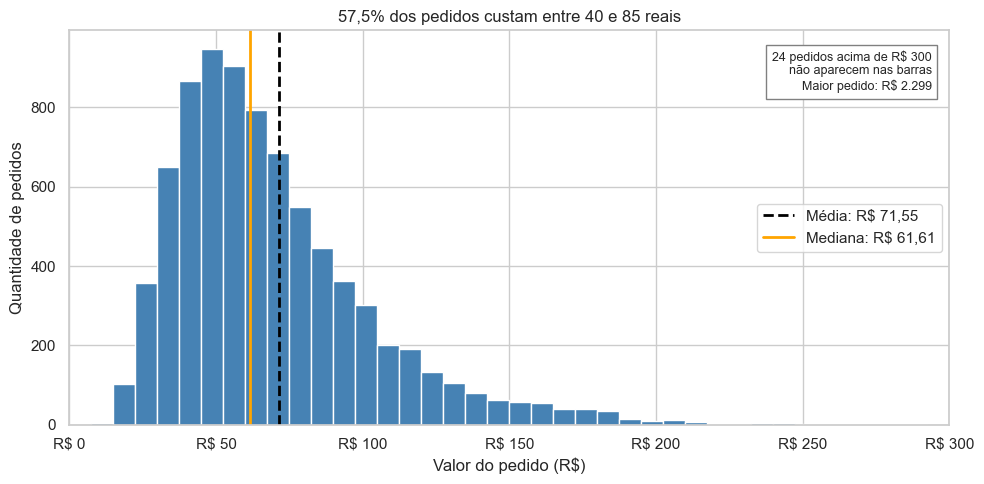

=== RESULTADOS DO GRÁFICO ===
Total de pedidos: 8058
Pedidos mostrados: 8034
Pedidos acima de R$ 300: 24
Média dos pedidos: R$ 71.55
Mediana dos pedidos: R$ 61.61
Maior pedido: R$ 2299.10

Os pedidos acima de R$ 300 continuam na base.


In [53]:
# TAREFA 7.1 - DISTRIBUIÇÃO DO TICKET

# 1. Pegar os valores dos pedidos
valores = df["valor_pedido"]

# Calcular a média e a mediana
media = valores.mean()
mediana = valores.median()

# 2. Definir o limite do gráfico
limite = 300

# Contar os pedidos acima do limite
pedidos_fora = (valores > limite).sum()

# Encontrar o maior pedido
maior_pedido = valores.max()

# 3. Criar o gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# Criar o histograma com 40 faixas
ax.hist(
    valores,
    bins=40,
    range=(0, limite),
    color=cor_principal,
    edgecolor="white"
)

# 4. Marcar a média com uma linha preta tracejada
ax.axvline(
    media,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Média: R$ {media:.2f}".replace(".", ",")
)

# Marcar a mediana com uma linha laranja
ax.axvline(
    mediana,
    color=cor_destaque,
    linewidth=2,
    label=f"Mediana: R$ {mediana:.2f}".replace(".", ",")
)

# 5. Avisar sobre os pedidos acima de R$ 300
aviso = (
    f"{pedidos_fora} pedidos acima de R$ {limite}\n"
    "não aparecem nas barras\n"
    f"Maior pedido: {formatar_reais(maior_pedido, 0)}"
)

# Colocar o aviso dentro do gráfico
ax.text(
    0.98, 0.95,
    aviso,
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
    bbox=dict(facecolor="white", edgecolor="gray")
)

# 6. Colocar título e nomes dos eixos
ax.set_title(
    "57,5% dos pedidos custam entre 40 e 85 reais"
)

ax.set_xlabel("Valor do pedido (R$)")
ax.set_ylabel("Quantidade de pedidos")

# Mostrar o eixo horizontal de R$ 0 até R$ 300
ax.set_xlim(0, limite)

# Mostrar os valores em reais no eixo
ax.xaxis.set_major_formatter(formatador_reais)

# Mostrar a legenda
ax.legend(loc="center right")

# Organizar e mostrar o gráfico
plt.tight_layout()
plt.show()

# 7. Mostrar os resultados com explicações
print("=== RESULTADOS DO GRÁFICO ===")
print(f"Total de pedidos: {len(df)}")
print(f"Pedidos mostrados: {len(df) - pedidos_fora}")
print(f"Pedidos acima de R$ 300: {pedidos_fora}")
print(f"Média dos pedidos: R$ {media:.2f}")
print(f"Mediana dos pedidos: R$ {mediana:.2f}")
print(f"Maior pedido: R$ {maior_pedido:.2f}")

print("\nOs pedidos acima de R$ 300 continuam na base.")


Criei um histograma para mostrar como os valores dos pedidos estão distribuídos.

Observei que **57,5% dos pedidos custam entre R\$ 40 e R\$ 85**.

A média foi de **R\$ 71,55** e a mediana de **R\$ 61,61**. A média ficou maior porque alguns pedidos com valores muito altos influenciam seu resultado.

Para visualizar melhor os dados, limitei o gráfico a **R\$ 300**. Com isso, 24 pedidos ficaram fora das barras, mas continuam na base e foram considerados nos cálculos.

Também coloquei um aviso dentro do gráfico mostrando quantos pedidos ficaram fora e qual foi o maior valor registrado.

Concluí que a mediana representa melhor o ticket típico, pois é menos influenciada pelos pedidos muito altos.

### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

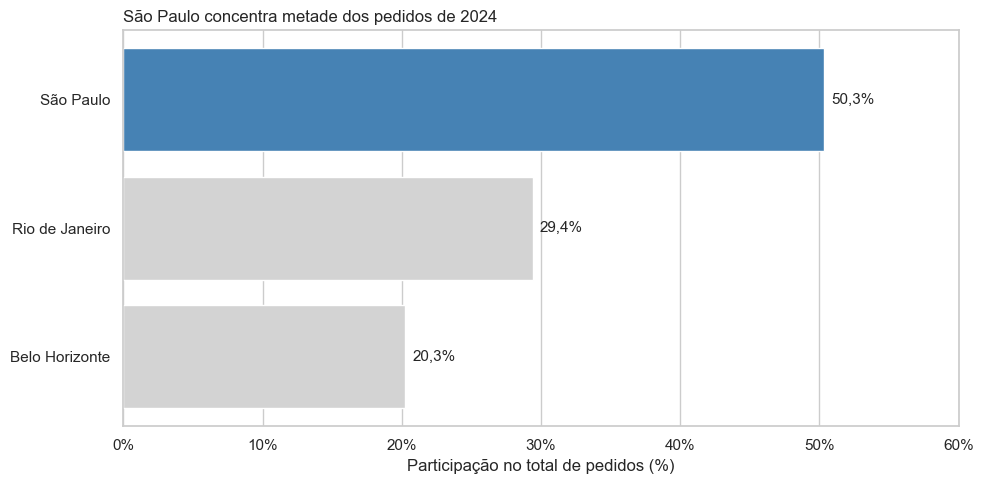

In [54]:
# ============================================================
# TAREFA 7.2 - PARTICIPAÇÃO POR CIDADE
# ============================================================

# 1. Calcular a porcentagem de pedidos de cada cidade
# normalize=True transforma a contagem em proporção (0 a 1)
participacao = df["cidade"].value_counts(normalize=True) * 100

# Ordenar do menor para o maior
# (no gráfico horizontal, o último item aparece no topo)
participacao = participacao.sort_values()

# 2. Escolher a cor de cada barra
# São Paulo em azul (destaque) e as outras cidades em cinza
cores = []
for cidade in participacao.index:
    if cidade == "São Paulo":
        cores.append(cor_principal)
    else:
        cores.append(cor_neutra)

# 3. Criar o gráfico de barras horizontais
fig, ax = plt.subplots()
ax.barh(participacao.index, participacao.values, color=cores)

# 4. Escrever o valor ao lado de cada barra
# posicao = 0, 1, 2 (a linha de cada barra)
# valor = a porcentagem daquela cidade
for posicao, valor in enumerate(participacao.values):
    texto = f"{valor:.1f}%".replace(".", ",")
    ax.text(valor + 0.5, posicao, texto, va="center", fontsize=11)

# 5. Título-conclusão e rótulos
ax.set_title("São Paulo concentra metade dos pedidos de 2024", loc="left")
ax.set_xlabel("Participação no total de pedidos (%)")
ax.set_ylabel("")

# 6. Eixo X de 0% a 60% (sobra espaço para o texto da maior barra)
ax.set_xlim(0, 60)

# Mostrar os números do eixo com o símbolo %
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

# 7. Tirar as linhas horizontais da grade (não ajudam aqui)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

Criei um gráfico de barras horizontais para mostrar a participação de cada cidade no total de pedidos.

São Paulo teve a maior quantidade, com **4.055 pedidos (50,32%)**.

O Rio de Janeiro ficou em segundo lugar, com **2.371 pedidos (29,42%)**, e Belo Horizonte em terceiro, com **1.632 pedidos (20,25%)**.

Percebi que São Paulo concentra um pouco mais da metade de todos os pedidos.



### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

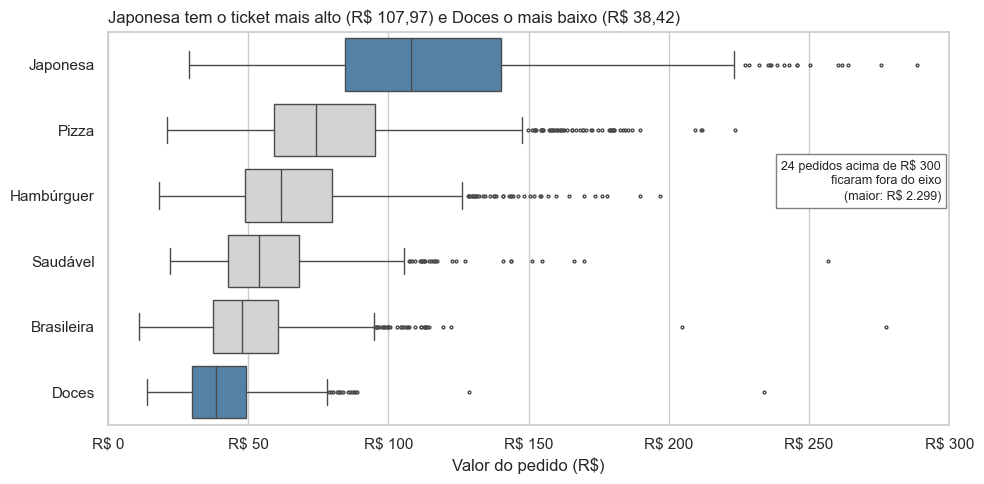

=== MEDIANA DO TICKET POR COZINHA ===
Japonesa     R$ 107,97
Pizza        R$ 74,31
Hambúrguer   R$ 61,67
Saudável     R$ 53,73
Brasileira   R$ 47,82
Doces        R$ 38,42


In [55]:
# ============================================================
# TAREFA 7.3 - TICKET POR TIPO DE COZINHA
# ============================================================

# 1. Calcular a mediana de cada cozinha e ordenar da maior para a menor
medianas = df.groupby("tipo_cozinha")["valor_pedido"].median()
medianas = medianas.sort_values(ascending=False)

# Guardar a ordem das cozinhas numa lista
ordem = list(medianas.index)

# A primeira da lista é a mais cara e a última é a mais barata
mais_cara = ordem[0]
mais_barata = ordem[-1]

# 2. Escolher a cor de cada cozinha
# Mais cara e mais barata em azul, as outras em cinza
cores = {}
for cozinha in ordem:
    if cozinha == mais_cara or cozinha == mais_barata:
        cores[cozinha] = cor_principal
    else:
        cores[cozinha] = cor_neutra

# 3. Limite do eixo (o mesmo da Tarefa 7.1)
limite = 300
pedidos_fora = (df["valor_pedido"] > limite).sum()

# 4. Criar o boxplot horizontal
fig, ax = plt.subplots()

sns.boxplot(
    data=df,
    x="valor_pedido",      # valores no eixo horizontal
    y="tipo_cozinha",      # uma caixa para cada cozinha
    order=ordem,           # ordem da mais cara para a mais barata
    hue="tipo_cozinha",    # necessário para usar uma cor por cozinha
    palette=cores,         # cores escolhidas no passo 2
    legend=False,          # a legenda repetiria os nomes do eixo
    fliersize=2,           # bolinhas pequenas para não poluir
    ax=ax
)

# 5. Aviso dentro do gráfico: não esconder os pedidos de valor alto
aviso = (
    f"{pedidos_fora} pedidos acima de R$ {limite}\n"
    "ficaram fora do eixo\n"
    f"(maior: {formatar_reais(df['valor_pedido'].max(), 0)})"
)
ax.text(0.99, 0.62, aviso, transform=ax.transAxes,
        ha="right", va="center", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="gray"))

# 6. Título-conclusão e rótulos
ax.set_title("Japonesa tem o ticket mais alto (R$ 107,97) e Doces o mais baixo (R$ 38,42)",
             loc="left")
ax.set_xlabel("Valor do pedido (R$)")
ax.set_ylabel("")

# 7. Eixo de R$ 0 a R$ 300, no formato brasileiro
ax.set_xlim(0, limite)
ax.xaxis.set_major_formatter(formatador_reais)

# 8. Tirar as linhas horizontais da grade
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

# 9. Mostrar as medianas em ordem
print("=== MEDIANA DO TICKET POR COZINHA ===")
for cozinha in ordem:
    valor = f"{medianas[cozinha]:.2f}".replace(".", ",")
    print(f"{cozinha:<12} R$ {valor}")

Fiz um boxplot do valor dos pedidos para cada tipo de cozinha, ordenado pela mediana, da mais cara para a mais barata.

A cozinha Japonesa tem o ticket mais alto, com mediana de R\$ 107,97, e Doces tem o mais baixo, com R\$ 38,42. Destaquei essas duas em azul.

Percebi que a caixa da Japonesa também é a mais larga, ou seja, os preços dos pedidos japoneses variam mais. Já em Doces os pedidos ficam todos numa faixa de preço menor.

Todas as cozinhas têm alguns pedidos bem acima do normal (as bolinhas). Cortei o eixo em R\$ 300, mas deixei um aviso no gráfico de que 24 pedidos ficaram de fora.

### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

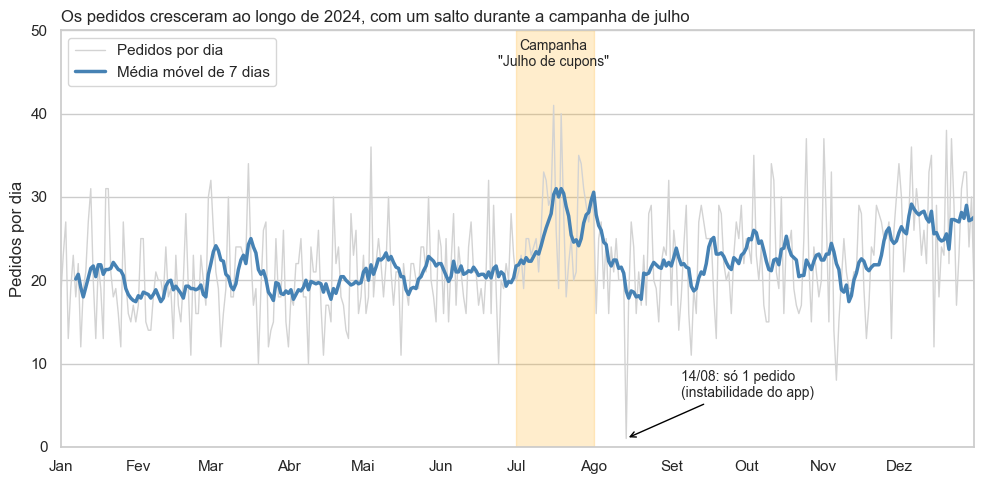

=== MÉDIA DE PEDIDOS POR DIA ===
Junho:  21,00
Julho:  26,52
Agosto: 21,35
Pedidos em 14/08: 1


In [56]:
# ============================================================
# TAREFA 7.4 - EVOLUÇÃO DIÁRIA DOS PEDIDOS
# ============================================================

# 1. Contar os pedidos de cada dia
# resample("D") agrupa os pedidos por dia; size() conta quantos há em cada dia
pedidos_por_dia = df.set_index("data_hora").resample("D").size()

# 2. Calcular a média móvel de 7 dias
# rolling(7) olha sempre para 7 dias seguidos; mean() tira a média deles
media_movel = pedidos_por_dia.rolling(7).mean()

# 3. Datas que vamos marcar no gráfico
dia_instavel = pd.Timestamp("2024-08-14")
pedidos_dia_instavel = pedidos_por_dia[dia_instavel]

inicio_campanha = pd.Timestamp("2024-07-01")
fim_campanha = pd.Timestamp("2024-08-01")   # vai até o fim do dia 31/07

# 4. Criar o gráfico
fig, ax = plt.subplots()

# Faixa laranja clara no período da campanha
ax.axvspan(inicio_campanha, fim_campanha, color=cor_destaque, alpha=0.2)

# Linha fina e cinza: pedidos de cada dia (contexto)
ax.plot(pedidos_por_dia.index, pedidos_por_dia.values,
        color=cor_neutra, linewidth=1, label="Pedidos por dia")

# Linha grossa e azul: média móvel (dado principal)
ax.plot(media_movel.index, media_movel.values,
        color=cor_principal, linewidth=2.5, label="Média móvel de 7 dias")

# 5. Escrever o nome da campanha acima da faixa
ax.text(pd.Timestamp("2024-07-16"), 49, "Campanha\n\"Julho de cupons\"",
        ha="center", va="top", fontsize=10)

# 6. Seta apontando para o dia da instabilidade
ax.annotate(
    f"14/08: só {pedidos_dia_instavel} pedido\n(instabilidade do app)",
    xy=(dia_instavel, pedidos_dia_instavel),          # onde a seta aponta
    xytext=(pd.Timestamp("2024-09-05"), 6),           # onde fica o texto
    fontsize=10,
    arrowprops=dict(arrowstyle="->", color="black")
)

# 7. Título-conclusão e rótulos
ax.set_title("Os pedidos cresceram ao longo de 2024, com um salto durante a campanha de julho",
             loc="left")
ax.set_xlabel("")
ax.set_ylabel("Pedidos por dia")
ax.set_ylim(0, 50)

# 8. Nomes dos meses em português no eixo X
inicio_meses = pd.date_range("2024-01-01", "2024-12-01", freq="MS")
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
ax.set_xticks(inicio_meses)
ax.set_xticklabels(nomes_meses)
ax.set_xlim(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-31"))

# 9. Tirar as linhas verticais da grade
ax.grid(axis="x", visible=False)

ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 10. Mostrar alguns valores para conferir
print("=== MÉDIA DE PEDIDOS POR DIA ===")
print(f"Junho:  {pedidos_por_dia.loc['2024-06'].mean():.2f}".replace(".", ","))
print(f"Julho:  {pedidos_por_dia.loc['2024-07'].mean():.2f}".replace(".", ","))
print(f"Agosto: {pedidos_por_dia.loc['2024-08'].mean():.2f}".replace(".", ","))
print(f"Pedidos em 14/08: {pedidos_dia_instavel}")

Fiz um gráfico com a quantidade de pedidos de cada dia (linha cinza) e a média móvel de 7 dias (linha azul), que deixa a tendência mais fácil de ver.

A média móvel começa o ano perto de 20 pedidos por dia e termina perto de 27, então os pedidos cresceram ao longo de 2024.

Em julho, durante a campanha "Julho de cupons", a média de pedidos por dia subiu de 21,00 (junho) para 26,52, e depois voltou para 21,35 em agosto. Esse aumento aconteceu junto com a campanha, mas só com este gráfico eu não posso afirmar que foi a campanha que causou o aumento.

Também marquei o dia 14/08, que teve só 1 pedido por causa da instabilidade do app. Esse dia puxa a média móvel para baixo durante a semana seguinte, então a queda que aparece em meados de agosto não é uma queda real de demanda.

### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

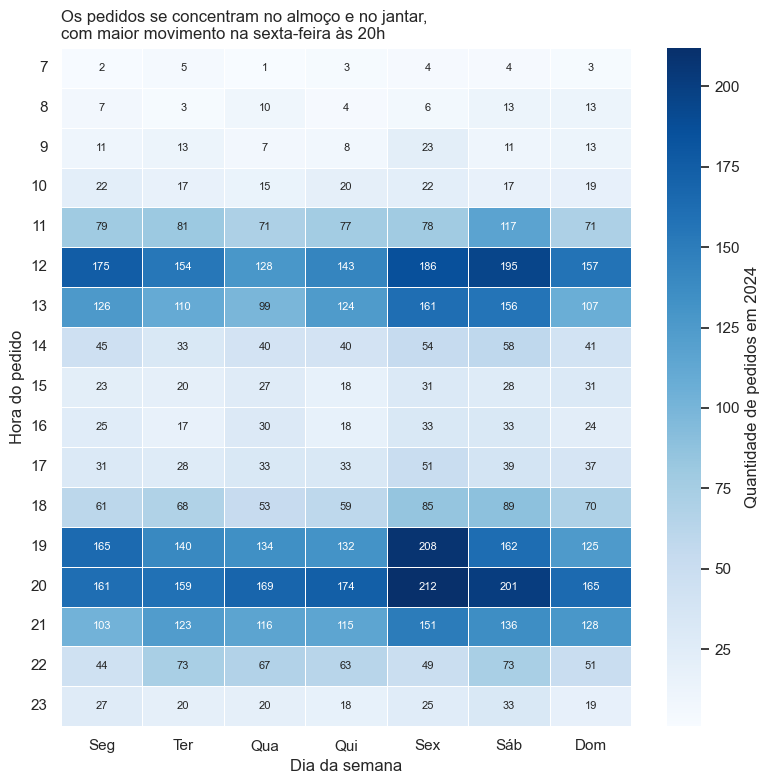

=== MAIOR MOVIMENTO ===
Dia: Sex
Hora: 20
Quantidade de pedidos: 212


In [57]:

# TAREFA 7.5 - QUANDO OS PEDIDOS ACONTECEM

# Criar o gráfico
fig, ax = plt.subplots(figsize=(8, 8))

# Criar o mapa de calor
sns.heatmap(
    tabela_hora_dia,
    cmap="Blues",
    annot=True,
    fmt="d",
    annot_kws={"fontsize": 8},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Quantidade de pedidos em 2024"},
    ax=ax
)

# Colocar o título com a principal descoberta
ax.set_title(
    "Os pedidos se concentram no almoço e no jantar,\n"
    "com maior movimento na sexta-feira às 20h",
    loc="left"
)

# Colocar os nomes dos eixos
ax.set_xlabel("Dia da semana")
ax.set_ylabel("Hora do pedido")

# Deixar as horas sem inclinação
ax.tick_params(axis="y", rotation=0)

# Organizar e mostrar o gráfico
plt.tight_layout()
plt.show()

# Mostrar o maior movimento
maior = tabela_hora_dia.stack().idxmax()

hora = maior[0]
dia = maior[1]
quantidade = tabela_hora_dia.loc[hora, dia]

print("=== MAIOR MOVIMENTO ===")
print("Dia:", dia)
print("Hora:", hora)
print("Quantidade de pedidos:", quantidade)


Criei um mapa de calor para mostrar a quantidade de pedidos por hora e dia da semana. Quanto mais escuro o azul, maior a quantidade de pedidos.

Observei que os pedidos se concentram principalmente nos horários de almoço, entre 12h e 13h, e de jantar, entre 19h e 21h.

O maior movimento aconteceu nas sextas-feiras, às 20h, com 212 pedidos registrados durante o ano. Outros horários com bastante movimento foram sexta-feira às 19h, com 208 pedidos, e sábado às 20h, com 201 pedidos.

Os valores representam o total de pedidos em 2024. Como o ano teve 53 segundas-feiras e terças-feiras, esses dias tiveram uma pequena vantagem na contagem em relação aos outros, que ocorreram 52 vezes.

Com o gráfico, consegui identificar os horários de maior movimento. Essas informações podem ajudar no planejamento dos entregadores, principalmente nos períodos de almoço e jantar.

### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

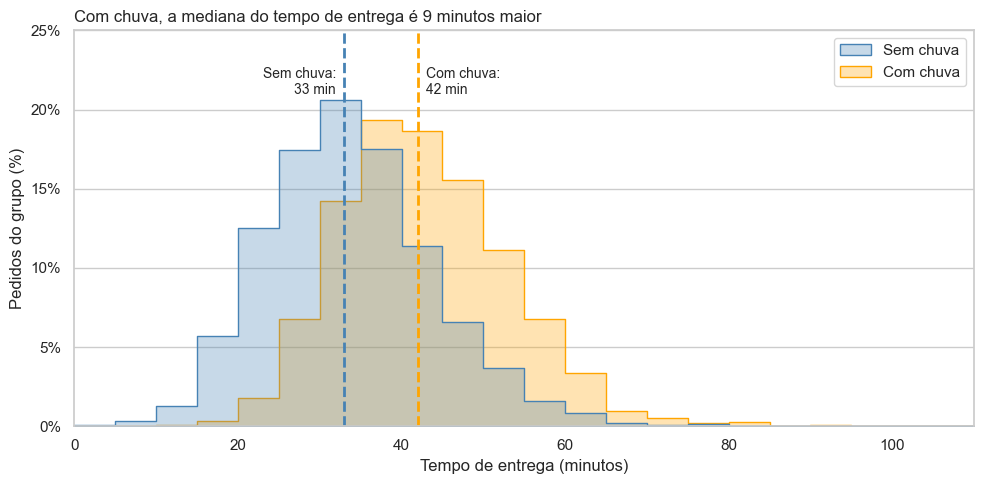

=== CHUVA E TEMPO DE ENTREGA ===
Mediana sem chuva: 33 minutos
Mediana com chuva: 42 minutos
Diferença entre as medianas: 9 minutos

=== TEMPOS ACIMA DO LIMITE DO GRÁFICO ===
Sem chuva: 0 pedidos
Com chuva: 0 pedidos
Total fora do gráfico: 0 pedidos


In [58]:
# ============================================================
# TAREFA 7.6 - CHUVA E TEMPO DE ENTREGA
# ============================================================

# 1. Criar uma cópia dos dados para o gráfico
# O DataFrame original não será modificado
dados_grafico = df.copy()

# Criar nomes em português para os grupos
dados_grafico["condicao"] = dados_grafico["chuva"].map({
    False: "Sem chuva",
    True: "Com chuva"
})

# 2. Calcular a mediana de cada grupo
mediana_sem = df.loc[
    df["chuva"] == False, "tempo_entrega_min"
].median()

mediana_com = df.loc[
    df["chuva"] == True, "tempo_entrega_min"
].median()

# Calcular a diferença entre as medianas
diferenca = mediana_com - mediana_sem

# 3. Definir as cores
cores = {
    "Sem chuva": cor_principal,
    "Com chuva": cor_destaque
}

# 4. Conferir os tempos acima do limite do gráfico
limite = 110

fora_sem = (
    (df["chuva"] == False) &
    (df["tempo_entrega_min"] > limite)
).sum()

fora_com = (
    (df["chuva"] == True) &
    (df["tempo_entrega_min"] > limite)
).sum()

total_fora = fora_sem + fora_com

# 5. Criar o gráfico
fig, ax = plt.subplots(figsize=(10, 5))

# Criar os dois histogramas
sns.histplot(
    data=dados_grafico,
    x="tempo_entrega_min",
    hue="condicao",
    hue_order=["Sem chuva", "Com chuva"],
    palette=cores,
    stat="percent",
    common_norm=False,
    binwidth=5,
    binrange=(0, limite),
    element="step",
    alpha=0.3,
    ax=ax
)

# 6. Marcar as medianas com linhas tracejadas
ax.axvline(
    mediana_sem,
    color=cor_principal,
    linestyle="--",
    linewidth=2
)

ax.axvline(
    mediana_com,
    color=cor_destaque,
    linestyle="--",
    linewidth=2
)

# Escrever os valores das medianas
ax.text(
    mediana_sem - 1,
    21,
    f"Sem chuva:\n{mediana_sem:.0f} min",
    ha="right",
    fontsize=10
)

ax.text(
    mediana_com + 1,
    21,
    f"Com chuva:\n{mediana_com:.0f} min",
    ha="left",
    fontsize=10
)

# 7. Colocar título e nomes dos eixos
ax.set_title(
    f"Com chuva, a mediana do tempo de entrega é "
    f"{diferenca:.0f} minutos maior",
    loc="left"
)

ax.set_xlabel("Tempo de entrega (minutos)")
ax.set_ylabel("Pedidos do grupo (%)")

# 8. Configurar os limites e os percentuais
ax.set_xlim(0, limite)
ax.set_ylim(0, 25)

ax.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100, decimals=0)
)

# Retirar as linhas verticais da grade
ax.grid(axis="x", visible=False)

# Retirar o título da legenda
ax.get_legend().set_title("")

# 9. Avisar no gráfico se houver tempos acima do limite
if total_fora > 0:
    ax.text(
        0.98,
        0.95,
        f"{total_fora} pedidos acima de {limite} min\n"
        "não aparecem no gráfico",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox=dict(facecolor="white", edgecolor="gray")
    )

# Organizar e mostrar o gráfico
plt.tight_layout()
plt.show()

# 10. Mostrar os resultados em português
print("=== CHUVA E TEMPO DE ENTREGA ===")

print(f"Mediana sem chuva: {mediana_sem:.0f} minutos")
print(f"Mediana com chuva: {mediana_com:.0f} minutos")
print(f"Diferença entre as medianas: {diferenca:.0f} minutos")

print("\n=== TEMPOS ACIMA DO LIMITE DO GRÁFICO ===")
print(f"Sem chuva: {fora_sem} pedidos")
print(f"Com chuva: {fora_com} pedidos")
print(f"Total fora do gráfico: {total_fora} pedidos")



Criei dois histogramas para comparar os tempos de entrega sem chuva (azul) e com chuva (laranja).

Usei porcentagens dentro de cada grupo, porque existem mais pedidos sem chuva e queria comparar as distribuições de forma justa.

Observei que os pedidos com chuva apresentam tempos maiores, com a distribuição deslocada para a direita.

A mediana passou de 33 minutos sem chuva para 42 minutos com chuva, uma diferença de 9 minutos.

Esses resultados mostram uma associação entre chuva e maior tempo de entrega, mas não comprovam que a chuva seja a única causa dessa diferença.



### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

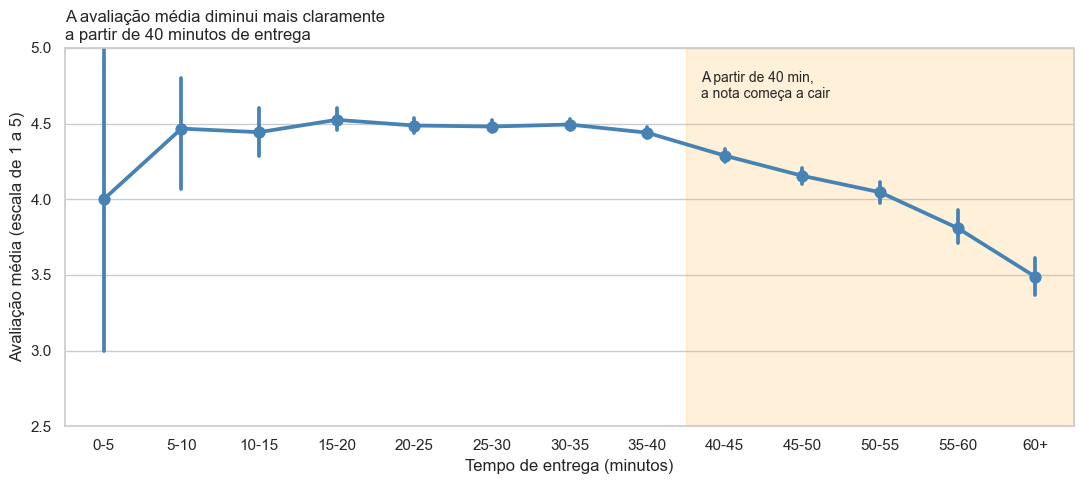

=== AVALIAÇÃO MÉDIA POR FAIXA DE TEMPO ===


,avaliacoes,nota_media
faixa_tempo,,
0-5,3,4.00
5-10,15,4.47
10-15,70,4.44
15-20,284,4.52
20-25,622,4.49
25-30,943,4.48
30-35,1248,4.49
35-40,1185,4.44
40-45,913,4.29



=== PRINCIPAIS RESULTADOS ===
Avaliação média de 40 a 45 min: 4,29
Avaliação média de 60 min ou mais: 3,49
Avaliações na faixa de 0 a 5 min: 3

A queda das avaliações fica mais evidente a partir de 40 minutos.
Os intervalos de confiança utilizados são de 95%.


In [59]:
# ============================================================
# TAREFA 7.7 - TEMPO DE ENTREGA X AVALIAÇÃO
# ============================================================

# 1. Definir as faixas de tempo de 5 em 5 minutos
# float("inf") significa infinito: 60 minutos ou mais
limites = [
    0, 5, 10, 15, 20, 25, 30,
    35, 40, 45, 50, 55, 60, float("inf")
]

# Criar os nomes das faixas
nomes_faixas = [
    "0-5", "5-10", "10-15", "15-20",
    "20-25", "25-30", "30-35", "35-40",
    "40-45", "45-50", "50-55", "55-60", "60+"
]

# 2. Criar uma cópia dos dados
# Assim, não modificamos o DataFrame original
dados_grafico = df.copy()

# Colocar cada pedido na faixa correspondente
dados_grafico["faixa_tempo"] = pd.cut(
    dados_grafico["tempo_entrega_min"],
    bins=limites,
    labels=nomes_faixas,
    right=False
)

# 3. Calcular a quantidade e a avaliação média por faixa
resumo_faixas = dados_grafico.groupby(
    "faixa_tempo",
    observed=False
)["avaliacao"].agg(
    avaliacoes="count",
    nota_media="mean"
)

# 4. Criar o gráfico
fig, ax = plt.subplots(figsize=(11, 5))

# Criar a linha com as médias e os intervalos de confiança
sns.pointplot(
    data=dados_grafico,
    x="faixa_tempo",
    y="avaliacao",
    order=nomes_faixas,
    errorbar=("ci", 95),
    seed=42,
    color=cor_principal,
    ax=ax
)

# 5. Destacar a região a partir de 40 minutos
# A faixa 40-45 começa na posição 8
ax.axvspan(
    7.5,
    12.5,
    color=cor_destaque,
    alpha=0.15
)

# Escrever uma explicação na região destacada
ax.text(
    7.7,
    4.85,
    "A partir de 40 min,\na nota começa a cair",
    fontsize=10,
    va="top"
)

# 6. Colocar título e nomes dos eixos
ax.set_title(
    "A avaliação média diminui mais claramente\n"
    "a partir de 40 minutos de entrega",
    loc="left"
)

ax.set_xlabel("Tempo de entrega (minutos)")
ax.set_ylabel("Avaliação média (escala de 1 a 5)")

# 7. Ajustar os limites do gráfico
ax.set_ylim(2.5, 5)
ax.set_xlim(-0.5, 12.5)

# Retirar as linhas verticais da grade
ax.grid(axis="x", visible=False)

# Organizar e mostrar o gráfico
plt.tight_layout()
plt.show()

# 8. Mostrar a tabela de resultados
print("=== AVALIAÇÃO MÉDIA POR FAIXA DE TEMPO ===")

display(resumo_faixas.round(2))

# 9. Mostrar os principais resultados
media_40_45 = resumo_faixas.loc["40-45", "nota_media"]
media_60_mais = resumo_faixas.loc["60+", "nota_media"]
qtd_0_5 = resumo_faixas.loc["0-5", "avaliacoes"]

print("\n=== PRINCIPAIS RESULTADOS ===")

print(
    f"Avaliação média de 40 a 45 min: "
    f"{media_40_45:.2f}".replace(".", ",")
)

print(
    f"Avaliação média de 60 min ou mais: "
    f"{media_60_mais:.2f}".replace(".", ",")
)

print(f"Avaliações na faixa de 0 a 5 min: {qtd_0_5}")

print("\nA queda das avaliações fica mais evidente a partir de 40 minutos.")
print("Os intervalos de confiança utilizados são de 95%.")


Separei os tempos de entrega em faixas de 5 minutos e criei um gráfico com a avaliação média de cada faixa e seus intervalos de confiança de 95%.

Observei que, entre 20 e 35 minutos, as avaliações médias ficaram próximas de 4,5.

A queda ficou mais evidente a partir da faixa de 40 a 45 minutos, quando a média passou para 4,29. Nos pedidos com 60 minutos ou mais, a média chegou a 3,49.

Também percebi que a faixa de 0 a 5 minutos tinha apenas 3 avaliações, por isso não tirei conclusões sobre ela.

Usei uma faixa laranja no gráfico para destacar os tempos a partir de 40 minutos.

Concluí que os pedidos com maior tempo de entrega tendem a receber avaliações menores. Porém, essa relação não comprova que a demora seja a única causa das notas mais baixas.

Na Etapa 9, vou analisar essa relação com um teste estatístico.

### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

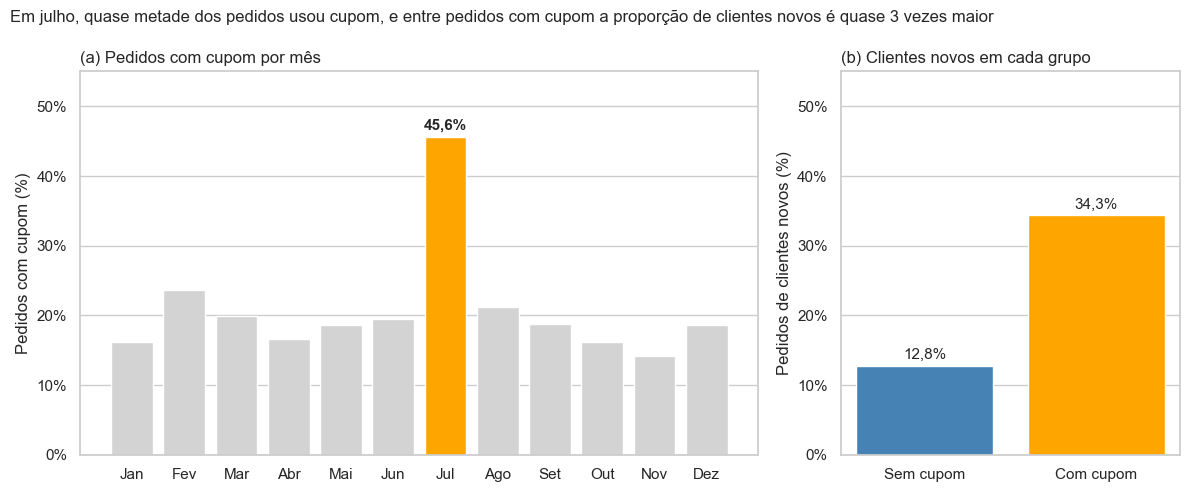

=== USO DE CUPOM ===
Julho: 45,62% dos pedidos com cupom
Média dos outros meses: 18,50%
Clientes novos sem cupom: 12,81%
Clientes novos com cupom: 34,35%
Diferença: 21,54 pontos percentuais


In [60]:
# ============================================================
# TAREFA 7.8 - O EFEITO DO CUPOM
# ============================================================

# 1. Painel (a): porcentagem de pedidos com cupom em cada mês
# cupom é True/False; a média de True/False é a proporção de True
taxa_cupom_mes = df.groupby("mes")["cupom"].mean() * 100

nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

# Julho em laranja, os outros meses em cinza
cores_meses = []
for mes in taxa_cupom_mes.index:
    if mes == 7:
        cores_meses.append(cor_destaque)
    else:
        cores_meses.append(cor_neutra)

# 2. Painel (b): porcentagem de clientes novos sem e com cupom
novos_por_cupom = df.groupby("cupom")["cliente_novo"].mean() * 100
pct_novos_sem = novos_por_cupom[False]
pct_novos_com = novos_por_cupom[True]

# 3. Criar a figura com 2 gráficos lado a lado
# width_ratios=[2, 1]: o painel dos meses fica com o dobro da largura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5),
                               gridspec_kw={"width_ratios": [2, 1]})

# ---------------- Painel (a) ----------------
ax1.bar(nomes_meses, taxa_cupom_mes.values, color=cores_meses)

# Escrever o valor só em julho (o destaque)
# julho é a 7ª barra, que fica na posição 6 (a contagem começa em 0)
taxa_julho = taxa_cupom_mes[7]
ax1.text(6, taxa_julho + 1, f"{taxa_julho:.1f}%".replace(".", ","),
         ha="center", fontsize=11, fontweight="bold")

ax1.set_title("(a) Pedidos com cupom por mês", loc="left")
ax1.set_ylabel("Pedidos com cupom (%)")
ax1.set_ylim(0, 55)
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax1.grid(axis="x", visible=False)

# ---------------- Painel (b) ----------------
grupos = ["Sem cupom", "Com cupom"]
valores = [pct_novos_sem, pct_novos_com]

# Sem cupom em azul, com cupom em laranja (regra da Tarefa 7.0)
ax2.bar(grupos, valores, color=[cor_principal, cor_destaque])

# Escrever o valor em cima de cada barra
for posicao, valor in enumerate(valores):
    ax2.text(posicao, valor + 1, f"{valor:.1f}%".replace(".", ","),
             ha="center", fontsize=11)

ax2.set_title("(b) Clientes novos em cada grupo", loc="left")
ax2.set_ylabel("Pedidos de clientes novos (%)")
ax2.set_ylim(0, 55)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax2.grid(axis="x", visible=False)

# 4. Título-conclusão da figura inteira
fig.suptitle("Em julho, quase metade dos pedidos usou cupom, e entre pedidos com cupom "
             "a proporção de clientes novos é quase 3 vezes maior",
             x=0.01, ha="left", fontsize=12)

plt.tight_layout()
plt.show()

# 5. Mostrar os valores
print("=== USO DE CUPOM ===")
print(f"Julho: {taxa_julho:.2f}% dos pedidos com cupom".replace(".", ","))
media_outros = taxa_cupom_mes.drop(7).mean()
print(f"Média dos outros meses: {media_outros:.2f}%".replace(".", ","))
print(f"Clientes novos sem cupom: {pct_novos_sem:.2f}%".replace(".", ","))
print(f"Clientes novos com cupom: {pct_novos_com:.2f}%".replace(".", ","))
diferenca_pp = pct_novos_com - pct_novos_sem
print(f"Diferença: {diferenca_pp:.2f} pontos percentuais".replace(".", ","))

Fiz uma figura com dois gráficos. No primeiro, mostrei a porcentagem de pedidos com cupom em cada mês, com julho em destaque. No segundo, comparei a porcentagem de clientes novos entre os pedidos sem cupom e com cupom.

Em julho, 45,62% dos pedidos usaram cupom, enquanto nos outros meses a média foi de 18,50%. O uso de cupons em julho foi cerca de 2,5 vezes a média dos outros meses, o que coincide com a campanha "Julho de cupons". Como a base não tem informações sobre a campanha (quantos cupons foram oferecidos e para quem), não posso afirmar que ela sozinha causou esse aumento.

Entre os pedidos com cupom, 34,35% foram de clientes novos, contra 12,81% nos pedidos sem cupom. A diferença é de 21,54 pontos percentuais, quase 3 vezes mais.

Entendi que cupom e cliente novo andam juntos, mas não dá para saber quem causa quem: o cupom pode atrair clientes novos, ou o app pode simplesmente dar cupom para quem está fazendo o primeiro pedido. A relação entre essas duas variáveis vai ser testada na Etapa 9 (Tarefa 9.5).

### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

- **7.1 — Histograma:** escolhi o histograma porque ele mostra a forma da distribuição do ticket (onde estão a maioria dos pedidos e a cauda longa à direita), e as linhas de média e mediana deixam claro por que a média fica acima da mediana; um boxplot esconderia a forma da distribuição e uma barra única mostraria só um número.

- **7.2 — Barras horizontais:** usei barras porque comparar comprimentos é mais fácil do que comparar fatias de pizza, e ficaria difícil ver na pizza que o Rio (29,4%) é quase 1,5 vez Belo Horizonte (20,3%); deixei as barras na horizontal para os nomes das cidades caberem.

- **7.3 — Boxplot:** o enunciado pede a distribuição do ticket por cozinha, e o boxplot mostra mediana, faixa central e valores extremos de seis grupos lado a lado; uma barra de média mostraria só um número por cozinha e seria puxada pelos pedidos de valor alto.

- **7.4 — Gráfico de linha:** para uma série no tempo, a linha mostra a sequência dos dias e a tendência, e a média móvel de 7 dias tira o sobe e desce diário; barras para 366 dias ficariam poluídas e esconderiam a tendência.

- **7.5 — Mapa de calor:** a tabela tem 17 horas × 7 dias (119 valores), e o mapa de calor transforma os números em tons de cor, fazendo os picos de almoço e jantar aparecerem na hora; 7 linhas ou 7 grupos de barras ficariam embaralhados.

- **7.6 — Histogramas sobrepostos:** desenhar os dois grupos no mesmo eixo, em porcentagem de cada grupo, deixa visível que a curva com chuva tem o mesmo formato mas fica deslocada para a direita; dois gráficos separados ou duas barras de média não mostrariam esse deslocamento.

- **7.7 — Gráfico de pontos com intervalo de confiança:** os pontos mostram a nota média em cada faixa de tempo e a barra de confiança mostra quais médias são confiáveis (como a faixa de 0 a 5 minutos, com só 3 avaliações); um gráfico de dispersão não funcionaria porque a nota só tem 5 valores possíveis e os pontos ficariam empilhados.

- **7.8 — Dois painéis de barras:** juntei os dois gráficos numa figura porque os dois respondem à mesma pergunta sobre o cupom, e usei a mesma escala de 0% a 55% nos dois para poder comparar; colocar meses e grupos de cupom no mesmo eixo misturaria duas coisas diferentes.

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

=== CORRELAÇÃO DE PEARSON ===


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.70,0.58,-0.01,-0.23
tempo_entrega_min,0.70,1.00,0.42,-0.01,-0.29
taxa_entrega,0.58,0.42,1.00,0.01,-0.10
valor_pedido,-0.01,-0.01,0.01,1.00,-0.01
avaliacao,-0.23,-0.29,-0.10,-0.01,1.00



=== CORRELAÇÃO DE SPEARMAN ===


,distancia_km,tempo_entrega_min,taxa_entrega,valor_pedido,avaliacao
distancia_km,1.00,0.65,0.79,-0.02,-0.17
tempo_entrega_min,0.65,1.00,0.52,-0.01,-0.24
taxa_entrega,0.79,0.52,1.00,0.01,-0.11
valor_pedido,-0.02,-0.01,0.01,1.00,0.01
avaliacao,-0.17,-0.24,-0.11,0.01,1.00


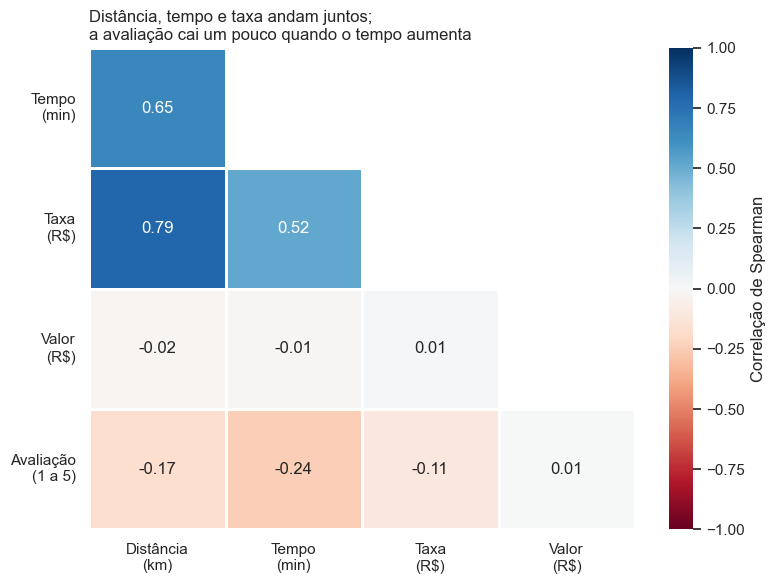

In [61]:
# ============================================================
# TAREFA 8.1 - MATRIZES DE CORRELAÇÃO
# ============================================================

# 1. Colunas que vamos comparar
colunas_corr = ["distancia_km", "tempo_entrega_min", "taxa_entrega",
                "valor_pedido", "avaliacao"]

# 2. Calcular as duas matrizes
# Os NaN são ignorados: cada par usa só os pedidos que têm os dois valores
pearson = df[colunas_corr].corr(method="pearson")
spearman = df[colunas_corr].corr(method="spearman")

print("=== CORRELAÇÃO DE PEARSON ===")
display(pearson.round(2))

print("\n=== CORRELAÇÃO DE SPEARMAN ===")
display(spearman.round(2))

# 3. Preparar a matriz de Spearman para o gráfico
# Nomes em português só no gráfico (as colunas do df não mudam)
nomes = ["Distância\n(km)", "Tempo\n(min)", "Taxa\n(R$)",
         "Valor\n(R$)", "Avaliação\n(1 a 5)"]

spearman_grafico = spearman.copy()
spearman_grafico.index = nomes
spearman_grafico.columns = nomes

# Tirar a 1ª linha e a última coluna, que ficariam vazias no triângulo
spearman_grafico = spearman_grafico.iloc[1:, :-1]

# 4. Máscara: True = esconder aquele quadrado
# np.triu marca a parte de cima da tabela; k=1 mantém a diagonal visível
mascara = np.triu(np.ones_like(spearman_grafico, dtype=bool), k=1)

# 5. Desenhar o mapa de calor
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    spearman_grafico,
    mask=mascara,               # esconder o triângulo de cima
    cmap="RdBu",                # vermelho (negativo) → branco → azul (positivo)
    vmin=-1, vmax=1,            # escala completa da correlação
    center=0,                   # o branco fica exatamente no zero
    annot=True,                 # escrever o número em cada quadrado
    fmt=".2f",                  # duas casas decimais
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlação de Spearman"},
    ax=ax
)

# 6. Título-conclusão e ajustes
ax.set_title("Distância, tempo e taxa andam juntos;\n"
             "a avaliação cai um pouco quando o tempo aumenta", loc="left")
ax.tick_params(axis="y", rotation=0)
ax.grid(False)                  # tirar a grade que aparece atrás dos quadrados vazios

plt.tight_layout()
plt.show()


Calculei as correlações de Pearson e Spearman entre distância, tempo de entrega, taxa de entrega, valor do pedido e avaliação.

Também criei um mapa de calor com a correlação de Spearman para facilitar a comparação.

As maiores correlações positivas foram entre distância e taxa de entrega (0,79), distância e tempo de entrega (0,65) e tempo de entrega e taxa (0,52).

Isso mostra que pedidos mais distantes tendem a apresentar tempos de entrega e taxas maiores.

A avaliação apresentou correlação negativa com o tempo de entrega (-0,24) e com a distância (-0,17). Portanto, pedidos mais demorados e distantes tendem a receber avaliações um pouco menores.

O valor do pedido teve correlações muito próximas de zero, mostrando que não encontrei uma relação importante entre ele e as outras variáveis analisadas.

Também percebi que a correlação entre distância e taxa foi de 0,58 em Pearson e 0,79 em Spearman. Vou investigar essa diferença na Tarefa 8.3.

Concluí que as correlações ajudam a identificar relações entre variáveis, mas não comprovam que uma seja a causa da outra.

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

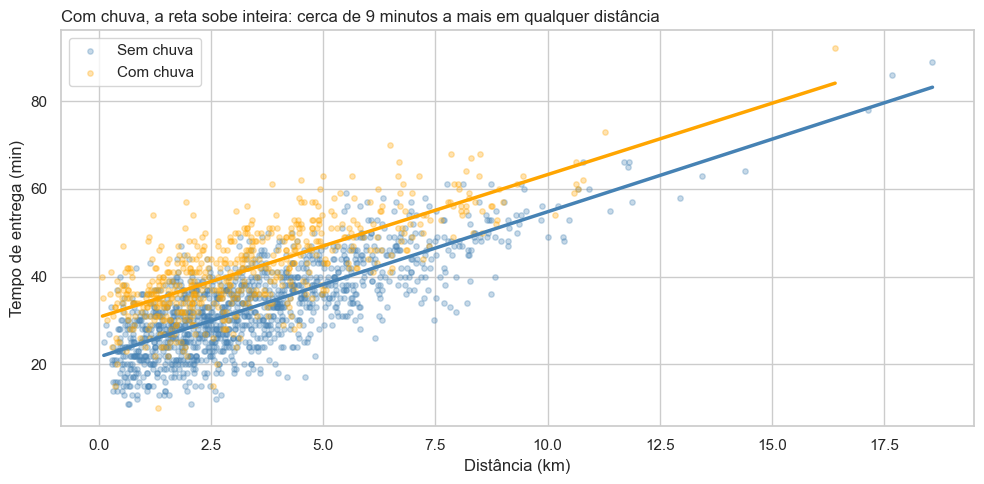

=== RETA DE CADA GRUPO (amostra) ===
Sem chuva: 1336 pedidos | +3,31 min por km | começa em 21,67 min
Com chuva: 575 pedidos | +3,25 min por km | começa em 30,73 min


In [62]:
# ============================================================
# TAREFA 8.2 - DISTÂNCIA × TEMPO, COLORIDO POR CHUVA
# ============================================================

# 1. Sortear 2.000 pedidos
# random_state=42 faz o sorteio sair igual toda vez que rodar
amostra = df.sample(n=2000, random_state=42)

# 2. Criar o gráfico
fig, ax = plt.subplots()

# 3. Desenhar um grupo de cada vez: primeiro sem chuva, depois com chuva
grupos = [
    ("Sem chuva", False, cor_principal),
    ("Com chuva", True, cor_destaque)
]

for nome, tem_chuva, cor in grupos:

    # Separar os pedidos do grupo
    grupo = amostra[amostra["chuva"] == tem_chuva]

    # regplot desenha os pontos e a reta de tendência juntos
    sns.regplot(
        data=grupo,
        x="distancia_km",
        y="tempo_entrega_min",
        color=cor,
        ci=None,                                  # sem faixa de confiança em volta da reta
        scatter_kws={"alpha": 0.3, "s": 15},     # pontos transparentes e pequenos
        line_kws={"linewidth": 2.5},              # reta mais grossa
        label=nome,
        ax=ax
    )

# 4. Título-conclusão e rótulos com unidade
ax.set_title("Com chuva, a reta sobe inteira: cerca de 9 minutos a mais em qualquer distância",
             loc="left")
ax.set_xlabel("Distância (km)")
ax.set_ylabel("Tempo de entrega (min)")
ax.legend()

plt.tight_layout()
plt.show()

# 5. Calcular a inclinação e o ponto de partida de cada reta
print("=== RETA DE CADA GRUPO (amostra) ===")

for nome, tem_chuva, cor in grupos:

    # Usar só pedidos que têm distância E tempo
    grupo = amostra[amostra["chuva"] == tem_chuva]
    grupo = grupo.dropna(subset=["distancia_km", "tempo_entrega_min"])

    # polyfit com grau 1 = reta; devolve [inclinação, ponto de partida]
    inclinacao, partida = np.polyfit(grupo["distancia_km"], grupo["tempo_entrega_min"], 1)

    print(f"{nome}: {len(grupo)} pedidos | "
          f"+{inclinacao:.2f} min por km | "
          f"começa em {partida:.2f} min".replace(".", ","))

Criei um gráfico de dispersão com uma amostra de 2.000 pedidos, comparando a distância e o tempo de entrega com e sem chuva.

Usei pontos transparentes e desenhei uma reta de tendência para cada grupo.

Observei que, quanto maior a distância, maior tende a ser o tempo de entrega.

As duas retas ficaram quase paralelas. Sem chuva, a inclinação foi de 3,31 minutos por quilômetro e, com chuva, de 3,25 minutos por quilômetro.

A principal diferença apareceu na posição das retas. A reta com chuva ficou aproximadamente 9 minutos acima da reta sem chuva.

Isso indica que, para distâncias semelhantes, os pedidos com chuva tendem a apresentar tempos de entrega maiores.

Esse resultado também é parecido com o que encontrei na Tarefa 7.6, em que a diferença entre as medianas foi de 9 minutos.

Concluí que existe uma associação entre chuva e maior tempo de entrega, mas o gráfico não comprova que a chuva seja a causa dessa diferença.

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

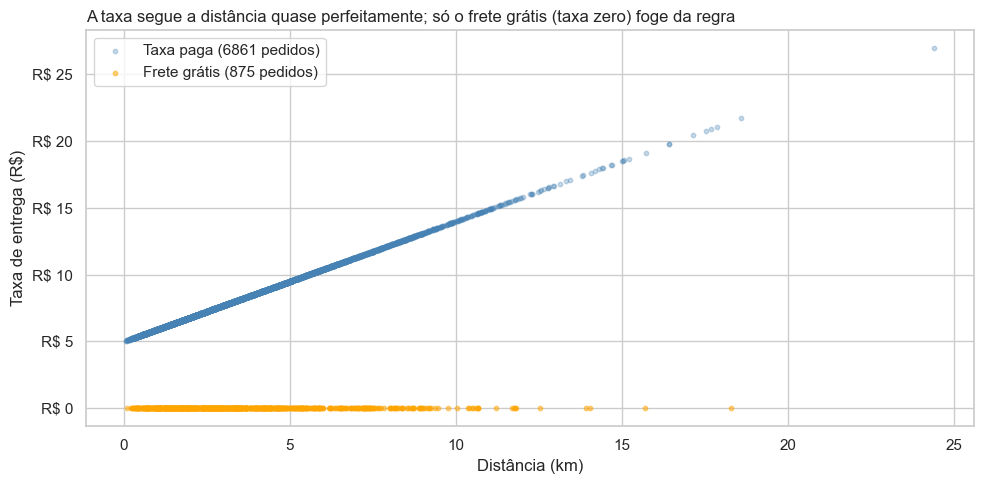

=== CORRELAÇÃO DE PEARSON: DISTÂNCIA × TAXA ===
Todos os pedidos:     0,5780
Só com taxa paga:     1,0000

=== FÓRMULA DA TAXA ===
Taxa = R$ 4,99 + R$ 0,90 por km

=== DISTÂNCIAS FALTANTES ===
Total sem distância: 322
Com taxa paga (dá para calcular a distância): 297
Com frete grátis (não dá para calcular): 25


In [63]:
# ============================================================
# TAREFA 8.3 - UMA CORRELAÇÃO "ESTRANHA"
# ============================================================

# 1. Usar só pedidos que têm distância
com_distancia = df.dropna(subset=["distancia_km"])

# 2. Separar os pedidos com taxa paga e com frete grátis
frete_pago = com_distancia[com_distancia["taxa_entrega"] > 0]
frete_gratis = com_distancia[com_distancia["taxa_entrega"] == 0]

# 3. Gráfico de dispersão distância × taxa
fig, ax = plt.subplots()

ax.scatter(frete_pago["distancia_km"], frete_pago["taxa_entrega"],
           color=cor_principal, alpha=0.3, s=10,
           label=f"Taxa paga ({len(frete_pago)} pedidos)")

ax.scatter(frete_gratis["distancia_km"], frete_gratis["taxa_entrega"],
           color=cor_destaque, alpha=0.5, s=10,
           label=f"Frete grátis ({len(frete_gratis)} pedidos)")

ax.set_title("A taxa segue a distância quase perfeitamente; "
             "só o frete grátis (taxa zero) foge da regra", loc="left")
ax.set_xlabel("Distância (km)")
ax.set_ylabel("Taxa de entrega (R$)")
ax.yaxis.set_major_formatter(formatador_reais)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# 4. Comparar a correlação com e sem o frete grátis
r_todos = com_distancia["distancia_km"].corr(com_distancia["taxa_entrega"])
r_pago = frete_pago["distancia_km"].corr(frete_pago["taxa_entrega"])

print("=== CORRELAÇÃO DE PEARSON: DISTÂNCIA × TAXA ===")
print(f"Todos os pedidos:     {r_todos:.4f}".replace(".", ","))
print(f"Só com taxa paga:     {r_pago:.4f}".replace(".", ","))

# 5. Descobrir a fórmula da taxa (só com os pedidos que pagaram)
# polyfit devolve [quanto a taxa sobe por km, valor quando a distância é zero]
por_km, taxa_fixa = np.polyfit(frete_pago["distancia_km"], frete_pago["taxa_entrega"], 1)

print("\n=== FÓRMULA DA TAXA ===")
print(f"Taxa = R$ {taxa_fixa:.2f} + R$ {por_km:.2f} por km".replace(".", ","))

# 6. Quantas distâncias faltantes poderiam ser recuperadas pela taxa
sem_distancia = df[df["distancia_km"].isna()]
recuperaveis = (sem_distancia["taxa_entrega"] > 0).sum()
nao_recuperaveis = (sem_distancia["taxa_entrega"] == 0).sum()

print("\n=== DISTÂNCIAS FALTANTES ===")
print(f"Total sem distância: {len(sem_distancia)}")
print(f"Com taxa paga (dá para calcular a distância): {recuperaveis}")
print(f"Com frete grátis (não dá para calcular): {nao_recuperaveis}")

Investiguei por que a correlação entre distância e taxa de entrega era de apenas 0,58.

Criei um gráfico de dispersão e percebi que os pedidos com taxa positiva formam praticamente uma linha reta, enquanto os pedidos com frete grátis aparecem com taxa zero, mesmo tendo distâncias diferentes.

Encontrei 900 pedidos com frete grátis, sendo que 875 tinham distância registrada. Também observei que todos os pedidos com frete grátis utilizaram cupom.

Quando calculei a correlação apenas dos pedidos com taxa positiva, o resultado ficou próximo de 1, mostrando uma relação quase perfeitamente linear.

Encontrei uma fórmula aproximada para a taxa: R\$ 4,99 fixos mais R\$ 0,90 por quilômetro.

Essa fórmula poderia ajudar a estimar as distâncias ausentes. Dos 322 pedidos sem distância, 297 possuem taxa positiva e poderiam receber uma distância estimada.

Os outros 25 pedidos possuem frete grátis, então não consigo estimar a distância usando apenas a taxa.

Concluí que os pedidos com frete grátis explicam a queda da correlação geral. Por enquanto, vou manter as distâncias ausentes como NaN e registrar a possibilidade de estimá-las, sem alterar os dados utilizados nas outras análises.

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

In [64]:
# ============================================================
# TAREFA 8.4 - APOIO: CHUVA POR MÊS
# ============================================================

# 1. Uma linha por cidade-dia (a chuva é a mesma para todos os pedidos do dia)
dias_cidade = df.groupby(["cidade", "data"]).agg(
    chuva=("chuva", "first"),
    mes=("mes", "first")
)

# 2. Porcentagem de cidade-dias com chuva em cada mês
chuva_por_mes = dias_cidade.groupby("mes")["chuva"].mean() * 100

nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

print("=== DIAS COM CHUVA POR MÊS ===")
for mes in chuva_por_mes.index:
    valor = f"{chuva_por_mes[mes]:.0f}%"
    print(f"{nomes_meses[mes - 1]}: {valor}")

=== DIAS COM CHUVA POR MÊS ===
Jan: 48%
Fev: 34%
Mar: 48%
Abr: 11%
Mai: 11%
Jun: 16%
Jul: 20%
Ago: 16%
Set: 16%
Out: 15%
Nov: 15%
Dez: 54%


**Correlação 1 — Chuva e quantidade de pedidos por dia (Tarefa 6.8)**

Na Tarefa 6.8 vi que, nas três cidades, os dias com chuva tiveram mais pedidos por dia. Em São Paulo, por exemplo, foram 13,22 pedidos por dia com chuva contra 10,40 sem chuva.

Parece razoável pensar que a chuva causa mais pedidos, porque as pessoas saem menos de casa. Mas existe uma variável escondida: a época do ano. Quando calculei a porcentagem de dias com chuva por mês, vi que a chuva se concentra em dezembro (54% dos dias) e em janeiro e março (48%), enquanto de abril a novembro fica entre 11% e 20%. E dezembro também foi o mês com mais pedidos do ano (840), talvez por causa das festas e do crescimento que vi na Tarefa 6.9.

Então parte da diferença pode ser "dezembro tem mais pedidos", e não "chuva traz mais pedidos". Para separar as duas coisas, eu teria que comparar dias com e sem chuva dentro do mesmo mês.

**Correlação 2 — Cupom e cliente novo (Tarefas 6.7 e 7.8)**

Entre os pedidos com cupom, 34,35% foram de clientes novos, contra 12,81% nos pedidos sem cupom.

Daria para pensar que o cupom atrai clientes novos. Mas a causa pode ser ao contrário: muitos apps dão um cupom de boas-vindas para quem está fazendo o primeiro pedido. Nesse caso, é ser cliente novo que faz o pedido ter cupom, e não o cupom que cria o cliente novo.

A variável escondida aqui seria a regra do app para dar cupom, que eu não tenho na base. Sem saber quem recebeu cupom e por quê, não dá para dizer que o cupom trouxe clientes novos.

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [65]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [66]:
# ============================================================
# TAREFA 9.1 - H1: CHUVA E TEMPO DE ENTREGA
# ============================================================

# H0: O tempo médio com chuva é menor ou igual ao tempo sem chuva.
# H1: O tempo médio com chuva é maior do que o tempo sem chuva.
#
# Teste: t de Welch unilateral.
# Nível de significância: 5%.

# 1. Separar os tempos válidos dos dois grupos
# dropna() retira os valores ausentes (NaN) apenas da análise
tempo_com_chuva = df.loc[
    df["chuva"] == True, "tempo_entrega_min"
].dropna()

tempo_sem_chuva = df.loc[
    df["chuva"] == False, "tempo_entrega_min"
].dropna()

# 2. Aplicar o teste t de Welch
# equal_var=False: não exige variâncias iguais
# alternative="greater": testa se a média com chuva é maior
teste = stats.ttest_ind(
    tempo_com_chuva,
    tempo_sem_chuva,
    equal_var=False,
    alternative="greater"
)

# Guardar os resultados do teste
estatistica_t = teste.statistic
p_valor = teste.pvalue

# 3. Calcular as médias e a diferença em minutos
media_com = tempo_com_chuva.mean()
media_sem = tempo_sem_chuva.mean()

diferenca_min = media_com - media_sem

# 4. Calcular o tamanho do efeito: d de Cohen
# Primeiro, contar os pedidos válidos de cada grupo
n_com = len(tempo_com_chuva)
n_sem = len(tempo_sem_chuva)

# Calcular o desvio padrão combinado
desvio_combinado = np.sqrt(
    (
        (n_com - 1) * tempo_com_chuva.var()
        + (n_sem - 1) * tempo_sem_chuva.var()
    ) / (n_com + n_sem - 2)
)

# Calcular o d de Cohen
d_cohen = diferenca_min / desvio_combinado

# 5. Tomar a decisão com nível de significância de 5%
if p_valor < ALFA:
    decisao = "Rejeita H0"
else:
    decisao = "Não rejeita H0"

# 6. Mostrar os resultados em português
print("=== H1: CHUVA E TEMPO DE ENTREGA ===")

print(
    f"Pedidos com chuva: {n_com} | "
    f"Média: {media_com:.2f} minutos".replace(".", ",")
)

print(
    f"Pedidos sem chuva: {n_sem} | "
    f"Média: {media_sem:.2f} minutos".replace(".", ",")
)

print("\n=== RESULTADO DO TESTE ===")

print(
    f"Estatística t: {estatistica_t:.2f}"
    .replace(".", ",")
)

print(f"p-valor: {p_valor:.2e}")

print(
    f"Diferença entre as médias: {diferenca_min:.2f} minutos"
    .replace(".", ",")
)

print(
    f"d de Cohen: {d_cohen:.2f}"
    .replace(".", ",")
)

print(f"Nível de significância: {ALFA * 100:.0f}%")
print(f"Decisão: {decisao}")

# 7. Mostrar uma interpretação simples
if p_valor < ALFA:
    print(
        "\nExiste evidência estatística de que o tempo médio "
        "de entrega é maior nos pedidos com chuva."
    )
else:
    print(
        "\nNão encontramos evidência estatística suficiente "
        "para afirmar que o tempo médio é maior com chuva."
    )

# 8. Guardar o resultado para a Tarefa 9.7
resultados.append({
    "hipotese": "H1 - Chuva e tempo de entrega",
    "teste": "t de Welch unilateral",
    "estatistica": round(estatistica_t, 2),
    "p_valor": p_valor,
    "efeito": (
        f"+{diferenca_min:.2f} min "
        f"(d = {d_cohen:.2f})"
    ).replace(".", ","),
    "decisao": decisao
})



=== H1: CHUVA E TEMPO DE ENTREGA ===
Pedidos com chuva: 2358 | Média: 42,36 minutos
Pedidos sem chuva: 5667 | Média: 33,23 minutos

=== RESULTADO DO TESTE ===
Estatística t: 36,16
p-valor: 3.23e-251
Diferença entre as médias: 9,13 minutos
d de Cohen: 0,89
Nível de significância: 5%
Decisão: Rejeita H0

Existe evidência estatística de que o tempo médio de entrega é maior nos pedidos com chuva.


**H0:** o tempo médio de entrega com chuva é menor ou igual ao tempo médio sem chuva.

**H1:** o tempo médio de entrega com chuva é maior do que sem chuva.

**Teste utilizado:** escolhi o teste t de Welch unilateral porque quero comparar as médias de dois grupos sem precisar considerar que tenham a mesma variância. O teste é unilateral porque quero verificar se o tempo com chuva é maior.

**Resultado:** a estatística t foi de 36,16 e o p-valor foi de aproximadamente 3,23 × 10⁻²⁵¹, muito menor que 0,05.

**Tamanho do efeito:** os pedidos sem chuva tiveram média de 33,23 minutos, enquanto os pedidos com chuva tiveram média de 42,36 minutos, uma diferença de 9,13 minutos. O d de Cohen foi de 0,89, considerado um efeito grande pela classificação usual.

**Decisão:** rejeitei H0 ao nível de significância de 5%.

**Interpretação para o negócio:** os pedidos com chuva apresentaram, em média, cerca de 9 minutos a mais no tempo de entrega. Essa diferença é importante e pode ajudar no planejamento da operação.

**Limitações:** a chuva é registrada por cidade e dia, então pedidos realizados no mesmo local e na mesma data podem não ser independentes. Isso pode afetar o p-valor do teste.

Na Tarefa 8.2 vi que, para distâncias parecidas, a reta com chuva continua cerca de 9 minutos acima da reta sem chuva. Então a distância não explica essa diferença.

Também pensei na época do ano, porque na Tarefa 8.4 vi que a chuva se concentra em dezembro, janeiro e março. Mas a diferença de cerca de 9 minutos é parecida com o que encontrei na Tarefa 7.6, então não parece ser explicada só pela estação. Ainda assim, existem fatores que a base não registra e que podem acompanhar a chuva, como o trânsito, a quantidade de entregadores disponíveis e o volume maior de pedidos nos dias chuvosos (Tarefa 6.8). Portanto, o resultado mostra uma associação forte, mas não comprova que a chuva seja a causa do aumento no tempo de entrega.

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [67]:
# ============================================================
# TAREFA 9.2 - H2: CUPOM E VALOR DO PEDIDO
# ============================================================

# H0: O ticket com cupom é igual ao sem cupom.
# H1: O ticket com cupom é diferente do sem cupom.
#
# Teste planejado: t de Welch bilateral.
# Teste mais adequado: Mann-Whitney bilateral.
# Nível de significância: 5%.

# 1. Separar os valores dos pedidos em dois grupos
com_cupom = df.loc[
    df["cupom"] == True, "valor_pedido"
].dropna()

sem_cupom = df.loc[
    df["cupom"] == False, "valor_pedido"
].dropna()

# 2. Calcular médias e medianas
media_com = com_cupom.mean()
media_sem = sem_cupom.mean()

mediana_com = com_cupom.median()
mediana_sem = sem_cupom.median()

# Diferença do grupo com cupom em relação ao sem cupom
diferenca_media = media_com - media_sem
diferenca_mediana = mediana_com - mediana_sem

# 3. Aplicar o teste t de Welch bilateral
# Compara as médias sem exigir variâncias iguais
teste_welch = stats.ttest_ind(
    com_cupom,
    sem_cupom,
    equal_var=False,
    alternative="two-sided"
)

# 4. Aplicar o teste de Mann-Whitney bilateral
# Compara os grupos usando a ordem dos valores
# (não é afetado pelo tamanho dos pedidos muito altos)
teste_mann = stats.mannwhitneyu(
    com_cupom,
    sem_cupom,
    alternative="two-sided"
)

# 5. Guardar os resultados dos testes
estatistica_t = teste_welch.statistic
p_welch = teste_welch.pvalue

estatistica_u = teste_mann.statistic
p_mann = teste_mann.pvalue

# 6. Tomar a decisão de cada teste
if p_welch < ALFA:
    decisao = "Rejeita H0"
else:
    decisao = "Não rejeita H0"

if p_mann < ALFA:
    decisao_mann = "Rejeita H0"
else:
    decisao_mann = "Não rejeita H0"

# 7. Mostrar os resultados
print("=== H2: CUPOM E VALOR DO PEDIDO ===")

print(f"Pedidos com cupom: {len(com_cupom)}")
print(f"Pedidos sem cupom: {len(sem_cupom)}")

print("\n=== VALORES DOS PEDIDOS ===")

print(f"Média com cupom: R$ {media_com:.2f}".replace(".", ","))
print(f"Média sem cupom: R$ {media_sem:.2f}".replace(".", ","))

print(f"Mediana com cupom: R$ {mediana_com:.2f}".replace(".", ","))
print(f"Mediana sem cupom: R$ {mediana_sem:.2f}".replace(".", ","))

print(f"Diferença das médias: R$ {diferenca_media:.2f}".replace(".", ","))
print(f"Diferença das medianas: R$ {diferenca_mediana:.2f}".replace(".", ","))

print("\n=== TESTE T DE WELCH (planejado) ===")

print(f"Estatística t: {estatistica_t:.4f}".replace(".", ","))
print(f"p-valor: {p_welch:.4e}")
print(f"Decisão: {decisao}")

print("\n=== TESTE DE MANN-WHITNEY (mais adequado) ===")

print(f"Estatística U: {estatistica_u:.1f}".replace(".", ","))
print(f"p-valor: {p_mann:.4e}")
print(f"Decisão: {decisao_mann}")

# 8. Interpretar o resultado
if p_mann < ALFA:
    print(
        "\nExiste evidência estatística de diferença "
        "no valor dos pedidos com e sem cupom."
    )
else:
    print(
        "\nNão encontramos evidência estatística suficiente "
        "de diferença no valor dos pedidos com e sem cupom."
    )

# 9. Guardar os DOIS testes para a Tarefa 9.7
resultados.append({
    "hipotese": "H2 - Cupom e ticket",
    "teste": "t de Welch bilateral",
    "estatistica": round(estatistica_t, 2),
    "p_valor": p_welch,
    "efeito": f"R$ {diferenca_media:.2f} na média".replace(".", ","),
    "decisao": decisao
})

resultados.append({
    "hipotese": "H2 - Cupom e ticket",
    "teste": "Mann-Whitney bilateral",
    "estatistica": round(estatistica_u, 1),
    "p_valor": p_mann,
    "efeito": f"R$ {diferenca_mediana:.2f} na mediana".replace(".", ","),
    "decisao": decisao_mann
})

=== H2: CUPOM E VALOR DO PEDIDO ===
Pedidos com cupom: 1709
Pedidos sem cupom: 6349

=== VALORES DOS PEDIDOS ===
Média com cupom: R$ 67,64
Média sem cupom: R$ 72,61
Mediana com cupom: R$ 57,22
Mediana sem cupom: R$ 62,82
Diferença das médias: R$ -4,97
Diferença das medianas: R$ -5,60

=== TESTE T DE WELCH (planejado) ===
Estatística t: -2,8145
p-valor: 4.9238e-03
Decisão: Rejeita H0

=== TESTE DE MANN-WHITNEY (mais adequado) ===
Estatística U: 4777274,5
p-valor: 3.1891e-14
Decisão: Rejeita H0

Existe evidência estatística de diferença no valor dos pedidos com e sem cupom.


**H0:** o valor dos pedidos com cupom é igual ao valor dos pedidos sem cupom.

**H1:** o valor dos pedidos com cupom é diferente do valor dos pedidos sem cupom.

**Testes utilizados:** fiz o teste t de Welch bilateral, que planejei na Tarefa 1.2, porque ele compara as médias de dois grupos sem exigir variâncias iguais. Também fiz o teste de Mann-Whitney bilateral, que compara os grupos pela ordem dos valores.

**Por que o t de Welch é frágil aqui:** ele compara médias, e o valor do pedido tem uma cauda muito longa (assimetria de 17,52 na Tarefa 5.1) por causa dos pedidos grandes, de até R\$ 2.299. Esses poucos pedidos puxam a média e aumentam muito a variação dentro dos grupos, o que esconde a diferença. O Mann-Whitney não é afetado pelo tamanho desses valores extremos, porque olha só a posição de cada pedido quando todos são colocados em ordem. É o mesmo motivo pelo qual escolhi a mediana como ticket típico na Tarefa 4.5.

**Resultados:**
- t de Welch: t = -2,81 e p-valor = 0,0049.
- Mann-Whitney: U = 4.777.274,5 e p-valor = 3,19 × 10⁻¹⁴.

Os dois testes apontam na mesma direção. Considero o Mann-Whitney o resultado principal, porque ele não depende da média, que é puxada pelos pedidos muito altos.

**Tamanho do efeito:** a mediana foi de R\$ 57,22 com cupom e R\$ 62,82 sem cupom, uma diferença de R\$ 5,60 a menos nos pedidos com cupom (cerca de 9%). Na média, a diferença foi de R\$ 4,97.

**Decisão:** rejeitei H0 ao nível de significância de 5%, com base principalmente no Mann-Whitney.

**Interpretação para o negócio:** nesta base, os pedidos com cupom têm ticket típico cerca de R\$ 5,60 menor. Ou seja, o uso de cupom não veio acompanhado de pedidos maiores. Não consigo avaliar se o desconto se paga, porque a base não informa o valor do desconto nem o custo da campanha.

**Cuidados:** não sei se o valor_pedido já tem o desconto do cupom descontado. Se tiver, parte da diferença é o próprio desconto. Além disso, 34,35% dos pedidos com cupom são de clientes novos (Tarefa 6.7), que podem pedir menos. Por isso, não posso afirmar que o cupom causou a diferença.

### Pergunta 2 (Tarefa 1.1) — cliente novo × valor do pedido
Na Etapa 1 perguntei se clientes novos gastam diferente dos recorrentes. Essa pergunta não tinha sido respondida em nenhuma tarefa, então respondo aqui.

In [68]:
# ============================================================
# PERGUNTA 2 (Tarefa 1.1) - CLIENTE NOVO E VALOR DO PEDIDO
# ============================================================

# Pergunta: o valor dos pedidos de clientes novos é diferente
# do valor dos pedidos de clientes recorrentes?
#
# Uso a mediana e o Mann-Whitney pelo mesmo motivo da Tarefa 9.2:
# o valor do pedido tem cauda longa (pedidos muito caros puxam a média).

# 1. Separar os dois grupos
novos = df.loc[df["cliente_novo"] == True, "valor_pedido"].dropna()
recorrentes = df.loc[df["cliente_novo"] == False, "valor_pedido"].dropna()

print("=== P2: CLIENTE NOVO E VALOR DO PEDIDO ===")
print(f"Pedidos de clientes novos: {len(novos)}")
print(f"Pedidos de clientes recorrentes: {len(recorrentes)}")

# 2. Comparar médias e medianas
print(f"\nMediana novos: R$ {novos.median():.2f}".replace(".", ","))
print(f"Mediana recorrentes: R$ {recorrentes.median():.2f}".replace(".", ","))
print(f"Diferença das medianas: R$ {novos.median() - recorrentes.median():.2f}".replace(".", ","))
print(f"Média novos: R$ {novos.mean():.2f}".replace(".", ","))
print(f"Média recorrentes: R$ {recorrentes.mean():.2f}".replace(".", ","))

# 3. Teste de Mann-Whitney bilateral
teste_p2 = stats.mannwhitneyu(novos, recorrentes, alternative="two-sided")
print(f"\nMann-Whitney: p-valor = {teste_p2.pvalue:.4f}".replace(".", ","))

# 4. Tamanho do efeito (correlação rank-biserial)
# Vai de 0 a 1: perto de 0 significa diferença muito pequena
r_p2 = 1 - 2 * teste_p2.statistic / (len(novos) * len(recorrentes))
print(f"Tamanho do efeito (rank-biserial): {abs(r_p2):.3f}".replace(".", ","))

# 5. Separar por cupom
# Clientes novos usam mais cupom (Tarefa 9.5), e pedidos com cupom
# têm ticket menor (Tarefa 9.2). Será que o cupom explica a diferença?
print("\n=== MESMA COMPARAÇÃO, SEPARANDO POR CUPOM ===")
for usou_cupom in [False, True]:
    grupo = df[df["cupom"] == usou_cupom]
    a = grupo.loc[grupo["cliente_novo"] == True, "valor_pedido"].dropna()
    b = grupo.loc[grupo["cliente_novo"] == False, "valor_pedido"].dropna()
    p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    nome = "Com cupom" if usou_cupom else "Sem cupom"
    print(f"{nome}: novos R$ {a.median():.2f} | recorrentes R$ {b.median():.2f} | p-valor = {p:.2f}".replace(".", ","))


=== P2: CLIENTE NOVO E VALOR DO PEDIDO ===
Pedidos de clientes novos: 1400
Pedidos de clientes recorrentes: 6658

Mediana novos: R$ 59,76
Mediana recorrentes: R$ 61,87
Diferença das medianas: R$ -2,11
Média novos: R$ 71,30
Média recorrentes: R$ 71,61

Mann-Whitney: p-valor = 0,0121
Tamanho do efeito (rank-biserial): 0,043

=== MESMA COMPARAÇÃO, SEPARANDO POR CUPOM ===
Sem cupom: novos R$ 61,94 | recorrentes R$ 62,97 | p-valor = 0,30
Com cupom: novos R$ 56,24 | recorrentes R$ 57,91 | p-valor = 0,91


**Pergunta:** o valor dos pedidos de clientes novos é diferente do valor dos pedidos de clientes recorrentes?

**Teste utilizado:** Mann-Whitney bilateral, comparando as medianas, pelo mesmo motivo da Tarefa 9.2: o valor do pedido tem cauda longa.

**Resultado:** a mediana dos clientes novos foi de R\$ 59,76, contra R\$ 61,87 dos recorrentes, uma diferença de só R\$ 2,11. As médias ficaram praticamente iguais (R\$ 71,30 × R\$ 71,61). O Mann-Whitney deu p-valor = 0,012, abaixo de 0,05, mas o tamanho do efeito foi muito pequeno (0,04).

**O cupom explica a diferença:** os clientes novos usam muito mais cupom (Tarefa 9.5), e os pedidos com cupom têm ticket menor (Tarefa 9.2). Quando separei os pedidos com e sem cupom, a diferença entre novos e recorrentes desapareceu (p-valor = 0,30 sem cupom e 0,91 com cupom).

**Conclusão para o negócio:** o cliente novo não gasta diferente do recorrente. A pequena diferença geral vem do cupom, que o cliente novo usa mais. Por isso o p-valor sozinho não basta: é preciso olhar o tamanho do efeito e possíveis variáveis escondidas.

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [69]:
# ============================================================
# TAREFA 9.3 - H3: TEMPO DE ENTREGA × AVALIAÇÃO
# H0: não existe correlação negativa entre tempo e avaliação
# H1: existe correlação negativa (mais tempo, nota menor)
# Testes: Spearman unilateral e Mann-Whitney unilateral
# ============================================================

# 1. Usar só pedidos que têm tempo válido E avaliação
validos = df.dropna(subset=["tempo_entrega_min", "avaliacao"])

# ------------------------------------------------------------
# 2. TESTE 1: correlação de Spearman
# alternative="less": testa se a correlação é MENOR que zero (negativa)
# ------------------------------------------------------------
teste_spearman = stats.spearmanr(
    validos["tempo_entrega_min"],
    validos["avaliacao"],
    alternative="less"
)

rho = teste_spearman.statistic
p_spearman = teste_spearman.pvalue

# ------------------------------------------------------------
# 3. TESTE 2: até 35 min × acima de 35 min (Mann-Whitney)
# ------------------------------------------------------------
nota_ate_35 = validos.loc[validos["tempo_entrega_min"] <= 35, "avaliacao"]
nota_acima_35 = validos.loc[validos["tempo_entrega_min"] > 35, "avaliacao"]

# alternative="greater": testa se as notas "até 35" são MAIORES
teste_mw = stats.mannwhitneyu(nota_ate_35, nota_acima_35, alternative="greater")

# ------------------------------------------------------------
# 4. Tamanho do efeito em linguagem de negócio
# ------------------------------------------------------------
# Média das notas
media_ate = nota_ate_35.mean()
media_acima = nota_acima_35.mean()

# % de notas baixas (1, 2 ou 3) em cada grupo
baixas_ate = (nota_ate_35 <= 3).mean() * 100
baixas_acima = (nota_acima_35 <= 3).mean() * 100

# % de notas 5 em cada grupo
cinco_ate = (nota_ate_35 == 5).mean() * 100
cinco_acima = (nota_acima_35 == 5).mean() * 100

# ------------------------------------------------------------
# 5. Decisões ao nível de 5%
# ------------------------------------------------------------
if p_spearman < ALFA:
    decisao_spearman = "Rejeita H0"
else:
    decisao_spearman = "Não rejeita H0"

if teste_mw.pvalue < ALFA:
    decisao_mw = "Rejeita H0"
else:
    decisao_mw = "Não rejeita H0"

# ------------------------------------------------------------
# 6. Mostrar os resultados
# ------------------------------------------------------------
print("=== H3: TEMPO DE ENTREGA × AVALIAÇÃO ===")
print(f"Pedidos com tempo e avaliação: {len(validos)}")

print("\n--- Teste 1: correlação de Spearman ---")
print(f"rho de Spearman: {rho:.2f}".replace(".", ","))
print(f"p-valor: {p_spearman:.2e}")
print(f"Decisão: {decisao_spearman}")

print("\n--- Teste 2: até 35 min × acima de 35 min (Mann-Whitney) ---")
print(f"Até 35 min:     {len(nota_ate_35)} pedidos | nota média {media_ate:.2f}".replace(".", ","))
print(f"Acima de 35 min: {len(nota_acima_35)} pedidos | nota média {media_acima:.2f}".replace(".", ","))
print(f"Estatística U: {teste_mw.statistic:.0f}")
print(f"p-valor: {teste_mw.pvalue:.2e}")
print(f"Decisão: {decisao_mw}")

print("\n--- Tamanho do efeito ---")
print(f"Notas baixas (1 a 3): {baixas_ate:.1f}% até 35 min | "
      f"{baixas_acima:.1f}% acima de 35 min".replace(".", ","))
print(f"Notas 5:              {cinco_ate:.1f}% até 35 min | "
      f"{cinco_acima:.1f}% acima de 35 min".replace(".", ","))

# ------------------------------------------------------------
# 7. Guardar os dois testes na lista de resultados
# ------------------------------------------------------------
resultados.append({
    "hipotese": "H3 - Tempo × avaliação",
    "teste": "Spearman (unilateral, negativa)",
    "estatistica": round(rho, 2),
    "p_valor": p_spearman,
    "efeito": f"rho = {rho:.2f} (correlação fraca)".replace(".", ","),
    "decisao": decisao_spearman
})

resultados.append({
    "hipotese": "H3 - Até 35 min × acima de 35 min",
    "teste": "Mann-Whitney (unilateral)",
    "estatistica": round(teste_mw.statistic, 0),
    "p_valor": teste_mw.pvalue,
    "efeito": f"notas baixas: {baixas_ate:.1f}% → {baixas_acima:.1f}%".replace(".", ","),
    "decisao": decisao_mw
})

=== H3: TEMPO DE ENTREGA × AVALIAÇÃO ===
Pedidos com tempo e avaliação: 6685

--- Teste 1: correlação de Spearman ---
rho de Spearman: -0,24
p-valor: 7.75e-92
Decisão: Rejeita H0

--- Teste 2: até 35 min × acima de 35 min (Mann-Whitney) ---
Até 35 min:     3426 pedidos | nota média 4,49
Acima de 35 min: 3259 pedidos | nota média 4,20
Estatística U: 6766416
p-valor: 6.32e-62
Decisão: Rejeita H0

--- Tamanho do efeito ---
Notas baixas (1 a 3): 6,5% até 35 min | 15,4% acima de 35 min
Notas 5:              55,3% até 35 min | 37,0% acima de 35 min


**H0:** não existe correlação negativa entre o tempo de entrega e a avaliação.

**H1:** existe correlação negativa, ou seja, entregas mais demoradas tendem a receber avaliações menores.

**Testes utilizados:** usei a correlação de Spearman unilateral porque a avaliação é uma nota de 1 a 5. Também utilizei o teste de Mann-Whitney unilateral para comparar as avaliações dos pedidos entregues até 35 minutos com os entregues acima de 35 minutos.

**Hipóteses do segundo teste:**
- **H0:** as avaliações dos pedidos entregues até 35 minutos não são maiores que as dos pedidos entregues acima de 35 minutos.
- **H1:** as avaliações dos pedidos entregues até 35 minutos tendem a ser maiores.

**Resultados:** a correlação de Spearman foi de -0,24, com p-valor de 7,75 × 10⁻⁹². No teste de Mann-Whitney, a estatística U foi de 6.766.416, com p-valor de 6,32 × 10⁻⁶². Os dois p-valores ficaram muito abaixo de 0,05.

**Tamanho do efeito:** a nota média foi de 4,49 nas entregas até 35 minutos e de 4,20 nas entregas acima de 35 minutos.

As notas baixas (1 a 3) passaram de 6,5% para 15,4%, uma diferença de 8,9 pontos percentuais. Isso significa que as notas baixas foram aproximadamente 2,37 vezes mais frequentes nas entregas acima de 35 minutos.

Já as notas 5 diminuíram de 55,3% para 37,0%.

**Decisão:** rejeitei H0 nos dois testes, utilizando o nível de significância de 5%.

**Interpretação para o negócio:** os pedidos entregues acima de 35 minutos apresentaram uma proporção maior de avaliações baixas. Isso indica que o tempo de entrega é um indicador importante para acompanhar a experiência dos clientes.

**Limitações:** na Tarefa 7.7 observei que a queda nas avaliações ficou mais evidente a partir de 40 minutos. Portanto, o corte de 35 minutos reúne pedidos com comportamentos diferentes e pode influenciar o tamanho da diferença encontrada. Além disso, os testes mostram uma associação, mas não comprovam que a demora seja a causa das notas menores.

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [70]:
# ============================================================
# TAREFA 9.4 - H4: TIPO DE COZINHA E TICKET
# ============================================================

# H0: As distribuições dos valores dos pedidos são iguais
#     entre todos os tipos de cozinha.
#
# H1: Pelo menos uma cozinha apresenta distribuição diferente.
#
# Teste principal: Kruskal-Wallis.
# Teste complementar: ANOVA.
# Nível de significância: 5%.

# 1. Separar os valores de cada tipo de cozinha
cozinhas = df["tipo_cozinha"].dropna().unique()

grupos = []

for cozinha in cozinhas:
    valores_cozinha = df.loc[
        df["tipo_cozinha"] == cozinha,
        "valor_pedido"
    ].dropna()

    grupos.append(valores_cozinha)

# Contar a quantidade de grupos e pedidos válidos
k = len(grupos)
n = sum(len(grupo) for grupo in grupos)

# ============================================================
# 2. TESTE PRINCIPAL: KRUSKAL-WALLIS
# ============================================================

# O * envia cada grupo separadamente para o teste
teste_kw = stats.kruskal(*grupos)

# Guardar a estatística e o p-valor
estatistica_kw = teste_kw.statistic
p_kw = teste_kw.pvalue

# Calcular o tamanho do efeito: épsilon ao quadrado
epsilon2 = (estatistica_kw - k + 1) / (n - k)

# ============================================================
# 3. TESTE COMPLEMENTAR: ANOVA
# ============================================================

teste_anova = stats.f_oneway(*grupos)

# Guardar a estatística e o p-valor
estatistica_f = teste_anova.statistic
p_anova = teste_anova.pvalue

# ============================================================
# 4. TAMANHO DO EFEITO DA ANOVA: ETA AO QUADRADO
# ============================================================

# Calcular a média geral dos pedidos válidos
todos_valores = df["valor_pedido"].dropna()
media_geral = todos_valores.mean()

# Calcular a variação entre os grupos
variacao_entre = 0

for valores_cozinha in grupos:
    variacao_entre = variacao_entre + (
        len(valores_cozinha)
        * (valores_cozinha.mean() - media_geral) ** 2
    )

# Calcular a variação total
variacao_total = (
    (todos_valores - media_geral) ** 2
).sum()

# Calcular o eta ao quadrado
eta2 = variacao_entre / variacao_total

# ============================================================
# 5. CALCULAR AS MEDIANAS POR COZINHA
# ============================================================

medianas = df.groupby(
    "tipo_cozinha"
)["valor_pedido"].median()

# Ordenar da maior mediana para a menor
medianas = medianas.sort_values(ascending=False)

# Identificar as cozinhas com maior e menor mediana
mais_cara = medianas.index[0]
mais_barata = medianas.index[-1]

# Calcular quantas vezes a maior mediana supera a menor
razao = medianas[mais_cara] / medianas[mais_barata]

# ============================================================
# 6. TOMAR AS DECISÕES COM ALFA = 5%
# ============================================================

# Decisão do Kruskal-Wallis
if p_kw < ALFA:
    decisao_kw = "Rejeita H0"
else:
    decisao_kw = "Não rejeita H0"

# Decisão da ANOVA
if p_anova < ALFA:
    decisao_anova = "Rejeita H0"
else:
    decisao_anova = "Não rejeita H0"

# ============================================================
# 7. MOSTRAR OS RESULTADOS
# ============================================================

print("=== H4: TIPO DE COZINHA E TICKET ===")

print(f"Tipos de cozinha: {k}")
print(f"Pedidos analisados: {n}")

print("\n=== TESTE PRINCIPAL: KRUSKAL-WALLIS ===")

print(
    f"Estatística H: {estatistica_kw:.2f}"
    .replace(".", ",")
)

# Evitar apresentar p = 0 por limitação numérica
if p_kw < 0.001:
    print("p-valor: menor que 0,001")
else:
    print(f"p-valor: {p_kw:.4f}".replace(".", ","))

print(
    f"Épsilon ao quadrado: {epsilon2:.4f}"
    .replace(".", ",")
)

print(f"Decisão: {decisao_kw}")

print("\n=== TESTE COMPLEMENTAR: ANOVA ===")

print(
    f"Estatística F: {estatistica_f:.2f}"
    .replace(".", ",")
)

print(f"p-valor: {p_anova:.3e}")

print(
    f"Eta ao quadrado: {eta2:.4f}"
    .replace(".", ",")
)

print(f"Decisão: {decisao_anova}")

# ============================================================
# 8. MOSTRAR OS TICKETS MEDIANOS
# ============================================================

print("\n=== TICKET MEDIANO POR COZINHA ===")

for cozinha in medianas.index:
    valor = medianas[cozinha]

    print(
        f"{cozinha}: R$ {valor:.2f}"
        .replace(".", ",")
    )

print("\n=== COMPARAÇÃO ENTRE AS COZINHAS ===")

print(
    f"Maior ticket mediano: {mais_cara}"
)

print(
    f"Menor ticket mediano: {mais_barata}"
)

print(
    f"A maior mediana é {razao:.2f} vezes a menor"
    .replace(".", ",")
)

# ============================================================
# 9. GUARDAR OS RESULTADOS PARA A TAREFA 9.7
# ============================================================

# Registrar o teste principal
resultados.append({
    "hipotese": "H4 - Cozinha e ticket",
    "teste": "Kruskal-Wallis",
    "estatistica": round(estatistica_kw, 2),
    "p_valor": p_kw,
    "efeito": (
        f"epsilon² = {epsilon2:.2f}; "
        f"medianas de {medianas[mais_barata]:.2f} "
        f"a {medianas[mais_cara]:.2f} reais"
    ).replace(".", ","),
    "decisao": decisao_kw
})

# Registrar o teste complementar
resultados.append({
    "hipotese": "H4 - Cozinha e ticket",
    "teste": "ANOVA",
    "estatistica": round(estatistica_f, 2),
    "p_valor": p_anova,
    "efeito": f"eta² = {eta2:.2f}".replace(".", ","),
    "decisao": decisao_anova
})


=== H4: TIPO DE COZINHA E TICKET ===
Tipos de cozinha: 6
Pedidos analisados: 8058

=== TESTE PRINCIPAL: KRUSKAL-WALLIS ===
Estatística H: 3272,58
p-valor: menor que 0,001
Épsilon ao quadrado: 0,4058
Decisão: Rejeita H0

=== TESTE COMPLEMENTAR: ANOVA ===
Estatística F: 286,82
p-valor: 2.936e-283
Eta ao quadrado: 0,1512
Decisão: Rejeita H0

=== TICKET MEDIANO POR COZINHA ===
Japonesa: R$ 107,97
Pizza: R$ 74,31
Hambúrguer: R$ 61,67
Saudável: R$ 53,73
Brasileira: R$ 47,82
Doces: R$ 38,42

=== COMPARAÇÃO ENTRE AS COZINHAS ===
Maior ticket mediano: Japonesa
Menor ticket mediano: Doces
A maior mediana é 2,81 vezes a menor


**H0:** as distribuições dos valores dos pedidos são iguais entre os tipos de cozinha.

**H1:** pelo menos um tipo de cozinha apresenta uma distribuição diferente.

**Testes utilizados:** usei o Kruskal-Wallis porque estou comparando seis grupos e os valores dos pedidos apresentam valores extremos. Também utilizei a ANOVA para comparar as médias.

**Resultados:** o Kruskal-Wallis apresentou estatística H de 3.272,58 e p-valor menor que 0,001. A ANOVA apresentou estatística F de 286,82 e p-valor de aproximadamente 2,94 × 10⁻²⁸³, também muito abaixo de 0,05.

**Tamanho do efeito:** o épsilon quadrado do Kruskal-Wallis foi de 0,41, indicando uma diferença importante entre os grupos quando os valores são analisados por sua ordem. O eta quadrado da ANOVA foi de 0,15, mostrando que aproximadamente 15% da variação dos valores dos pedidos está associada às diferenças entre as cozinhas.

As duas medidas são calculadas de formas diferentes e não devem ser comparadas diretamente.

**Decisão:** rejeitei H0 nos dois testes, utilizando o nível de significância de 5%.

**Interpretação para o negócio:** a cozinha Japonesa apresentou o maior ticket mediano, de R\$ 107,97, enquanto Doces apresentou o menor, de R\$ 38,42. Isso significa que o ticket mediano da Japonesa foi aproximadamente 2,8 vezes o de Doces.

Essa diferença pode ajudar no planejamento de campanhas e na análise dos tipos de cozinha, mas seria necessário considerar custos e margens para avaliar quais são mais rentáveis.

**Limitação:** os testes mostram que existem diferenças entre os grupos, mas não identificam quais pares de cozinhas são estatisticamente diferentes. Para isso, seriam necessárias comparações adicionais.

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [71]:
# ============================================================
# TAREFA 9.5 - H5: CIDADE × FORMA DE PAGAMENTO (QUI-QUADRADO)
# H0: cidade e forma de pagamento são independentes
# H1: cidade e forma de pagamento estão associadas
# ============================================================

# ------------------------------------------------------------
# PARTE 1 - CIDADE × FORMA DE PAGAMENTO
# ------------------------------------------------------------

# 1. Tabela de contagem: quantos pedidos em cada combinação
tabela_pagamento = pd.crosstab(df["cidade"], df["forma_pagamento"])

print("=== H5: FREQUÊNCIAS OBSERVADAS (pedidos reais) ===")
display(tabela_pagamento)

# 2. Teste qui-quadrado
# Devolve 4 coisas: estatística, p-valor, graus de liberdade e a tabela esperada
qui2, p_valor, graus_liberdade, esperadas = stats.chi2_contingency(tabela_pagamento)

# Transformar a tabela esperada num DataFrame com os mesmos nomes
tabela_esperada = pd.DataFrame(
    esperadas,
    index=tabela_pagamento.index,
    columns=tabela_pagamento.columns
)

print("\n=== FREQUÊNCIAS ESPERADAS (se fossem independentes) ===")
display(tabela_esperada.round(1))

# 3. V de Cramér (tamanho do efeito)
total_pedidos = tabela_pagamento.values.sum()
linhas, colunas = tabela_pagamento.shape
menor_lado = min(linhas, colunas) - 1

v_cramer = np.sqrt(qui2 / (total_pedidos * menor_lado))

# 4. Decisão
if p_valor < ALFA:
    decisao = "Rejeita H0"
else:
    decisao = "Não rejeita H0"

print("\n=== RESULTADO DO TESTE ===")
print(f"Qui-quadrado: {qui2:.2f}".replace(".", ","))
print(f"Graus de liberdade: {graus_liberdade}")
print(f"p-valor: {p_valor:.4f}".replace(".", ","))
print(f"V de Cramér: {v_cramer:.3f}".replace(".", ","))
print(f"Decisão: {decisao}")

resultados.append({
    "hipotese": "H5 - Cidade × forma de pagamento",
    "teste": "Qui-quadrado de independência",
    "estatistica": round(qui2, 2),
    "p_valor": p_valor,
    "efeito": f"V de Cramér = {v_cramer:.3f} (desprezível)".replace(".", ","),
    "decisao": decisao
})

# ------------------------------------------------------------
# PARTE 2 - CONTRASTE: CUPOM × CLIENTE NOVO
# ------------------------------------------------------------

tabela_cupom = pd.crosstab(df["cupom"], df["cliente_novo"])

print("\n\n=== CONTRASTE: CUPOM × CLIENTE NOVO ===")
print("Frequências observadas:")
display(tabela_cupom)

qui2_c, p_valor_c, graus_c, esperadas_c = stats.chi2_contingency(tabela_cupom)

tabela_esperada_c = pd.DataFrame(
    esperadas_c,
    index=tabela_cupom.index,
    columns=tabela_cupom.columns
)

print("\nFrequências esperadas (se fossem independentes):")
display(tabela_esperada_c.round(1))

# V de Cramér: tabela 2 × 2, então o menor lado - 1 é 1
v_cramer_c = np.sqrt(qui2_c / (tabela_cupom.values.sum() * 1))

if p_valor_c < ALFA:
    decisao_c = "Rejeita H0"
else:
    decisao_c = "Não rejeita H0"

print(f"\nQui-quadrado: {qui2_c:.2f}".replace(".", ","))
print(f"Graus de liberdade: {graus_c}")
print(f"p-valor: {p_valor_c:.2e}")
print(f"V de Cramér: {v_cramer_c:.3f}".replace(".", ","))
print(f"Decisão: {decisao_c}")

resultados.append({
    "hipotese": "Contraste - Cupom × cliente novo",
    "teste": "Qui-quadrado de independência",
    "estatistica": round(qui2_c, 2),
    "p_valor": p_valor_c,
    "efeito": f"V de Cramér = {v_cramer_c:.3f}".replace(".", ","),
    "decisao": decisao_c
})

=== H5: FREQUÊNCIAS OBSERVADAS (pedidos reais) ===


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,755,112,532,233
Rio de Janeiro,1078,163,785,345
São Paulo,1809,286,1316,644



=== FREQUÊNCIAS ESPERADAS (se fossem independentes) ===


forma_pagamento,Cartão de crédito,Dinheiro,Pix,Vale-refeição
cidade,,,,
Belo Horizonte,737.6,113.6,533.3,247.5
Rio de Janeiro,1071.6,165.1,774.7,359.6
São Paulo,1832.8,282.3,1325.0,614.9



=== RESULTADO DO TESTE ===
Qui-quadrado: 3,86
Graus de liberdade: 6
p-valor: 0,6951
V de Cramér: 0,015
Decisão: Não rejeita H0


=== CONTRASTE: CUPOM × CLIENTE NOVO ===
Frequências observadas:


cliente_novo,False,True
cupom,,
False,5536,813
True,1122,587



Frequências esperadas (se fossem independentes):


cliente_novo,False,True
cupom,,
False,5245.9,1103.1
True,1412.1,296.9



Qui-quadrado: 433,80
Graus de liberdade: 1
p-valor: 2.42e-96
V de Cramér: 0,232
Decisão: Rejeita H0


**H0:** a cidade e a forma de pagamento são independentes.

**H1:** existe associação entre a cidade e a forma de pagamento.

**Teste utilizado:** usei o teste qui-quadrado de independência porque estou comparando duas variáveis categóricas. Também calculei o V de Cramér para medir o tamanho da associação.

**Resultado:** o qui-quadrado foi de 3,86, com 6 graus de liberdade, e o p-valor foi de 0,6951, maior que 0,05.

As frequências observadas ficaram próximas das esperadas. Em Belo Horizonte, por exemplo, foram registrados 755 pedidos com cartão de crédito, contra aproximadamente 737,6 esperados.

**Tamanho do efeito:** o V de Cramér foi de 0,015, indicando uma associação muito pequena entre cidade e forma de pagamento.

**Decisão:** não rejeitei H0 ao nível de significância de 5%.

**Interpretação para o negócio:** as formas de pagamento apresentaram proporções semelhantes nas três cidades analisadas. Com esses dados, não encontrei evidências que justifiquem estratégias diferentes de pagamento apenas pela cidade.

**Contraste — Cupom e cliente novo:** também apliquei o teste qui-quadrado para verificar a relação entre o uso de cupons e o perfil dos clientes.

Nesse segundo teste, encontrei qui-quadrado de 433,80, p-valor menor que 0,001 e V de Cramér de 0,232.

Se as variáveis fossem independentes, seriam esperados aproximadamente 297 pedidos com cupom feitos por clientes novos. Porém, foram observados 587 pedidos.

**Decisão do contraste:** rejeitei H0, pois encontrei evidências estatísticas de associação entre cupom e cliente novo.

**Conclusão para o negócio:** a forma de pagamento não apresentou associação relevante com a cidade, enquanto o uso de cupons apresentou associação com a participação de clientes novos.

**Limitações:** não rejeitar H0 não comprova independência absoluta. Além disso, a associação entre cupom e cliente novo não demonstra que os cupons causaram a chegada desses clientes.

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [72]:
# ============================================================
# TAREFA 9.6 - H6: PLATAFORMA X VALOR DO PEDIDO
# ============================================================

# H0: O ticket médio é igual entre Android, iOS e Web.
# H1: Pelo menos uma plataforma apresenta ticket médio diferente.
#
# Teste 1: ANOVA (planejado na Tarefa 1.2).
# Teste 2: Kruskal-Wallis (complementar).
# Teste 3: Kruskal-Wallis com ticket normalizado por cozinha.
#
# Nível de significância: 5%.

# ============================================================
# 1. SEPARAR AS PLATAFORMAS CONHECIDAS
# ============================================================

# Retirar somente da análise os pedidos sem plataforma informada
# O DataFrame original não será modificado
com_plataforma = df[
    df["plataforma"].isin(["Android", "iOS", "Web"])
].copy()

print("=== H6: PLATAFORMA E VALOR DO PEDIDO ===")

print(f"Pedidos analisados: {len(com_plataforma)}")
print(f"Pedidos sem plataforma: {len(df) - len(com_plataforma)}")

# ============================================================
# 2. SEPARAR OS PEDIDOS DE CADA PLATAFORMA
# ============================================================

plataformas = ["Android", "iOS", "Web"]

grupos_valor = []
grupos_razao = []

for plataforma in plataformas:

    # Selecionar os pedidos da plataforma
    pedidos_plataforma = com_plataforma[
        com_plataforma["plataforma"] == plataforma
    ]

    # Guardar os valores dos pedidos
    grupos_valor.append(
        pedidos_plataforma["valor_pedido"].dropna()
    )

    # Guardar os valores normalizados por cozinha
    grupos_razao.append(
        pedidos_plataforma["razao_mediana"].dropna()
    )

# Quantidade de grupos e pedidos
k = len(grupos_valor)
n = sum(len(grupo) for grupo in grupos_valor)

# ============================================================
# 3. MOSTRAR O RESUMO POR PLATAFORMA
# ============================================================

resumo_plataforma = com_plataforma.groupby(
    "plataforma"
)["valor_pedido"].agg(
    pedidos="count",
    media="mean",
    mediana="median"
)

print("\n=== VALOR DO PEDIDO POR PLATAFORMA ===")

display(resumo_plataforma.round(2))

# Calcular a diferença entre a maior e a menor mediana
diferenca_medianas = (
    resumo_plataforma["mediana"].max()
    - resumo_plataforma["mediana"].min()
)

print(
    f"\nDiferença entre a maior e a menor mediana: "
    f"R$ {diferenca_medianas:.2f}".replace(".", ",")
)

# ============================================================
# 4. TESTE 1: ANOVA
# ============================================================

# Comparar as médias das três plataformas
teste_anova = stats.f_oneway(*grupos_valor)

# Calcular o tamanho do efeito: eta ao quadrado
media_geral = com_plataforma["valor_pedido"].mean()

# Variação entre as plataformas
variacao_entre = 0

for valores in grupos_valor:
    variacao_entre = variacao_entre + (
        len(valores) * (valores.mean() - media_geral) ** 2
    )

# Variação total dos pedidos
variacao_total = (
    (com_plataforma["valor_pedido"] - media_geral) ** 2
).sum()

eta2 = variacao_entre / variacao_total

# ============================================================
# 5. TESTE 2: KRUSKAL-WALLIS
# ============================================================

# Comparar as distribuições utilizando a ordem dos valores
teste_kw = stats.kruskal(*grupos_valor)

# Calcular o tamanho do efeito: épsilon ao quadrado
epsilon2 = (
    teste_kw.statistic - k + 1
) / (n - k)

# O estimador pode ficar ligeiramente negativo quando o efeito é nulo.
# Como um tamanho de efeito negativo não tem interpretação prática,
# reportamos zero nesses casos.
epsilon2 = max(0, epsilon2)

# ============================================================
# 6. TESTE 3: COMPARAÇÃO NORMALIZADA POR COZINHA
# ============================================================

# A coluna razao_mediana foi criada na Tarefa 4.4.
#
# Ela compara o valor de cada pedido com a mediana
# do seu próprio tipo de cozinha.
#
# Isso ajuda a reduzir diferenças de escala entre cozinhas,
# mas não é um controle estatístico completo.

teste_controle = stats.kruskal(*grupos_razao)

# ============================================================
# 7. TOMAR AS DECISÕES COM ALFA = 5%
# ============================================================

# Decisão da ANOVA
if teste_anova.pvalue < ALFA:
    decisao_anova = "Rejeita H0"
else:
    decisao_anova = "Não rejeita H0"

# Decisão do Kruskal-Wallis
if teste_kw.pvalue < ALFA:
    decisao_kw = "Rejeita H0"
else:
    decisao_kw = "Não rejeita H0"

# Decisão da comparação normalizada
if teste_controle.pvalue < ALFA:
    decisao_controle = "Rejeita H0"
else:
    decisao_controle = "Não rejeita H0"

# ============================================================
# 8. MOSTRAR OS RESULTADOS DOS TESTES
# ============================================================

print("\n=== TESTE 1: ANOVA ===")

print(
    f"Estatística F: {teste_anova.statistic:.2f}"
    .replace(".", ",")
)

print(
    f"p-valor: {teste_anova.pvalue:.4f}"
    .replace(".", ",")
)

print(
    f"Eta ao quadrado: {eta2:.6f}"
    .replace(".", ",")
)

print(f"Decisão: {decisao_anova}")

print("\n=== TESTE 2: KRUSKAL-WALLIS ===")

print(
    f"Estatística H: {teste_kw.statistic:.2f}"
    .replace(".", ",")
)

print(
    f"p-valor: {teste_kw.pvalue:.4f}"
    .replace(".", ",")
)

print(
    f"Épsilon ao quadrado: {epsilon2:.6f}"
    .replace(".", ",")
)

print(f"Decisão: {decisao_kw}")

print("\n=== TESTE 3: VALOR NORMALIZADO POR COZINHA ===")

print(
    f"Estatística H: {teste_controle.statistic:.2f}"
    .replace(".", ",")
)

print(
    f"p-valor: {teste_controle.pvalue:.4f}"
    .replace(".", ",")
)

print(f"Decisão: {decisao_controle}")

# ============================================================
# 9. MOSTRAR UMA INTERPRETAÇÃO SIMPLES
# ============================================================

if teste_anova.pvalue < ALFA:
    print(
        "\nA ANOVA encontrou evidência de diferença "
        "entre os tickets médios das plataformas."
    )
else:
    print(
        "\nA ANOVA não encontrou evidência estatística "
        "suficiente de diferença entre os tickets médios."
    )

print(
    "\nA comparação normalizada por cozinha também "
    "ajuda a investigar essas diferenças."
)

# ============================================================
# 10. GUARDAR OS RESULTADOS PARA A TAREFA 9.7
# ============================================================

# Registrar a ANOVA
resultados.append({
    "hipotese": "H6 - Plataforma e ticket",
    "teste": "ANOVA",
    "estatistica": round(teste_anova.statistic, 2),
    "p_valor": teste_anova.pvalue,
    "efeito": f"eta² = {eta2:.6f}".replace(".", ","),
    "decisao": decisao_anova
})

# Registrar o Kruskal-Wallis
resultados.append({
    "hipotese": "H6 - Plataforma e ticket",
    "teste": "Kruskal-Wallis",
    "estatistica": round(teste_kw.statistic, 2),
    "p_valor": teste_kw.pvalue,
    "efeito": (
        f"epsilon² = {epsilon2:.4f}; "
        f"diferença das medianas = R$ {diferenca_medianas:.2f}"
    ).replace(".", ","),
    "decisao": decisao_kw
})

# Registrar a análise normalizada pela cozinha
resultados.append({
    "hipotese": "H6 - Plataforma e ticket (normalizado por cozinha)",
    "teste": "Kruskal-Wallis na razão valor/mediana",
    "estatistica": round(teste_controle.statistic, 2),
    "p_valor": teste_controle.pvalue,
    "efeito": "Comparação com ticket normalizado por cozinha",
    "decisao": decisao_controle
})


=== H6: PLATAFORMA E VALOR DO PEDIDO ===
Pedidos analisados: 7905
Pedidos sem plataforma: 153

=== VALOR DO PEDIDO POR PLATAFORMA ===


,pedidos,media,mediana
plataforma,,,
Android,4449,71.44,61.67
Web,882,70.17,62.96
iOS,2574,72.10,60.76



Diferença entre a maior e a menor mediana: R$ 2,21

=== TESTE 1: ANOVA ===
Estatística F: 0,34
p-valor: 0,7124
Eta ao quadrado: 0,000086
Decisão: Não rejeita H0

=== TESTE 2: KRUSKAL-WALLIS ===
Estatística H: 0,83
p-valor: 0,6594
Épsilon ao quadrado: 0,000000
Decisão: Não rejeita H0

=== TESTE 3: VALOR NORMALIZADO POR COZINHA ===
Estatística H: 4,01
p-valor: 0,1350
Decisão: Não rejeita H0

A ANOVA não encontrou evidência estatística suficiente de diferença entre os tickets médios.

A comparação normalizada por cozinha também ajuda a investigar essas diferenças.


**H0:** o ticket médio dos pedidos é igual entre as plataformas Android, iOS e Web.

**H1:** pelo menos uma plataforma apresenta ticket médio diferente.

**Testes utilizados:** na Tarefa 1.2, planejei utilizar a ANOVA. Como os valores dos pedidos apresentam muitos valores extremos, também utilizei o Kruskal-Wallis para complementar a análise.

Retirei os 153 pedidos com plataforma não informada, ficando com 7.905 pedidos válidos.

**Resultados:** a ANOVA apresentou estatística F de 0,34 e p-valor de 0,7124. O Kruskal-Wallis apresentou estatística H de 0,83 e p-valor de 0,6594.

**Tamanho do efeito:** o eta quadrado foi de aproximadamente 0,0001 e o épsilon quadrado ficou próximo de zero, mostrando diferenças muito pequenas entre as plataformas.

A mediana do ticket foi de R\$ 60,76 no iOS e R\$ 62,97 na Web, uma diferença de apenas R\$ 2,21 entre a menor e a maior.

**Análise adicional por cozinha:** utilizei a coluna `razao_mediana`, criada na Tarefa 4.4, para comparar o valor de cada pedido com a mediana da sua própria cozinha.

Essa comparação ajuda a reduzir a influência das diferenças de ticket entre as cozinhas, mas não representa um controle estatístico completo.

O Kruskal-Wallis aplicado aos valores normalizados apresentou estatística H de 4,01 e p-valor de 0,1350, também maior que 0,05.

**Decisão:** não rejeitei H0 nos testes realizados, considerando o nível de significância de 5%.

**Interpretação para o negócio:** não encontrei evidências de diferenças relevantes no ticket dos pedidos entre Android, iOS e Web. Por enquanto, o ticket médio não parece ser um motivo suficiente para criar estratégias comerciais diferentes por plataforma.

**Limitação:** não rejeitar H0 não comprova que as plataformas sejam exatamente iguais. Além disso, para avaliar estratégias comerciais, seria necessário considerar outros indicadores, como custos, margens e conversões.

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [73]:
# ============================================================
# TAREFA 9.7 - TABELA-RESUMO DAS HIPÓTESES
# ============================================================

# Quantidade esperada de registros na lista "resultados":
# H1 = 1 (Welch)
# H2 = 2 (Welch + Mann-Whitney)
# H3 = 2 (Spearman + Mann-Whitney)
# H4 = 2 (Kruskal-Wallis + ANOVA)
# H5 = 2 (qui-quadrado + contraste cupom × cliente novo)
# H6 = 3 (ANOVA + Kruskal-Wallis + Kruskal-Wallis normalizado)
# Total = 12
quantidade_esperada = 12

print(f"Testes registrados: {len(resultados)}")

if len(resultados) == quantidade_esperada:
    print("Quantidade esperada encontrada.")
else:
    print(
        f"ATENÇÃO: eram esperados {quantidade_esperada} registros. "
        "Confira a execução das Tarefas 9.1 a 9.6."
    )

# 1. Transformar a lista de resultados em DataFrame
tabela_hipoteses = pd.DataFrame(resultados)

# 2. Verificar se existem registros
if tabela_hipoteses.empty:
    print("Não há resultados para apresentar.")

else:

    # 3. Criar uma função para formatar os p-valores
    def formatar_p_valor(valor):

        if pd.isna(valor):
            return "Não informado"

        if valor < 0.001:
            return "< 0,001"

        else:
            return f"{valor:.3f}".replace(".", ",")

    # 4. Criar uma função para formatar a estatística
    def formatar_estatistica(valor):

        if pd.isna(valor):
            return "Não informado"

        # Exemplo: 4777274.5 vira 4.777.274,50
        texto = f"{valor:,.2f}"

        texto = texto.replace(",", "X")
        texto = texto.replace(".", ",")
        texto = texto.replace("X", ".")

        return texto

    # 5. Aplicar as formatações na tabela
    tabela_hipoteses["p_valor"] = (
        tabela_hipoteses["p_valor"].apply(formatar_p_valor)
    )

    tabela_hipoteses["estatistica"] = (
        tabela_hipoteses["estatistica"].apply(formatar_estatistica)
    )

    # 6. Renomear as colunas para português
    tabela_hipoteses = tabela_hipoteses.rename(
        columns={
            "hipotese": "Hipótese",
            "teste": "Teste",
            "estatistica": "Estatística",
            "p_valor": "p-valor",
            "efeito": "Tamanho do efeito",
            "decisao": "Decisão (α = 5%)"
        }
    )

    # 7. Numerar as linhas a partir de 1
    tabela_hipoteses.index = range(
        1,
        len(tabela_hipoteses) + 1
    )

    # 8. Exibir a tabela
    print("\n=== RESUMO DOS TESTES DE HIPÓTESE ===")

    display(tabela_hipoteses)

    # 9. Verificar se todas as seis hipóteses aparecem
    nomes = tabela_hipoteses["Hipótese"].astype(str)

    hipoteses_faltantes = []

    for numero in range(1, 7):

        codigo = f"H{numero}"

        if not nomes.str.startswith(codigo).any():
            hipoteses_faltantes.append(codigo)

    if len(hipoteses_faltantes) == 0:
        print("\nAs seis hipóteses estão representadas.")
    else:
        print("\nHipóteses ausentes:")
        print(", ".join(hipoteses_faltantes))


Testes registrados: 12
Quantidade esperada encontrada.

=== RESUMO DOS TESTES DE HIPÓTESE ===


,Hipótese,Teste,Estatística,p-valor,Tamanho do efeito,Decisão (α = 5%)
1,H1 - Chuva e tempo de entrega,t de Welch unilateral,"36,16","< 0,001","+9,13 min (d = 0,89)",Rejeita H0
2,H2 - Cupom e ticket,t de Welch bilateral,"-2,81","0,005","R$ -4,97 na média",Rejeita H0
3,H2 - Cupom e ticket,Mann-Whitney bilateral,"4.777.274,50","< 0,001","R$ -5,60 na mediana",Rejeita H0
4,H3 - Tempo × avaliação,"Spearman (unilateral, negativa)","-0,24","< 0,001","rho = -0,24 (correlação fraca)",Rejeita H0
5,H3 - Até 35 min × acima de 35 min,Mann-Whitney (unilateral),"6.766.416,00","< 0,001","notas baixas: 6,5% → 15,4%",Rejeita H0
6,H4 - Cozinha e ticket,Kruskal-Wallis,"3.272,58","< 0,001","epsilon² = 0,41; medianas de 38,42 a 107,97 reais",Rejeita H0
7,H4 - Cozinha e ticket,ANOVA,"286,82","< 0,001","eta² = 0,15",Rejeita H0
8,H5 - Cidade × forma de pagamento,Qui-quadrado de independência,"3,86","0,695","V de Cramér = 0,015 (desprezível)",Não rejeita H0
9,Contraste - Cupom × cliente novo,Qui-quadrado de independência,"433,80","< 0,001","V de Cramér = 0,232",Rejeita H0
10,H6 - Plataforma e ticket,ANOVA,"0,34","0,712","eta² = 0,000086",Não rejeita H0



As seis hipóteses estão representadas.


Organizei os resultados dos testes estatísticos da Etapa 9 em uma tabela utilizando o Pandas.

A tabela apresenta as hipóteses, os testes utilizados, as estatísticas, os p-valores, os tamanhos de efeito e as decisões ao nível de significância de 5%.

Das seis hipóteses principais, rejeitei H0 em quatro (H1, H2, H3 e H4) e não rejeitei em duas (H5 e H6).

Também incluí os testes complementares e a análise de contraste entre cupom e cliente novo.

Aprendi que um resultado estatisticamente significativo não significa necessariamente um efeito grande e que não rejeitar H0 também é um resultado válido.

Essa tabela será utilizada no README para apresentar os principais resultados do projeto de forma organizada.

---
### Retomando as perguntas e hipóteses da Etapa 1

Antes das conclusões, confiro se respondi tudo o que perguntei no início.

| Pergunta / hipótese | Onde respondi | Resposta |
|---|---|---|
| **P1** — O tempo de entrega muda entre as cidades? | Tarefa 6.2 | **Não.** Os tempos médios ficaram entre 35,71 e 36,34 min nas três cidades. |
| **P2** — Cliente novo gasta diferente do recorrente? | Célula da Pergunta 2 (depois da 9.2) | **Não.** Diferença de só R\$ 2,11 na mediana, que some ao separar por cupom. |
| **P3 / H2** — O cupom muda o ticket? | Tarefa 9.2 | **Sim.** Ticket mediano R\$ 5,60 menor com cupom (Mann-Whitney, p < 0,001). |
| **P4 / H1** — A chuva atrasa a entrega? | Tarefa 9.1 | **Sim.** +9,13 min com chuva (Welch, p < 0,001, d = 0,89). |
| **P5 / H3** — A demora derruba a avaliação? | Tarefa 9.3 | **Sim.** ρ = −0,24; notas 1–3 sobem de 6,5% para 15,4% acima de 35 min. |
| **H4** — O tipo de cozinha muda o ticket? | Tarefa 9.4 | **Sim.** Medianas de R\$ 38,42 a R\$ 107,97 (Kruskal-Wallis, ε² = 0,41). |
| **H5** — A cidade muda a forma de pagamento? | Tarefa 9.5 | **Não.** p = 0,70 e V de Cramér = 0,015. |
| **H6** — A plataforma muda o ticket? | Tarefa 9.6 | **Não.** p = 0,71; diferença de só R\$ 2,21 entre as medianas. |

**Conclusão:** todas as perguntas e hipóteses foram respondidas. Chuva, tempo de entrega, cupom e tipo de cozinha fazem diferença; cidade, plataforma, forma de pagamento e tipo de cliente não fazem.

---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

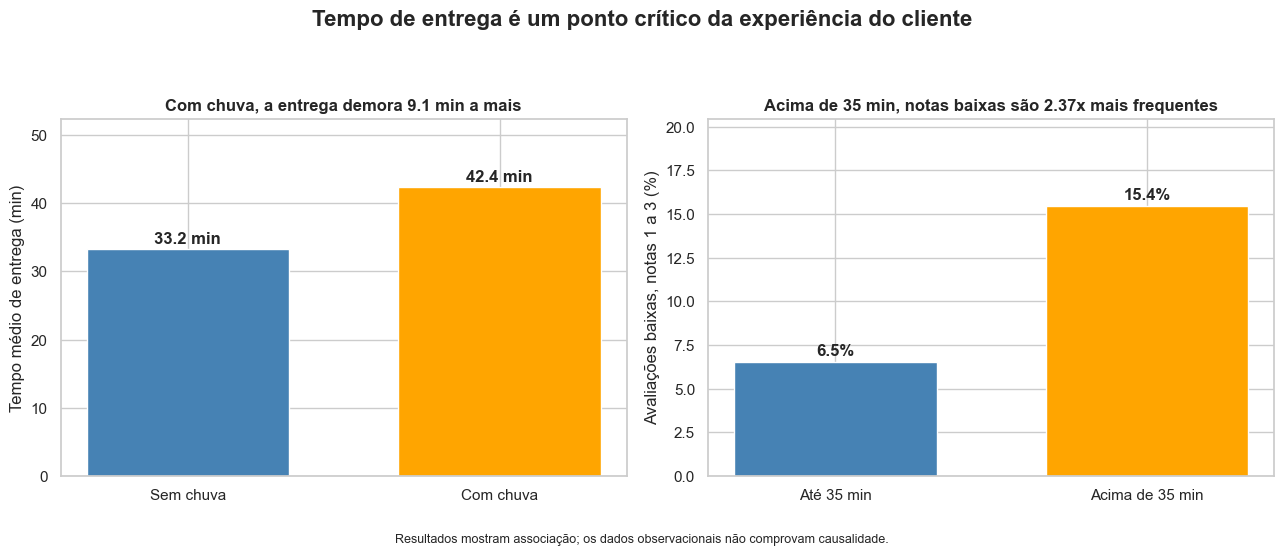

In [74]:
# ============================================================
# TAREFA 10.1 - FIGURA PRINCIPAL
# ============================================================
import os
os.makedirs("saidas", exist_ok=True)

# Painel A: chuva e tempo médio de entrega
tempo_com_chuva = df.loc[df["chuva"] == True, "tempo_entrega_min"].dropna()
tempo_sem_chuva = df.loc[df["chuva"] == False, "tempo_entrega_min"].dropna()
media_com_chuva = tempo_com_chuva.mean()
media_sem_chuva = tempo_sem_chuva.mean()
diferenca_chuva = media_com_chuva - media_sem_chuva

# Painel B: tempo de entrega e avaliações baixas (notas 1 a 3)
avaliacoes = df[["tempo_entrega_min", "avaliacao"]].dropna().copy()
notas_ate_35 = avaliacoes.loc[avaliacoes["tempo_entrega_min"] <= 35, "avaliacao"]
notas_acima_35 = avaliacoes.loc[avaliacoes["tempo_entrega_min"] > 35, "avaliacao"]
pct_baixa_ate_35 = (notas_ate_35 <= 3).mean() * 100
pct_baixa_acima_35 = (notas_acima_35 <= 3).mean() * 100
razao_baixas = pct_baixa_acima_35 / pct_baixa_ate_35

fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle("Tempo de entrega é um ponto crítico da experiência do cliente", fontsize=16, fontweight="bold")

b1 = eixos[0].bar(["Sem chuva", "Com chuva"], [media_sem_chuva, media_com_chuva], color=["steelblue", "orange"], width=0.65)
eixos[0].set_title(f"Com chuva, a entrega demora {diferenca_chuva:.1f} min a mais", fontweight="bold")
eixos[0].set_ylabel("Tempo médio de entrega (min)")
eixos[0].set_ylim(0, media_com_chuva + 10)
for barra, valor in zip(b1, [media_sem_chuva, media_com_chuva]):
    eixos[0].text(barra.get_x() + barra.get_width()/2, barra.get_height()+0.8, f"{valor:.1f} min", ha="center", fontweight="bold")

b2 = eixos[1].bar(["Até 35 min", "Acima de 35 min"], [pct_baixa_ate_35, pct_baixa_acima_35], color=["steelblue", "orange"], width=0.65)
eixos[1].set_title(f"Acima de 35 min, notas baixas são {razao_baixas:.2f}x mais frequentes", fontweight="bold")
eixos[1].set_ylabel("Avaliações baixas, notas 1 a 3 (%)")
eixos[1].set_ylim(0, pct_baixa_acima_35 + 5)
for barra, valor in zip(b2, [pct_baixa_ate_35, pct_baixa_acima_35]):
    eixos[1].text(barra.get_x()+barra.get_width()/2, barra.get_height()+0.4, f"{valor:.1f}%", ha="center", fontweight="bold")

fig.text(0.5, 0.01, "Resultados mostram associação; os dados observacionais não comprovam causalidade.", ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.05, 1, 0.92])
plt.savefig("saidas/figura_principal.png", dpi=180, bbox_inches="tight")
plt.show()


### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

### 1. A chuva está associada a entregas mais demoradas

Os pedidos realizados com chuva tiveram tempo médio de entrega de **42,36 minutos**, contra **33,23 minutos** sem chuva, uma diferença de **9,13 minutos**, com efeito grande (d de Cohen = 0,89). Esse resultado veio da **Tarefa 9.1 — H1** e importa porque mostra que os dias de chuva representam uma condição operacional relevante para o tempo de entrega.

### 2. Entregas mais demoradas estão associadas a avaliações piores

Nas entregas de até 35 minutos, **6,5%** das avaliações foram notas de 1 a 3. Acima de 35 minutos, esse percentual subiu para **15,4%**, tornando as avaliações baixas aproximadamente **2,37 vezes mais frequentes**. Esse resultado veio da **Tarefa 9.3 — H3** e importa porque relaciona o desempenho operacional à experiência do cliente.

### 3. Pedidos com cupom apresentaram ticket típico menor

O ticket mediano foi de **R\$ 57,22** nos pedidos com cupom e de **R\$ 62,82** nos pedidos sem cupom, uma diferença de **R\$ 5,60**. Esse resultado veio da **Tarefa 9.2 — H2** e importa porque o uso de cupom não veio acompanhado de um ticket maior. A base, porém, não informa o valor do desconto nem o custo da campanha, então não permite concluir se os cupons são financeiramente vantajosos.

### 4. Julho apresentou uma utilização de cupons muito acima dos demais meses

Em julho, **45,62%** dos pedidos utilizaram cupom, contra uma média de aproximadamente **18,50%** nos outros meses, ou cerca de **2,5 vezes mais**. Esse resultado veio das **Tarefas 6.7 e 7.8** e coincide com a campanha "Julho de cupons". Como a base não informa quem recebeu cupom nem as regras da campanha, não posso afirmar que a campanha sozinha causou esse aumento.

### 5. O tipo de cozinha está fortemente associado ao valor do pedido

As medianas do valor dos pedidos variaram de aproximadamente **R\$ 38,42 a R\$ 107,97** entre os tipos de cozinha, e o teste de Kruskal-Wallis apresentou tamanho de efeito de aproximadamente **ε² = 0,41**. Esse resultado veio da **Tarefa 9.4 — H4** e importa porque mostra que o tipo de cozinha é uma característica relevante para entender as diferenças de ticket entre os pedidos.


### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

### 1. Criar um plano operacional para dias de chuva

Com base nos Achados 1 e 2, recomendo preparar a operação para os dias com previsão de chuva, revisando a disponibilidade de entregadores, acompanhando os pedidos em andamento e priorizando aqueles que se aproximarem de 35 minutos. Nos dados analisados, a chuva esteve associada a um aumento médio de 9,13 minutos no tempo de entrega, enquanto avaliações baixas foram 2,37 vezes mais frequentes nas entregas acima de 35 minutos.

A principal métrica para acompanhar será o **percentual de entregas acima de 35 minutos em dias de chuva**. Também acompanharei o tempo médio e mediano, o percentual acima de 45 minutos e a proporção de avaliações de 1 a 3.

Os dados não permitem calcular quantos entregadores adicionais seriam necessários, porque a base não informa a capacidade operacional nem a quantidade de entregadores disponíveis.

### 2. Monitorar pedidos que entrarem na faixa de 35 a 40 minutos

Com base no Achado 2 e na Tarefa 7.7, recomendo utilizar a faixa de 35 a 40 minutos como uma zona de atenção operacional. Pedidos dentro dessa faixa devem ser acompanhados, e aqueles acima de 40 minutos devem receber prioridade, especialmente quando estiverem próximos de ultrapassar a promessa de 45 minutos.

A métrica principal será o **percentual de pedidos que ultrapassam 35 minutos**. Como indicadores de resultado, acompanharei o percentual de avaliações de 1 a 3, a nota média e a quantidade de pedidos acima de 40 e 45 minutos.

Essa recomendação busca reduzir a exposição a atrasos, mas os dados mostram associação, e não provam que o tempo de entrega seja a única causa das avaliações baixas.

### 3. Avaliar as campanhas de cupom pelo retorno financeiro e pela retenção

Com base nos Achados 3 e 4, recomendo que as próximas campanhas registrem o valor do desconto, o custo da campanha, a regra de concessão e a identificação dos clientes novos e recorrentes. O ticket mediano dos pedidos com cupom foi R\$ 5,60 menor, enquanto julho apresentou utilização de cupons aproximadamente 2,5 vezes maior que a média dos outros meses.

A métrica financeira principal será a **receita líquida por pedido após o desconto**. Também acompanharei o valor médio do desconto, a margem por pedido, o percentual de clientes novos e as taxas de recompra em 30, 60 e 90 dias.

A base atual não contém o valor do desconto nem o custo da campanha. Por isso, ainda não é possível concluir se os cupons geraram retorno financeiro positivo.


### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

### 1. Os dados mostram associações, mas não comprovam causalidade

Esta análise utiliza dados observacionais de pedidos realizados em 2024, e não um experimento controlado. Por isso, mesmo quando encontrei diferenças estatisticamente significativas, não posso afirmar que uma variável seja isoladamente a causa da outra. Por exemplo, os pedidos com chuva apresentaram tempo médio de entrega 9,13 minutos maior, mas esse resultado representa uma associação e não prova que a chuva sozinha tenha causado todo esse aumento.

### 2. A base não possui todas as informações operacionais que podem afetar o tempo de entrega

Não tenho informações sobre trânsito, quantidade de entregadores disponíveis, capacidade dos restaurantes, fila de pedidos ou outras ocorrências operacionais. Esses fatores podem variar junto com a chuva e também influenciar o tempo de entrega. Portanto, não consigo separar completamente o efeito de cada fator utilizando apenas esta base.

### 3. As informações sobre cupons são insuficientes para calcular o retorno financeiro das campanhas

A base informa se cada pedido utilizou cupom, mas não informa o valor do desconto, o custo da campanha, a regra de concessão nem quais clientes receberam a oferta. Por isso, embora o ticket mediano dos pedidos com cupom tenha sido R\$ 5,60 menor, não consigo concluir se as campanhas tiveram retorno financeiro positivo ou negativo.

### 4. Algumas variáveis apresentaram problemas de qualidade ou valores ausentes

Durante a preparação dos dados, identifiquei 8 tempos de entrega negativos, 25 registros com o código 999 e 7 distâncias extremamente elevadas que foram consideradas inválidas após investigação. Além disso, 1.342 pedidos não possuem avaliação e a coluna de distância também apresenta valores ausentes. Preservei os pedidos sempre que possível e mantive os valores desconhecidos como `NaN`, mas as análises que dependem dessas variáveis utilizam somente os registros com informações válidas.


---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [75]:
# ============================================================
# TAREFA 11.1 - BASE LIMPA E DICIONÁRIO DE DADOS
# ============================================================

import os

# ------------------------------------------------------------
# 1. Criar a pasta de saída, caso ela ainda não exista
# ------------------------------------------------------------
os.makedirs("saidas", exist_ok=True)

# ------------------------------------------------------------
# 2. Definir as colunas auxiliares que não serão publicadas
# ------------------------------------------------------------
# Estas colunas foram úteis nas análises, mas são derivadas
# de outras variáveis ou foram criadas apenas para cálculos.
colunas_auxiliares = [
    "data",
    "mes",
    "hora",
    "dia_semana",
    "razao_mediana",
    "pedido_grande"
]

# ------------------------------------------------------------
# 3. Verificar quais colunas auxiliares realmente existem
# ------------------------------------------------------------
colunas_para_remover = []

for coluna in colunas_auxiliares:
    if coluna in df.columns:
        colunas_para_remover.append(coluna)

# ------------------------------------------------------------
# 4. Criar uma cópia da base tratada
# ------------------------------------------------------------
# O DataFrame df usado nas análises não é alterado.
df_limpo = df.drop(columns=colunas_para_remover).copy()

# ------------------------------------------------------------
# 5. Salvar a base limpa
# ------------------------------------------------------------
caminho_base_limpa = "saidas/delivery_pedidos_limpo.csv"

df_limpo.to_csv(
    caminho_base_limpa,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 6. Gerar automaticamente o dicionário de dados
# ------------------------------------------------------------
dicionario = []

for coluna in df_limpo.columns:
    tipo = str(df_limpo[coluna].dtype)
    pct_faltantes = df_limpo[coluna].isna().mean() * 100
    valores_validos = df_limpo[coluna].dropna()

    if len(valores_validos) > 0:
        exemplo = valores_validos.iloc[0]
    else:
        exemplo = "Sem exemplo"

    dicionario.append({
        "coluna": coluna,
        "tipo": tipo,
        "% faltantes": round(pct_faltantes, 2),
        "exemplo": exemplo
    })

dicionario_dados = pd.DataFrame(dicionario)

# ------------------------------------------------------------
# 7. Fazer as conferências finais
# ------------------------------------------------------------
print("=== BASE LIMPA ===")
print("Linhas:", df_limpo.shape[0])
print("Colunas:", df_limpo.shape[1])
print("Colunas auxiliares removidas:", colunas_para_remover)
print("Arquivo salvo em:", caminho_base_limpa)

print("\n=== DICIONÁRIO DE DADOS ===")
display(dicionario_dados)


=== BASE LIMPA ===
Linhas: 8058
Colunas: 18
Colunas auxiliares removidas: ['data', 'mes', 'hora', 'dia_semana', 'razao_mediana', 'pedido_grande']
Arquivo salvo em: saidas/delivery_pedidos_limpo.csv

=== DICIONÁRIO DE DADOS ===


,coluna,tipo,% faltantes,exemplo
0,pedido_id,int64,0.00,500000
1,data_hora,datetime64[ns],0.00,2024-01-01 11:21:00
2,cidade,object,0.00,São Paulo
3,bairro,object,0.00,Tatuapé
4,restaurante_id,object,0.00,R912
5,tipo_cozinha,object,0.00,Hambúrguer
6,plataforma,object,0.00,Android
7,forma_pagamento,object,0.00,Pix
8,cupom,bool,0.00,False
9,cliente_novo,bool,0.00,False


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

## Principais achados

![Figura principal](saidas/figura_principal.png)

*Painel esquerdo: tempo médio de entrega com e sem chuva; painel direito: percentual de avaliações de 1 a 3 por faixa de tempo. Base analisada: 8.058 pedidos de 2024.*

1. **Chuva e tempo de entrega:** pedidos com chuva apresentaram tempo médio de **42,36 minutos**, contra **33,23 minutos** sem chuva, uma diferença de **9,13 minutos**. Na Tarefa 9.1, o tamanho de efeito foi grande (d de Cohen = 0,89), o que destaca a chuva como uma condição operacional relevante.

2. **Tempo de entrega e avaliação:** avaliações de 1 a 3 representaram **6,5%** das entregas de até 35 minutos e **15,4%** das entregas acima de 35 minutos, ficando aproximadamente **2,37 vezes mais frequentes** no segundo grupo. O resultado da Tarefa 9.3 liga desempenho operacional à experiência do cliente.

3. **Cupom e ticket:** o ticket mediano foi de **R$ 57,22** nos pedidos com cupom e **R$ 62,82** nos pedidos sem cupom, diferença de **R$ 5,60**. A Tarefa 9.2 mostra associação entre cupom e ticket típico menor, mas a base não possui o valor do desconto nem o custo da campanha, portanto não permite concluir se os cupons tiveram retorno financeiro positivo.

4. **Julho de cupons:** em julho, **45,62%** dos pedidos utilizaram cupom, contra aproximadamente **18,50%** nos demais meses, cerca de **2,5 vezes mais**. O comportamento observado nas Tarefas 6.7 e 7.8 coincide com a campanha “Julho de cupons”, mas os dados não permitem atribuir causalidade à campanha.

5. **Tipo de cozinha e ticket:** as medianas do valor dos pedidos variaram de aproximadamente **R$ 38,42 a R$ 107,97** entre os tipos de cozinha, com tamanho de efeito de aproximadamente **ε² = 0,41** no Kruskal-Wallis da Tarefa 9.4. O mix de cozinha é relevante para entender diferenças de ticket.

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [x] Repositório Git criado e repositório público.
- [x] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [x] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [x] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [x] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |